# Track identification with PyG HGT

Copy of the nonuniform order-of-battle base-rate experiment. The evidential-only heads,
KG-valid RAO vocabulary, open-set inputs, and 10:1 order-of-battle priors are retained.

Run from this repository's root or `notebooks/` directory. Install the original
notebook dependencies plus `torch-geometric>=2.5,<3` in the notebook kernel.

This notebook **loads existing inputs only**: the original generated dataset, saved
KG JSON, `graph_construction_outputs.pt`, `relational_graph_outputs.pt`, and the
feature memmap referenced by the graph artifact. Run the source notebook first if
these are missing. No graph or dataset generation is performed here.

Training outputs go to `artifacts/track_hgt`; original artifacts are never saved over.
The best checkpoint minimizes **test loss** (fixed full KL weight) after each completed
epoch, including optional continuation, and is reloaded before final evaluation.
Since test data selects the model, test scores are selection scores; the untouched
validation split supplies the final independent evaluation.

PyG HGTConv uses one shared node type (`node`) and one typed edge per saved relation,
so it consumes the exact original relation partitions without duplicating node features.
Its attention normalizes across incoming edges; it does not accept the former
per-relation edge chunking. Reduce `TRACKS_PER_BATCH` if necessary. Mixed precision,
non-reentrant activation checkpointing, memmapped features, streaming training-time
metrics, and pageable CPU graph batches limit memory pressure. Static relation partitions and total
incoming degrees are cached once per batch. Relations with repeated source nodes
reuse their dense transforms; bounded source lookups and shared edge storage avoid
duplicating the graph cache.


## Load the original experiment inputs


In [2]:
from __future__ import annotations
# Major step: Configure notebook dependencies, paths, logging, and helpers

import hashlib, json, logging, math, os, random, sys, time, warnings
from logging.handlers import RotatingFileHandler
import urllib.error, urllib.parse, urllib.request
from collections import Counter, defaultdict
from datetime import UTC, datetime
from pathlib import Path
from typing import Any
import gc
import matplotlib.pyplot as plt
import mlflow
from mlflow.exceptions import MlflowException
import numpy as np
import torch
import torch.utils.checkpoint
from torch import nn
import torch.nn.functional as F

_NOTEBOOK_SETUP_STARTED_AT = time.perf_counter()

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from rgcn_fusion.data_privacy import ground_truth_paths, strip_ground_truth
from esm_observation_series_generator import load_observation_series_json
from torch_geometric.nn import HGTConv
from rgcn_fusion.track_hgt_optimisation import (
    prepare_relation_graph, aggregate_relation_messages,
)
from rgcn_fusion.graph_optimisation import (
    build_track_graph_batches_by_split,
    segment_softmax,
)
DATA_PATH = ROOT / "generated" / "demo_esm_observation_series_open_set_ufo.json"
SOURCE_ARTIFACT_DIR = ROOT / "artifacts" / "Track_identification_open_set_ufo_no_unknown_output_non_uniform_base_rate"
GRAPH_INPUT_ARTIFACT = SOURCE_ARTIFACT_DIR / "graph_construction_outputs.pt"
RELATIONAL_GRAPH_ARTIFACT = SOURCE_ARTIFACT_DIR / "relational_graph_outputs.pt"
KG_JSON = ROOT / "generated" / "aircraft_radar_kg.json"
for required in (DATA_PATH, KG_JSON, GRAPH_INPUT_ARTIFACT, RELATIONAL_GRAPH_ARTIFACT):
    if not required.is_file():
        raise FileNotFoundError(f"Required source input missing: {required}. Run the source notebook first.")
ARTIFACT_DIR = ROOT / "artifacts" / "track_hgt"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Use SQLite by default because recent MLflow releases place filesystem tracking
# stores in maintenance mode. Lightweight installations without SQL support fall
# back to an explicitly opted-in local filesystem store.
MLFLOW_DB_PATH = (ARTIFACT_DIR / "mlflow.db").resolve()
MLFLOW_RUNS_PATH = (ARTIFACT_DIR / "mlruns").resolve()
MLFLOW_RUNS_PATH.mkdir(parents=True, exist_ok=True)
MLFLOW_FALLBACK_URI = MLFLOW_RUNS_PATH.as_uri()
MLFLOW_DEFAULT_URI = "sqlite:///" + MLFLOW_DB_PATH.as_posix()
MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", MLFLOW_DEFAULT_URI)
MLFLOW_EXPERIMENT_NAME = os.getenv("MLFLOW_EXPERIMENT_NAME", "track-hgt")
MLFLOW_RUN_NAME = os.getenv("MLFLOW_RUN_NAME", f"track-rgcn-{datetime.now(UTC):%Y%m%dT%H%M%SZ}")


def configure_mlflow_tracking(configured_uri, fallback_uri):
    """Configure MLflow, falling back when a lightweight install lacks SQL stores."""
    configured_scheme = urllib.parse.urlparse(configured_uri).scheme.split("+", 1)[0]
    if configured_scheme in {"", "file"}:
        # MLflow 3.10+ requires an explicit opt-in for its maintenance-mode file store.
        os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
    mlflow.set_tracking_uri(configured_uri)
    try:
        mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)
    except MlflowException as error:
        database_scheme = urllib.parse.urlparse(configured_uri).scheme.split("+", 1)[0]
        database_schemes = {"sqlite", "mysql", "postgresql", "mssql"}
        if database_scheme not in database_schemes or "unsupported URI" not in str(error):
            raise
        warnings.warn(
            f"MLflow cannot use {configured_uri!r} in this installation. "
            "Falling back to the local file-backed MLflow store at "
            f"{fallback_uri!r}. Install the full 'mlflow' package to use a SQL backend.",
            RuntimeWarning,
            stacklevel=2,
        )
        os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
        mlflow.set_tracking_uri(fallback_uri)
        mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)
        return fallback_uri
    return configured_uri


MLFLOW_TRACKING_URI = configure_mlflow_tracking(
    MLFLOW_TRACKING_URI, MLFLOW_FALLBACK_URI
)


def log_numeric_results(values, prefix, *, step=None):
    """Flatten nested numerical results and log finite values as MLflow metrics."""
    metrics = {}
    def collect(value, path):
        if isinstance(value, dict):
            for key, child in value.items():
                collect(child, f"{path}.{key}" if path else str(key))
        elif isinstance(value, (int, float, np.integer, np.floating)) and not isinstance(value, bool):
            numeric_value = float(value)
            if math.isfinite(numeric_value):
                metrics[path] = numeric_value
    collect(values, prefix)
    if metrics:
        mlflow.log_metrics(metrics, step=step)

print(DATA_PATH)
print(ARTIFACT_DIR)
print(DEVICE)

def clean():
    while gc.collect()<0:
        gc.collect()<0
    return

def load_track_dataset(path: Path) -> tuple[
    list[dict[str, Any]],
    list[dict[str, Any]],
    dict[str, dict[str, Any]],
    list[dict[str, Any]],
]:
    """Load inference records and isolated evaluation labels from a series file."""
    raw_data = load_observation_series_json(path)
    loaded_series = raw_data["observation_series"]
    inference_view = strip_ground_truth(loaded_series)
    track_targets = {
        series["series_id"]: dict(series["ground_truth_track_label"])
        for series in loaded_series
    }
    if len(track_targets) != len(loaded_series):
        raise ValueError(
            "series_id values must be unique to report correct track identifications"
        )

    observation_targets = []
    for series in loaded_series:
        for observation in series["observations"]:
            truth = observation["ground_truth_label"]
            observation_targets.append({
                "observation_id": observation["observation_id"],
                "series_id": observation["series_id"],
                "sequence_index": observation["sequence_index"],
                "aircraft_variant": truth.get("aircraft_variant"),
                "radar_mode": truth.get("mode") or truth.get("radar_mode"),
                "radar_type": truth.get("radar") or truth.get("radar_type"),
                "operator_country": truth.get("operator") or truth.get("operator_country"),
            })
    return loaded_series, inference_view, track_targets, observation_targets

# A single append-only rotating log follows the complete notebook run without allowing
# repeated setup-cell execution to attach duplicate handlers or event callbacks.
LOG_FILE = ARTIFACT_DIR / "track_identification_non_radar_rf_evidential_only.log"
NOTEBOOK_LOGGER = logging.getLogger("track_identification.non_radar_rf.notebook")
NOTEBOOK_LOGGER.setLevel(logging.INFO)
NOTEBOOK_LOGGER.propagate = False
for _handler in tuple(NOTEBOOK_LOGGER.handlers):
    _handler.close()
    NOTEBOOK_LOGGER.removeHandler(_handler)
_log_handler = RotatingFileHandler(
    LOG_FILE, maxBytes=5_000_000, backupCount=3, encoding="utf-8"
)
_log_handler.setFormatter(logging.Formatter(
    "%(asctime)s | %(levelname)s | %(name)s | %(message)s"
))
NOTEBOOK_LOGGER.addHandler(_log_handler)
NOTEBOOK_LOGGER.info("STARTED major step: Configure notebook dependencies, paths, logging, and helpers")
logging.captureWarnings(True)
_warnings_logger = logging.getLogger("py.warnings")
_warnings_logger.setLevel(logging.WARNING)
_warnings_logger.propagate = False
for _handler in tuple(_warnings_logger.handlers):
    _handler.close()
    _warnings_logger.removeHandler(_handler)
_warnings_logger.addHandler(_log_handler)

_CELL_TIMERS = {}


def _major_step_name(raw_cell):
    """Return the explicit major-step label embedded in every executable cell."""
    for line in raw_cell.splitlines():
        if line.startswith("# Major step:"):
            return line.partition(":")[2].strip()
    return "Unnamed notebook step"


def _log_cell_start(info):
    """Start wall-clock timing and log progress immediately before a cell runs."""
    step = _major_step_name(info.raw_cell)
    _CELL_TIMERS[id(info)] = (time.perf_counter(), step)
    # Keep a fallback because IPython may create a distinct ExecutionInfo wrapper.
    _CELL_TIMERS["active"] = (time.perf_counter(), step)
    NOTEBOOK_LOGGER.info("STARTED major step: %s", step)


def _log_cell_finish(result):
    """Log completion/error status and always report total cell time inline."""
    started_at, step = _CELL_TIMERS.pop(id(result.info), _CELL_TIMERS.get("active", (time.perf_counter(), _major_step_name(result.info.raw_cell))))
    _CELL_TIMERS.pop("active", None)
    elapsed = time.perf_counter() - started_at
    error = result.error_before_exec or result.error_in_exec
    if error is None:
        NOTEBOOK_LOGGER.info("COMPLETED major step: %s | total_time_seconds=%.6f", step, elapsed)
        status = "completed"
    else:
        NOTEBOOK_LOGGER.error("FAILED major step: %s | total_time_seconds=%.6f", step, elapsed,
                              exc_info=(type(error), error, error.__traceback__))
        status = f"failed ({type(error).__name__})"
    print(f"[timing] {step} - {status}; total time: {elapsed:.3f} seconds")


ipython = globals().get("get_ipython", lambda: None)()
if ipython is not None:
    for event_name, previous_name in (("pre_run_cell", "_TRACK_LOG_PREVIOUS_PRE"),
                                      ("post_run_cell", "_TRACK_LOG_PREVIOUS_POST")):
        previous = globals().get(previous_name)
        if previous is not None:
            try:
                ipython.events.unregister(event_name, previous)
            except ValueError:
                pass
    ipython.events.register("pre_run_cell", _log_cell_start)
    ipython.events.register("post_run_cell", _log_cell_finish)
    _TRACK_LOG_PREVIOUS_PRE = _log_cell_start
    _TRACK_LOG_PREVIOUS_POST = _log_cell_finish
else:
    warnings.warn("IPython event hooks are unavailable; subsequent cell timing is disabled.", RuntimeWarning)

_setup_elapsed = time.perf_counter() - _NOTEBOOK_SETUP_STARTED_AT
NOTEBOOK_LOGGER.info("COMPLETED major step: Configure notebook dependencies, paths, logging, and helpers | total_time_seconds=%.6f", _setup_elapsed)
print(f"Log file: {LOG_FILE}")
print(f"[timing] Configure notebook dependencies, paths, logging, and helpers - completed; total time: {_setup_elapsed:.3f} seconds")



C:\Users\theon\r-GCN_fusion\generated\demo_esm_observation_series_open_set_ufo.json
C:\Users\theon\r-GCN_fusion\artifacts\track_hgt
cuda
Log file: C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_identification_non_radar_rf_evidential_only.log
[timing] Configure notebook dependencies, paths, logging, and helpers - completed; total time: 9.521 seconds
[timing] Configure notebook dependencies, paths, logging, and helpers - completed; total time: 0.000 seconds


In [3]:
# Major step: Progress logging and cell timing - clean()
clean()

[timing] Progress logging and cell timing - clean() - completed; total time: 0.258 seconds


## Load series and create a label-free inference view

Ground-truth fields are retained in a separate target table, but are recursively stripped from the feature payload before graph construction. This prevents leakage from `ground_truth_label`, `ground_truth_track_label`, and `ground_truth_mode_sequence` into node features or edges.



In [4]:
# Major step: Load series and create a label-free inference view
LEAKAGE_KEYS = {"ground_truth_label", "ground_truth_track_label", "ground_truth_mode_sequence", "synthetic_truth_value"}
TARGETS = ["aircraft_variant", "radar_mode", "radar_type", "operator_country"]

series_records, inference_records, track_targets_by_series_id, target_rows = (
    load_track_dataset(DATA_PATH)
)

leaked_truth_paths = ground_truth_paths(inference_records)
assert not leaked_truth_paths, (
    f"Ground-truth fields leaked into inference view: {leaked_truth_paths[:5]}"
)
report_count = sum(len(series.get("intelligence_reports") or []) for series in series_records)
print(f"series={len(series_records):,}, observations={len(target_rows):,}, intelligence_reports={report_count:,}")
print(target_rows[0])



series=16,000, observations=744,481, intelligence_reports=183,776
{'observation_id': 'esm_series_00001_obs_001', 'series_id': 'esm_series_00001', 'sequence_index': 0, 'aircraft_variant': 'Su-30SM', 'radar_mode': 'OFF', 'radar_type': 'N011M Bars', 'operator_country': 'Belarus'}
[timing] Load series and create a label-free inference view - completed; total time: 223.936 seconds


## Feature engineering with proximity-linked intelligence and KG entities

Observation features include measured radar ESM and the new `rf_emissions` payload, plus kinematics, time, and location. Non-radar emissions are never treated as radar modes: data links, radios, and radar altimeters are matched to equipment carried by each aircraft candidate, and their compatibility becomes a separate evidence channel. Sighting reports are connected only where their reported time and coordinates are close to an observation; pattern-of-life reports use collection time and expected operating area. Structured aircraft, family, radar, and operator claims also connect directly to the corresponding existing KG entity nodes, allowing the NN to propagate report evidence through the domain graph.


In [5]:
# Major step: Feature engineering with proximity-linked intelligence and KG entities
INCLUDE_CANDIDATE_NODES = True
INCLUDE_INTEL_REPORT_NODES = True
USE_SEGMENT_EDGES = False
SEGMENT_FREQUENCY_SHIFT_GHZ = 0.75

MAX_KG_RETRIEVAL_CANDIDATES = 320
MAX_KG_CANDIDATES = 18
# Discard weak claim/candidate links and keep only claim -> candidate direction.
CLAIM_CANDIDATE_MIN_ABS_CONTRIBUTION = 0.15
COLLAPSE_RECIPROCAL_CLAIM_CANDIDATE_EDGES = True


[timing] Feature engineering with proximity-linked intelligence and KG entities - completed; total time: 0.002 seconds


In [6]:
# Major step: Load saved KG and recover the original valid joint frame
kg = json.loads(KG_JSON.read_text(encoding="utf-8"))
kg_nodes = {node["id"]: node for node in kg["nodes"]}
radar_by_mode = {edge["target"]: edge["source"] for edge in kg["edges"] if edge["relation"] == "HAS_MODE"}
aircraft_by_radar: dict[str, list[str]] = defaultdict(list)
operators_by_aircraft: dict[str, list[str]] = defaultdict(list)
aircraft_family_by_aircraft: dict[str, str] = {}
rf_equipment_by_aircraft: dict[str, list[dict[str, Any]]] = defaultdict(list)
RF_RELATION_TO_TYPE = {
    "USES_DATA_LINK": "data_link",
    "USES_RADIO": "radio",
    "USES_RADAR_ALTIMETER": "radar_altimeter",
}
for edge in kg["edges"]:
    if edge["relation"] == "USES_RADAR":
        aircraft_by_radar[edge["target"]].append(edge["source"])
    elif edge["relation"] == "OPERATES":
        operators_by_aircraft[edge["target"]].append(kg_nodes[edge["source"]]["properties"].get("name"))
    elif edge["relation"] == "VARIANT_OF":
        aircraft_family_by_aircraft[edge["source"]] = edge["target"]
    elif edge["relation"] in RF_RELATION_TO_TYPE:
        equipment_node = kg_nodes[edge["target"]]
        rf_equipment_by_aircraft[edge["source"]].append({
            "emission_type": RF_RELATION_TO_TYPE[edge["relation"]],
            "equipment_id": edge["target"],
            **equipment_node.get("properties", {}),
        })
kg_candidate_rows = [
    {
        "mode_id": mode_id, "mode_props": kg_nodes[mode_id]["properties"],
        "radar_id": radar_id, "radar_props": kg_nodes[radar_id]["properties"],
        "aircraft_id": aircraft_id,
        "aircraft_props": kg_nodes[aircraft_id]["properties"] if aircraft_id else None,
        "aircraft_uses_radar": aircraft_id is not None, "operator": operator,
        "rf_equipment": rf_equipment_by_aircraft.get(aircraft_id, []),
    }
    for mode_id, radar_id in radar_by_mode.items()
    for aircraft_id in (aircraft_by_radar.get(radar_id) or [None])
    for operator in (operators_by_aircraft.get(aircraft_id, [None]) if aircraft_id else [None])
    if aircraft_id not in {"aircraft:j_40", "aircraft:j_35", "aircraft:su_75"}
]

# A radar can legitimately have modes in the KG without any USES_RADAR edge from an
# aircraft.  The ``or [None]`` fallback above preserves such a radar-only hypothesis;
# it is the source of CandidateScore.aircraft_id == None (not a missing dictionary key).
radars_without_aircraft = sum(not aircraft_by_radar.get(radar_id) for radar_id in radar_by_mode.values())
print(f"Radar-only candidate fallback used for {radars_without_aircraft:,} radar mode(s)")

def key_text(value: Any, field_name: str) -> str:
    """Validate and narrow a required JSON-derived identifier for a hash key."""
    if not isinstance(value, str):
        raise TypeError(f"{field_name} must be a string, got {type(value).__name__}")
    return value


def optional_key_text(value: Any, field_name: str) -> str | None:
    """Validate and narrow an optional JSON-derived identifier for a hash key."""
    return None if value is None else key_text(value, field_name)


# Elementary DS worlds are complete, mutually exclusive KG-valid configurations.
# Aircraft family is projected from the joint frame rather than trained as an
# unrelated head, preserving its deterministic relationship to the variant.
kg_valid_worlds = []
seen_kg_worlds = set()
for row in kg_candidate_rows:
    if not row["aircraft_id"] or not row["operator"]:
        continue
    world = {
        "radar_mode": row["mode_props"].get("name"),
        "radar_type": row["radar_props"].get("name"),
        "aircraft_variant": row["aircraft_props"].get("variant"),
        "aircraft_family": row["aircraft_props"].get("family"),
        "operator_country": row["operator"],
    }
    key = tuple(
        key_text(world[name], name)
        for name in ("radar_mode", "radar_type", "aircraft_variant", "aircraft_family", "operator_country")
    )
    if key not in seen_kg_worlds:
        seen_kg_worlds.add(key)
        kg_valid_worlds.append(world)
print(f"KG-valid joint frame: {len(kg_valid_worlds):,} elementary worlds")



Radar-only candidate fallback used for 0 radar mode(s)
KG-valid joint frame: 732 elementary worlds
[timing] Load saved KG and recover the original valid joint frame - completed; total time: 0.012 seconds


## Reuse saved features and relation edges

Candidate scoring and graph construction are skipped.


In [7]:
# Major step: Candidate-generation Recall@K - part 4
# Reload graph-construction outputs instead of rebuilding the feature and evidence nodes.

graph_outputs = torch.load(GRAPH_INPUT_ARTIFACT, map_location="cpu", weights_only=False)
if graph_outputs.get("version") != 8:
    raise ValueError(f"Unsupported graph-construction artifact: {GRAPH_INPUT_ARTIFACT}")
feature_matrix = graph_outputs["feature_matrix"]
feature_matrix_path = SOURCE_ARTIFACT_DIR / feature_matrix["path"]
X_np = np.memmap(
    feature_matrix_path, mode="c", dtype=np.dtype(feature_matrix["dtype"]),
    shape=tuple(feature_matrix["shape"]),
)
X = torch.from_numpy(X_np)  # mini-batches cast only local nodes
feature_names = graph_outputs["feature_names"]
observation_segment_indices = graph_outputs["observation_segment_indices"]
node_meta = graph_outputs["node_meta"]
observation_node_indices = graph_outputs["observation_node_indices"]
candidates_by_observation_node = defaultdict(list, graph_outputs["candidates_by_observation_node"])
reports_by_observation_node = defaultdict(list, graph_outputs["reports_by_observation_node"])
claims_by_observation_node = defaultdict(list, graph_outputs["claims_by_observation_node"])
claims_by_claim_type = defaultdict(list, graph_outputs["claims_by_claim_type"])
claim_candidate_signed_claim_index = graph_outputs["claim_candidate_signed_claim_index"]
claim_candidate_node_index = graph_outputs["claim_candidate_node_index"]
kg_entity_node_indices = graph_outputs["kg_entity_node_indices"]
report_kg_edges = graph_outputs["report_kg_edges"]
print(f"Reloaded {X.size(0):,} nodes, {X.size(1):,} features from {GRAPH_INPUT_ARTIFACT}")

# Copy-on-write mapping protects the persisted source features while exposing a
# writable tensor view; training never mutates X.
for name in ("include_candidate_nodes", "include_intel_report_nodes", "use_segment_edges",
             "segment_frequency_shift_ghz", "max_kg_retrieval_candidates", "max_kg_candidates"):
    globals()[name.upper()] = graph_outputs[name]
del graph_outputs

# Refuse a different dataset or reordered feature artifact before training.
expected_observations = {
    row["observation_id"]: row["series_id"] for row in target_rows
}
if len(observation_node_indices) != len(expected_observations):
    raise ValueError("Dataset and saved graph have different observation counts")
for node_index in observation_node_indices:
    meta = node_meta[node_index]
    if expected_observations.pop(meta["observation_id"], None) != meta["series_id"]:
        raise ValueError("Dataset observation IDs/series do not match the saved graph")
if expected_observations:
    raise ValueError("Saved graph does not cover the source dataset")
del expected_observations


del X_np
clean()

Reloaded 15,120,208 nodes, 180 features from C:\Users\theon\r-GCN_fusion\artifacts\Track_identification_open_set_ufo_no_unknown_output_non_uniform_base_rate\graph_construction_outputs.pt
[timing] Candidate-generation Recall@K - part 4 - completed; total time: 61.363 seconds


## Load the saved relational graph


In [8]:
# Reload the saved relational graph outputs without rebuilding the graph.

relational_graph_outputs = torch.load(
    RELATIONAL_GRAPH_ARTIFACT, map_location="cpu", weights_only=False
)
if relational_graph_outputs.get("version") != 1:
    raise ValueError(f"Unsupported relational graph artifact: {RELATIONAL_GRAPH_ARTIFACT}")
RELATION_NAMES = relational_graph_outputs["relation_names"]
RELATIONS = relational_graph_outputs["relations"]
edge_index = relational_graph_outputs["edge_index"]
edge_types = relational_graph_outputs["edge_types"]
relation_edge_counts = relational_graph_outputs["relation_edge_counts"]
claim_candidate_edges_retained = relational_graph_outputs["claim_candidate_edges_retained"]
contradiction_reasons = Counter(relational_graph_outputs["contradiction_reasons"])
print(f"Reloaded relational graph outputs from {RELATIONAL_GRAPH_ARTIFACT}")

del relational_graph_outputs


Reloaded relational graph outputs from C:\Users\theon\r-GCN_fusion\artifacts\Track_identification_open_set_ufo_no_unknown_output_non_uniform_base_rate\relational_graph_outputs.pt
[timing] Unnamed notebook step - completed; total time: 7.790 seconds


## Build track-level RAO and observation-level radar-mode targets

The invariant label is one joint `(aircraft_variant, radar_type, operator_country)` class per series. Radar mode remains an observation target. The 0.5/0.3/0.2 split is performed on `series_id` and stratified by the joint RAO class; no observation from a track can cross a split boundary.


In [9]:
# Major step: Build track-level RAO and observation-level radar-mode targets
RAO_FIELDS = ("aircraft_variant", "radar_type", "operator_country")
MODE_TASK = "radar_mode"

def rao_tuple(values: dict[str, Any]) -> tuple[str, str, str]:
    """Normalize either track- or observation-label naming to one RAO tuple."""
    result = (
        values.get("aircraft_variant") or values.get("aircraft"),
        values.get("radar_type") or values.get("radar"),
        values.get("operator_country") or values.get("operator"),
    )
    if any(value is None for value in result):
        raise ValueError(f"Incomplete RAO target: {values}")
    return result

# UFO tracks are open-set inputs, not a supervised output class. They remain in
# the graph for held-out uncertainty evaluation but never add an output neuron.
UFO_VARIANTS = {"J-40", "J-35", "Su-75"}
ufo_series_ids = {
    series_id for series_id, target in track_targets_by_series_id.items()
    if target.get("aircraft_variant") in UFO_VARIANTS
}
rao_target_by_series = {
    series_id: rao_tuple(target)
    for series_id, target in track_targets_by_series_id.items()
}
# Check rows in one pass and retain only the first few offending IDs. Grouping
# every target-row dictionary by series duplicated a large Python container.
mismatches_by_series: dict[str, list[str]] = defaultdict(list)
for row in target_rows:
    series_id = row["series_id"]
    row_rao = rao_tuple(row)
    if row_rao != rao_target_by_series[series_id] and len(mismatches_by_series[series_id]) < 3:
        mismatches_by_series[series_id].append(row["observation_id"])
if mismatches_by_series:
    series_id, mismatches = next(iter(mismatches_by_series.items()))
    raise ValueError(f"RAO changes inside {series_id!r}; split the track at {mismatches}")

# The RAO output vocabulary is an allow-list of KG-valid worlds, not a Cartesian product.
rao_vocab = sorted({
    tuple(world[field] for field in RAO_FIELDS)
    for world in kg_valid_worlds
})
rao_class_index = {world: index for index, world in enumerate(rao_vocab)}
assert all("unknown" not in world for world in rao_vocab)
# Preserve the compact variant taxonomy after the large KG construction objects
# are released. It is used both by hierarchical supervision and inference-time
# projection, so training and export cannot disagree about a variant's parent.
rao_family_by_variant = {}
for world in kg_valid_worlds:
    variant, family = world["aircraft_variant"], world["aircraft_family"]
    previous = rao_family_by_variant.setdefault(variant, family)
    if previous != family:
        raise ValueError(f"Aircraft variant {variant!r} has multiple KG families")
if set(rao_family_by_variant) != {world[0] for world in rao_vocab}:
    raise ValueError("Every RAO variant must have exactly one aircraft family")
non_ufo_targets_absent_from_frame = {
    value for series_id, value in rao_target_by_series.items()
    if series_id not in ufo_series_ids and value not in rao_class_index
}
if non_ufo_targets_absent_from_frame:
    raise ValueError(
        f"Known track targets absent from the KG-valid RAO frame: "
        f"{sorted(non_ufo_targets_absent_from_frame)[:3]}"
    )

mode_values = {
    row[MODE_TASK] for row in target_rows
    if row.get("aircraft_variant") not in UFO_VARIANTS
}
if None in mode_values:
    raise ValueError("Missing radar-mode labels are not supported")
mode_vocab = sorted(mode_values)
mode_class_index = {value: index for index, value in enumerate(mode_vocab)}
assert "unknown" not in mode_class_index

series_ids = sorted(rao_target_by_series)
series_index = {series_id: index for index, series_id in enumerate(series_ids)}
track_target_indices = np.fromiter(
    (rao_class_index.get(rao_target_by_series[series_id], -1) for series_id in series_ids),
    dtype=np.int64, count=len(series_ids),
)
mode_by_observation_id = {
    row["observation_id"]: row[MODE_TASK]
    for row in target_rows
}
observation_node_array = np.asarray(observation_node_indices, dtype=np.int64)
observation_track_array = np.fromiter(
    (series_index[node_meta[node_idx]["series_id"]] for node_idx in observation_node_indices),
    dtype=np.int64, count=len(observation_node_indices),
)
mode_target_indices = np.fromiter(
    ((-1 if node_meta[node_idx]["series_id"] in ufo_series_ids else
         mode_class_index[mode_by_observation_id[node_meta[node_idx]["observation_id"]]])
     for node_idx in observation_node_indices),
    dtype=np.int64, count=len(observation_node_indices),
)
# from_numpy avoids the temporary Python-int lists and the extra tensor copy made
# by torch.tensor(...); transfer each compact array to the accelerator only once.
track_targets = torch.from_numpy(track_target_indices).to(DEVICE)
observation_nodes_cpu = torch.from_numpy(observation_node_array)
observation_nodes = observation_nodes_cpu.to(DEVICE)
observation_track_index_cpu = torch.from_numpy(observation_track_array)
observation_track_index = observation_track_index_cpu.to(DEVICE)
mode_targets = torch.from_numpy(mode_target_indices).to(DEVICE)

# Compatibility[RAO, mode] is derived from the KG and is used by the conditioned mode head.
rao_mode_compatibility_array = np.zeros((len(rao_vocab), len(mode_vocab)), dtype=np.float32)
for world in kg_valid_worlds:
    rao_index = rao_class_index.get(tuple(world[field] for field in RAO_FIELDS))
    mode_index = mode_class_index.get(world[MODE_TASK])
    if rao_index is not None and mode_index is not None:
        rao_mode_compatibility_array[rao_index, mode_index] = 1.0
# Populate on the CPU and copy once: scalar assignment into a CUDA tensor launches
# one kernel per valid world and is disproportionately expensive.
rao_mode_compatibility = torch.from_numpy(rao_mode_compatibility_array).to(DEVICE)
if (rao_mode_compatibility.sum(dim=1) == 0).any():
    raise ValueError("Every RAO class must support at least one radar mode")


def stratified_track_split(
    labels_by_series: dict[str, tuple[str, str, str]],
    fractions: dict[str, float],
    seed: int,
) -> dict[str, set[str]]:
    split_names = tuple(fractions)
    desired = {name: fractions[name] * len(labels_by_series) for name in split_names}
    result: dict[str, set[str]] = {name: set() for name in split_names}
    strata: dict[tuple[str, str, str], list[str]] = defaultdict(list)
    for series_id, label in labels_by_series.items():
        strata[label].append(series_id)
    rng = np.random.default_rng(seed)
    items = list(strata.items())
    rng.shuffle(items)
    items.sort(key=lambda item: len(item[1]), reverse=True)
    for _, ids in items:
        rng.shuffle(ids)
        quota = {name: fractions[name] * len(ids) for name in split_names}
        assigned = {name: 0 for name in split_names}
        for series_id in ids:
            name = max(split_names, key=lambda key: (quota[key] - assigned[key], desired[key] - len(result[key])))
            result[name].add(series_id)
            assigned[name] += 1
    return result

known_targets_by_series = {
    series_id: target for series_id, target in rao_target_by_series.items()
    if series_id not in ufo_series_ids
}
split_series = stratified_track_split(
    known_targets_by_series, {"train": 0.5, "test": 0.3, "val": 0.2}, SEED
)
def reserve_open_set_split(known_splits, unknown_series_ids):
    """Keep unknown tracks out of all supervised partitions."""
    result = {name: set(ids) - set(unknown_series_ids) for name, ids in known_splits.items()}
    result["open_set"] = set(unknown_series_ids)
    return result


SUPERVISED_SPLITS = ("train", "test", "val")
split_series = reserve_open_set_split(split_series, ufo_series_ids)
# -1 is an invalid supervised label, retained only for aligned open-set tensors.
assert all(not (split_series[name] & ufo_series_ids) for name in SUPERVISED_SPLITS)
# Build split membership on the CPU, where graph batching consumes it, then copy
# each small index tensor to the accelerator once. This removes a GPU round trip.
track_splits_cpu = {
    name: torch.from_numpy(np.fromiter(
        (series_index[sid] for sid in series_ids if sid in ids),
        dtype=np.int64, count=len(ids),
    ))
    for name, ids in split_series.items()
}
track_splits = {name: tracks.to(DEVICE) for name, tracks in track_splits_cpu.items()}
split_names = tuple(track_splits)
split_index_by_track = np.empty(len(series_ids), dtype=np.int8)
for split_index, name in enumerate(split_names):
    split_index_by_track[track_splits_cpu[name].numpy()] = split_index
observation_split_indices = split_index_by_track[observation_track_array]
# Direct integer lookup is O(observations); torch.isin scanned the observation
# vector once per split and allocated a full-sized temporary mask each time.
observation_splits = {
    name: torch.from_numpy(np.flatnonzero(observation_split_indices == split_index)).to(DEVICE)
    for split_index, name in enumerate(split_names)
}
for name in track_splits:
    print(name, {"tracks": int(track_splits[name].numel()), "observations": int(observation_splits[name].numel())})
print({"rao_classes": len(rao_vocab), "mode_classes": len(mode_vocab)})

# Every non-KG node belongs to exactly one track; shared KG nodes use -1.
node_track_index = torch.from_numpy(np.fromiter(
    (series_index.get(meta.get("series_id"), -1) for meta in node_meta),
    dtype=np.int64, count=len(node_meta),
))
TRACKS_PER_BATCH = max(1, int(os.getenv("TRACKS_PER_BATCH", "4")))
# Index edge/observation ownership once for all splits. The former per-split calls
# repeatedly scanned every graph edge and every observation for every mini-batch.
batches_by_split = build_track_graph_batches_by_split(
    edge_index=edge_index, edge_types=edge_types, node_track_index=node_track_index,
    observation_nodes=observation_nodes_cpu, observation_track_index=observation_track_index_cpu,
    selected_tracks_by_split=track_splits_cpu, tracks_per_batch=TRACKS_PER_BATCH,
)
print({"tracks_per_batch": TRACKS_PER_BATCH,
       "split_batches": {name: len(batches) for name, batches in batches_by_split.items()}})


train {'tracks': 7176, 'observations': 333977}
test {'tracks': 4297, 'observations': 200573}
val {'tracks': 2866, 'observations': 132326}
open_set {'tracks': 1661, 'observations': 77605}
{'rao_classes': 122, 'mode_classes': 6}
{'tracks_per_batch': 4, 'split_batches': {'train': 1794, 'test': 1075, 'val': 717, 'open_set': 416}}
[timing] Build track-level RAO and observation-level radar-mode targets - completed; total time: 180.890 seconds


In [10]:
# Major step: Build track-level RAO and observation-level radar-mode targets - clean()
clean()

[timing] Build track-level RAO and observation-level radar-mode targets - clean() - completed; total time: 108.581 seconds


## Hierarchical r-GCN/PyG HGTConv encoder, track pool, and evidential-only output heads

The graph encoder is retained, but its observation embeddings are pooled by `series_id`. `TrackAttentionPool` returns one track vector. A single joint RAO evidential head operates on those vectors, making within-track identity changes impossible by construction. The radar-mode evidential head operates on each observation and receives its broadcast track vector plus a differentiable KG compatibility prior marginalized over the RAO Dirichlet mean. The vocabularies contain only KG-valid known classes, with no dedicated unknown neuron. No separate categorical/logit prediction heads are created; probabilities, predictions, and accuracies all come from the evidential heads.


In [12]:
# Major step: Configure track-specific order-of-battle base rates
# Set RAO_OOB_BASE_RATE_MULTIPLIER=1 for a uniform-prior control run.
RAO_OOB_BASE_RATE_MULTIPLIER = float(os.getenv("RAO_OOB_BASE_RATE_MULTIPLIER", "10"))
if not math.isfinite(RAO_OOB_BASE_RATE_MULTIPLIER) or RAO_OOB_BASE_RATE_MULTIPLIER < 1:
    raise ValueError("RAO_OOB_BASE_RATE_MULTIPLIER must be finite and >= 1")


def order_of_battle_base_rates(series, vocabulary, aircraft_variant_by_id, multiplier=10.0):
    """Use report membership only; never read track truth or report correctness."""
    if not math.isfinite(multiplier) or multiplier < 1:
        raise ValueError("multiplier must be finite and >= 1")
    listed_variants = set()
    report_ids = []
    for report in series.get("intelligence_reports") or []:
        if report.get("report_type") != "theatre_aircraft_report":
            continue
        report_ids.append(report.get("report_id"))
        inventory = report.get("theatre_aircraft") or {}
        listed_variants.update(inventory.get("aircraft_types") or [])
        listed_variants.update(aircraft_variant_by_id[aircraft_id]
                               for aircraft_id in inventory.get("aircraft_ids") or []
                               if aircraft_id in aircraft_variant_by_id)
        for claim in report.get("claims") or []:
            if claim.get("claim_type") == "theatre_aircraft_presence":
                listed_variants.update(aircraft_variant_by_id[aircraft_id]
                                       for aircraft_id in claim.get("object_ids") or []
                                       if aircraft_id in aircraft_variant_by_id)
    membership = np.asarray([world[0] in listed_variants for world in vocabulary], dtype=bool)
    weights = np.where(membership, multiplier, 1.0)
    rates = weights / weights.sum()
    return rates.astype(np.float32), {"source_report_ids": report_ids,
        "listed_aircraft_variants": sorted(listed_variants),
        "boosted_class_indices": np.flatnonzero(membership).tolist(),
        "multiplier": multiplier, "prior_weight": len(vocabulary),
        "fallback_uniform": not bool(membership.any())}


_aircraft_variant_by_id = {node["id"]: node["properties"]["variant"]
    for node in kg["nodes"] if node.get("label") == "AircraftVariant"}
_inference_by_series = {series["series_id"]: series for series in inference_records}
_prior_rows = [order_of_battle_base_rates(_inference_by_series[sid], rao_vocab,
    _aircraft_variant_by_id, RAO_OOB_BASE_RATE_MULTIPLIER) for sid in series_ids]
# CPU storage avoids duplicating all track priors on the accelerator.
rao_base_rates_cpu = torch.from_numpy(np.stack([row[0] for row in _prior_rows]))
rao_prior_audit = [row[1] for row in _prior_rows]
assert torch.allclose(rao_base_rates_cpu.sum(-1), torch.ones(len(series_ids)))
assert (rao_base_rates_cpu > 0).all()
(ARTIFACT_DIR / "rao_base_rate_audit.json").write_text(json.dumps({
    "rao_vocab": rao_vocab, "tracks": dict(zip(series_ids, rao_prior_audit)),
    "mapping": "alpha=e+K*a; p=b+u*a", "mode_base_rate": "uniform"}, indent=2))
del _prior_rows, _inference_by_series, _aircraft_variant_by_id
print({"oob_multiplier": RAO_OOB_BASE_RATE_MULTIPLIER,
       "tracks_with_boosted_classes": sum(not row["fallback_uniform"] for row in rao_prior_audit)})


{'oob_multiplier': 10.0, 'tracks_with_boosted_classes': 16000}
[timing] Configure track-specific order-of-battle base rates - completed; total time: 0.933 seconds


In [13]:
MAXIMUM_HIDDEN_DIM = 150
MINIMUM_HIDDEN_DIM = 100
NUM_MESSAGE_PASSING_EDGES = 20
NUM_RGCN_BASES = 6
NUM_HGT_LAYERS = 3
NUM_ATTENTION_HEADS = 4
DROPOUT = 0.35
TASK_HEAD_HIDDEN_DIM = 100
EVIDENTIAL_LOSS_WEIGHT = 0.5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
L1_LAMBDA = 5e-4
PATIENCE = 10
EARLY_STOPPING_MIN_DELTA = 1e-4
EDGE_CHUNK_SIZE = 4_000_000
METRICS_INTERVAL = max(1, int(os.getenv("METRICS_INTERVAL", "10")))
# Pinning every cached graph tensor can exhaust the CUDA host allocator on large graphs.
# Keep the memory-safe pageable path by default; opt in only when the host has ample RAM.
PIN_BATCH_MEMORY = DEVICE.type == "cuda" and os.getenv("PIN_BATCH_MEMORY", "0") == "1"

MODEL_DTYPE = torch.float32
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.float16
GRADIENT_CHECKPOINTING = False #= DEVICE.type == "cuda"

if NUM_MESSAGE_PASSING_EDGES < 1:
    raise ValueError("NUM_MESSAGE_PASSING_EDGES must be at least 1.")
if MINIMUM_HIDDEN_DIM < 1 or MAXIMUM_HIDDEN_DIM < MINIMUM_HIDDEN_DIM:
    raise ValueError("Hidden dimensions must satisfy 1 <= MINIMUM_HIDDEN_DIM <= MAXIMUM_HIDDEN_DIM.")
if MINIMUM_HIDDEN_DIM % NUM_ATTENTION_HEADS != 0:
    raise ValueError("MINIMUM_HIDDEN_DIM must be divisible by NUM_ATTENTION_HEADS for HGT attention.")


class RelationalGraphConvolutionBlock(nn.Module):
    """Residual r-GCN aggregation over prepartitioned relation edge tensors."""
    def __init__(self, in_dim, out_dim, num_relations, num_bases, dropout, edge_chunk_size=0):
        super().__init__()
        self.num_relations = max(int(num_relations), 1)
        self.num_bases = min(max(int(num_bases), 1), self.num_relations)
        self.bases = nn.Parameter(torch.empty(self.num_bases, in_dim, out_dim))
        self.coefficients = nn.Parameter(torch.empty(self.num_relations, self.num_bases))
        self.root = nn.Linear(in_dim, out_dim, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_dim))
        self.residual = nn.Identity() if in_dim == out_dim else nn.Linear(in_dim, out_dim, bias=False)
        self.norm = nn.LayerNorm(out_dim)
        self.dropout = nn.Dropout(dropout)
        if edge_chunk_size < 0:
            raise ValueError("edge_chunk_size must be non-negative")
        self.edge_chunk_size = int(edge_chunk_size)
        nn.init.xavier_uniform_(self.bases)
        nn.init.xavier_uniform_(self.coefficients)

    def forward(self, x, relation_edges):
        relation_weights = torch.einsum("rb,bio->rio", self.coefficients, self.bases)
        messages = aggregate_relation_messages(x, relation_weights, relation_edges, self.edge_chunk_size)
        updated = self.dropout(F.gelu(self.root(x) + messages + self.bias))
        return self.norm(self.residual(x) + updated)


class PyGHGTLayer(nn.Module):
    """PyG HGT on shared node features and the original relation edge types."""
    def __init__(self, hidden_dim, num_relations, num_heads, dropout, edge_chunk_size=0):
        super().__init__()
        self.edge_types = tuple(("node", f"relation_{i}", "node") for i in range(num_relations))
        self.conv = HGTConv(hidden_dim, hidden_dim,
                            metadata=(["node"], list(self.edge_types)), heads=num_heads)
        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, relation_edges):
        # Keep every relation (including empty ones) so HGT metadata stays stable.
        # The tensors are shared views; no HeteroData or feature replication.
        edges = dict(zip(self.edge_types, relation_edges.edges))
        updated = self.conv({"node": x}, edges)["node"]
        if updated is None:
            return x
        return self.norm(x + self.dropout(F.gelu(updated)))


class TrackAttentionPool(nn.Module):
    """Vectorised gated attention normalized independently inside each track."""
    def __init__(self, hidden_dim, dropout):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.Tanh(), nn.Dropout(dropout), nn.Linear(hidden_dim, 1))
        self.summary = nn.Sequential(nn.Linear(3 * hidden_dim, hidden_dim), nn.GELU(), nn.Dropout(dropout))
        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, observations, observation_to_track, num_tracks):
        counts = torch.bincount(observation_to_track, minlength=num_tracks)
        if torch.any(counts == 0):
            raise ValueError("Every mini-batch track must contain an observation")
        weights = segment_softmax(self.score(observations).squeeze(-1), observation_to_track, num_tracks)
        attentive = observations.new_zeros((num_tracks, observations.size(1)))
        means = torch.zeros_like(attentive)
        attentive_contributions = (weights.unsqueeze(-1) * observations).to(attentive.dtype)
        attentive.index_add_(0, observation_to_track, attentive_contributions)
        means.index_add_(0, observation_to_track, observations.to(means.dtype))
        means = means / counts.to(observations.dtype).unsqueeze(-1)
        maxima = observations.new_full(attentive.shape, -torch.inf)
        maxima.scatter_reduce_(0, observation_to_track[:, None].expand_as(observations), observations.to(maxima.dtype), reduce="amax", include_self=True)
        return self.norm(attentive + self.summary(torch.cat((attentive, means, maxima), dim=-1)))


class TrackRGCNHGTClassifier(nn.Module):
    """One KG-valid RAO opinion per track and one conditioned mode opinion per observation."""
    def __init__(self, in_dim, maximum_hidden_dim, minimum_hidden_dim, num_relations, num_rao_classes, num_mode_classes,
                 rao_mode_compatibility, num_message_passing_edges=7, num_rgcn_bases=4, num_hgt_layers=2,
                 num_heads=4, dropout=0.2, task_head_hidden_dim=128, edge_chunk_size=0, gradient_checkpointing=False):
        super().__init__()
        span = maximum_hidden_dim - minimum_hidden_dim
        self.rgcn_hidden_dims = [maximum_hidden_dim] if num_message_passing_edges == 1 else [round(maximum_hidden_dim - span * i / (num_message_passing_edges - 1)) for i in range(num_message_passing_edges)]
        self.input_projection = nn.Sequential(nn.Linear(in_dim, maximum_hidden_dim), nn.LayerNorm(maximum_hidden_dim), nn.GELU(), nn.Dropout(dropout))
        inputs = [maximum_hidden_dim, *self.rgcn_hidden_dims[:-1]]
        self.rgcn_layers = nn.ModuleList([RelationalGraphConvolutionBlock(a, b, num_relations, num_rgcn_bases, dropout, edge_chunk_size) for a, b in zip(inputs, self.rgcn_hidden_dims)])
        hidden_dim = self.rgcn_hidden_dims[-1]
        self.hgt_layers = nn.ModuleList([PyGHGTLayer(hidden_dim, num_relations, num_heads, dropout, edge_chunk_size) for _ in range(num_hgt_layers)])
        self.gradient_checkpointing = bool(gradient_checkpointing)
        self.track_pool = TrackAttentionPool(hidden_dim, dropout)
        def head(in_features, out_features):
            return nn.Sequential(nn.Linear(in_features, task_head_hidden_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(task_head_hidden_dim, out_features))
        # These are the only task heads. Their raw activations parameterize evidence,
        # rather than serving as a second set of categorical classification logits.
        self.rao_evidential_head = head(hidden_dim, num_rao_classes)
        self.mode_evidential_head = head(2 * hidden_dim, num_mode_classes)
        self.register_buffer("rao_mode_compatibility", rao_mode_compatibility.float())

    @staticmethod
    def dirichlet_ds_output(evidence_logits, base_rates=None):
        # Float32 keeps special-function losses stable under mixed precision.
        evidence = F.softplus(evidence_logits.float())
        classes = evidence.size(-1)
        if base_rates is None:
            base_rates = torch.full_like(evidence, 1.0 / classes)
        else:
            base_rates = base_rates.to(device=evidence.device, dtype=evidence.dtype)
        prior_alpha = classes * base_rates
        alpha = evidence + prior_alpha
        strength = alpha.sum(-1, keepdim=True)
        return {"evidence": evidence, "alpha": alpha, "strength": strength,
                "probabilities": alpha / strength, "belief": evidence / strength,
                "uncertainty": prior_alpha.sum(-1, keepdim=True) / strength,
                "base_rates": base_rates, "prior_alpha": prior_alpha}

    def encode(self, x, relation_edges):
        h = self.input_projection(x)
        for layer in [*self.rgcn_layers, *self.hgt_layers]:
            if self.gradient_checkpointing and self.training:
                h = torch.utils.checkpoint.checkpoint(lambda values, active=layer: active(values, relation_edges), h, use_reentrant=False)
            else:
                h = layer(h, relation_edges)
        return h

    def forward(self, x, relation_edges, observation_nodes, observation_to_track, num_tracks, rao_base_rates):
        node_embeddings = self.encode(x, relation_edges)
        observation_embeddings = node_embeddings[observation_nodes]
        track_embeddings = self.track_pool(observation_embeddings, observation_to_track, num_tracks)
        rao_evidential = self.dirichlet_ds_output(self.rao_evidential_head(track_embeddings), rao_base_rates)
        mode_features = torch.cat((observation_embeddings, track_embeddings[observation_to_track]), dim=-1)
        compatibility = rao_evidential["probabilities"] @ self.rao_mode_compatibility.float()
        bias = compatibility[observation_to_track].clamp_min(1e-8).log()
        mode_evidential = self.dirichlet_ds_output(self.mode_evidential_head(mode_features) + bias)
        return {"evidential": {"track_rao": rao_evidential, "radar_mode": mode_evidential},
                "track_embeddings": track_embeddings, "observation_embeddings": observation_embeddings}

model_config = {"architecture": "track_minibatched_rgcn_pyg_hgt", "hgt_node_type": "node", "hgt_conv": "torch_geometric.nn.HGTConv", "maximum_hidden_dim": MAXIMUM_HIDDEN_DIM,
                "minimum_hidden_dim": MINIMUM_HIDDEN_DIM, "num_message_passing_edges": NUM_MESSAGE_PASSING_EDGES,
                "num_rgcn_bases": NUM_RGCN_BASES, "num_hgt_layers": NUM_HGT_LAYERS,
                "num_attention_heads": NUM_ATTENTION_HEADS, "dropout": DROPOUT,
                "task_head_hidden_dim": TASK_HEAD_HIDDEN_DIM, "rao_classes": len(rao_vocab),
                "radar_mode_classes": len(mode_vocab), "tracks_per_batch": TRACKS_PER_BATCH,
                "claim_candidate_min_abs_contribution": CLAIM_CANDIDATE_MIN_ABS_CONTRIBUTION,
                "reciprocal_claim_candidate_edges": not COLLAPSE_RECIPROCAL_CLAIM_CANDIDATE_EDGES,
                "rao_invariance": "one pooled output per series_id",
                "mode_conditioning": "local observation + pooled track + evidential-mean KG compatibility",
                "prediction_heads": "evidential_only",
                "rao_base_rate_multiplier": RAO_OOB_BASE_RATE_MULTIPLIER,
                "rao_prior_weight": len(rao_vocab), "mode_base_rate": "uniform"}
model = TrackRGCNHGTClassifier(X.size(1), MAXIMUM_HIDDEN_DIM, MINIMUM_HIDDEN_DIM, len(RELATIONS), len(rao_vocab), len(mode_vocab), rao_mode_compatibility,
    num_message_passing_edges=NUM_MESSAGE_PASSING_EDGES, num_rgcn_bases=NUM_RGCN_BASES,
    num_hgt_layers=NUM_HGT_LAYERS, num_heads=NUM_ATTENTION_HEADS, dropout=DROPOUT,
    task_head_hidden_dim=TASK_HEAD_HIDDEN_DIM, edge_chunk_size=EDGE_CHUNK_SIZE,
    gradient_checkpointing=GRADIENT_CHECKPOINTING).to(device=DEVICE, dtype=MODEL_DTYPE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and AMP_DTYPE == torch.float16)
print(model_config)


{'architecture': 'track_minibatched_rgcn_pyg_hgt', 'hgt_node_type': 'node', 'hgt_conv': 'torch_geometric.nn.HGTConv', 'maximum_hidden_dim': 150, 'minimum_hidden_dim': 100, 'num_message_passing_edges': 20, 'num_rgcn_bases': 6, 'num_hgt_layers': 3, 'num_attention_heads': 4, 'dropout': 0.35, 'task_head_hidden_dim': 100, 'rao_classes': 122, 'radar_mode_classes': 6, 'tracks_per_batch': 4, 'claim_candidate_min_abs_contribution': 0.15, 'reciprocal_claim_candidate_edges': False, 'rao_invariance': 'one pooled output per series_id', 'mode_conditioning': 'local observation + pooled track + evidential-mean KG compatibility', 'prediction_heads': 'evidential_only', 'rao_base_rate_multiplier': 10.0, 'rao_prior_weight': 122, 'mode_base_rate': 'uniform'}
[timing] Unnamed notebook step - completed; total time: 0.255 seconds


In [14]:
# Major step: Hierarchical relation-aware encoder, track pool, and constrained output heads - part 2
# Estimate computation after thresholding and reciprocal-edge collapse.
def estimate_edge_computation_requirements(relation_edge_counts, *, num_rgcn_layers, num_hgt_layers):
    counts_by_name = {name: relation_edge_counts[relation_id] for name, relation_id in RELATIONS.items()}
    edge_count = sum(counts_by_name.values())
    max_relation_edges = max(counts_by_name.values(), default=0)
    return {"node_count": len(node_meta), "edge_count": edge_count,
            "num_rgcn_layers": num_rgcn_layers, "num_hgt_layers": num_hgt_layers,
            "max_relation_edges_per_layer": max_relation_edges,
            "total_edge_computations_per_full_pass": (num_rgcn_layers + num_hgt_layers) * edge_count,
            "note": "Training processes induced track mini-batches; edges are partitioned once by relation.",
            "relation_edge_counts": counts_by_name}

edge_compute_requirements = estimate_edge_computation_requirements(
    relation_edge_counts, num_rgcn_layers=NUM_MESSAGE_PASSING_EDGES, num_hgt_layers=NUM_HGT_LAYERS)
for key, value in edge_compute_requirements.items():
    if key != "relation_edge_counts":
        print(f"{key}: {value:,}" if isinstance(value, int) else f"{key}: {value}")
print("relation_edge_counts:")
for relation_name, count in edge_compute_requirements["relation_edge_counts"].items():
    print(f"  {relation_name}: {count:,}")


node_count: 15,120,208
edge_count: 608,538,270
num_rgcn_layers: 20
num_hgt_layers: 3
max_relation_edges_per_layer: 173,243,982
total_edge_computations_per_full_pass: 13,996,380,210
note: Training processes induced track mini-batches; edges are partitioned once by relation.
relation_edge_counts:
  self: 15,120,208
  next_observation: 728,481
  prev_observation: 728,481
  same_emitter: 1,424,962
  has_candidate: 13,400,658
  candidate_for: 13,400,658
  contradicts_candidate: 113,905,593
  has_compatible_rf_emission: 6,643,901
  rf_emission_for_candidate: 6,643,901
  contradicts_rf_emission: 820,267
  has_report: 6,227,199
  report_for: 6,227,199
  report_contains_claim: 25,180,147
  claim_from_report: 25,180,147
  claim_supports_observation: 25,180,147
  observation_supported_by_claim: 25,180,147
  claim_supports_candidate: 173,243,982
  claim_refutes_candidate: 142,029,672
  contradicts_claim: 6,255,396
  claim_asserts_kg_entity: 508,562
  kg_entity_asserted_by_claim: 508,562
[timing] H

## Train with test-selected checkpointing

Each epoch trains on track mini-batches, then computes the fixed-weight evidential
loss on test mini-batches. Lower test loss replaces `best_track_model.pt` atomically.
Training diagnostics use `METRICS_INTERVAL`; test selection runs every completed
epoch. Validation is evaluated only after reloading the selected model.

The checkpoint includes model, optimizer, gradient scaler, epoch, metric, vocabulary,
and source input paths. Optional continuation defaults to zero epochs and preserves
the same best-test selection rule. `final_track_model.pt` records the latest state;
final evaluation explicitly uses `best_track_model.pt`.


In [15]:
# Major step: Train once per full graph with track-balanced supervision
# Conservative memory preflight uses the largest induced mini-batch, not the full graph.
ENFORCE_GPU_MEMORY_CHECK = True
GPU_MEMORY_SAFETY_FACTOR = 1.50

def estimate_peak_training_gpu_memory():
    parameter_bytes = sum(parameter.numel() * parameter.element_size() for parameter in model.parameters())
    maximum_batch_nodes = max(
        batch.node_indices.numel()
        for split_batches in batches_by_split.values()
        for batch in split_batches
    )
    activation_bytes = maximum_batch_nodes * max(model.rgcn_hidden_dims) * 4 * (len(model.rgcn_layers) + len(model.hgt_layers) + 2)
    maximum_batch_edges = max(batch.edge_index.size(1)
                              for batches in batches_by_split.values() for batch in batches)
    # HGTConv builds edge attention/messages and relation-specific projections.
    # Include edge-scaled temporaries: the earlier node-only estimate misses these.
    edge_bytes = maximum_batch_edges * (16 + 4 * (4 * MINIMUM_HIDDEN_DIM + 2 * NUM_ATTENTION_HEADS))
    relation_projection_bytes = maximum_batch_nodes * len(RELATIONS) * MINIMUM_HIDDEN_DIM * 8
    # Cached degrees/source lookups have an explicit per-batch byte budget.
    maximum_topology_cache_bytes = max(
        sum(t.numel() * t.element_size() for t in
            (batch.edge_index, batch.edge_types, batch.node_indices))
        for batches in batches_by_split.values() for batch in batches
    )
    estimate = int((parameter_bytes * 4 + activation_bytes + edge_bytes + relation_projection_bytes
                    + maximum_topology_cache_bytes)
                   * GPU_MEMORY_SAFETY_FACTOR)
    if DEVICE.type != "cuda":
        return {"gpu_available": False, "maximum_batch_nodes": maximum_batch_nodes,
                "estimated_peak_bytes": estimate, "training_can_start": True,
                "reason": "CUDA unavailable; CPU training remains permitted."}
    free_bytes, total_bytes = torch.cuda.mem_get_info(DEVICE)
    sufficient = estimate <= free_bytes
    return {"gpu_available": True, "device": torch.cuda.get_device_name(DEVICE),
            "maximum_batch_nodes": maximum_batch_nodes, "estimated_peak_bytes": estimate,
            "currently_free_bytes": free_bytes, "total_bytes": total_bytes, "sufficient": sufficient,
            "training_can_start": sufficient if ENFORCE_GPU_MEMORY_CHECK else True}

gpu_memory_preflight = estimate_peak_training_gpu_memory()
TRAINING_CAN_START = bool(gpu_memory_preflight["training_can_start"])
print(gpu_memory_preflight)
if not TRAINING_CAN_START:
    raise RuntimeError("GPU memory preflight blocked training; lower TRACKS_PER_BATCH or disable the conservative check explicitly")


{'gpu_available': True, 'device': 'NVIDIA GeForce RTX 5080 Laptop GPU', 'maximum_batch_nodes': 6696, 'estimated_peak_bytes': 1323463824, 'currently_free_bytes': 15679356928, 'total_bytes': 17094475776, 'sufficient': True, 'training_can_start': True}
[timing] Train once per full graph with track-balanced supervision - completed; total time: 0.032 seconds


In [16]:
# # Release graph-construction and target-preparation objects before allocating the
# # training batches, optimizer state, activations, and gradients. The compact tensors,
# # node metadata, vocabularies, splits, model, and X memmap retained below are the only
# # graph/target objects consumed by training or the evaluation/export cells.
# # Retain kg_valid_worlds for the partial-identification taxonomy and
# # observation_track_index_cpu for mode masks and track grouping during export.
# _CONSTRUCTION_ONLY_OBJECTS = (
#     # Raw inputs, candidate-scoring context, and feature-construction containers.
#     "series_records", "inference_records", "target_rows", "feature_rows",
#     "kg", "kg_nodes", "kg_candidate_rows", "candidate_templates",
#     "candidate_variants", "aircraft_family_by_aircraft", "aircraft_by_radar",
#     "operators_by_aircraft", "radar_by_mode", "radars_without_aircraft",
#     "recall_target_by_observation_id", "recall_label_by_candidate",
#     "scoring_context", "series_tasks", "series_results",
#     "candidate_recall_rank_counts",
#     # Artifact-loading aliases and graph-construction lookup tables superseded by
#     # the induced, per-split graph batches.
#     "graph_artifact", "graph_outputs", "feature_matrix", "feature_matrix_path",
#     "feature_names", "observation_segment_indices",
#     "candidates_by_observation_node", "reports_by_observation_node",
#     "claims_by_observation_node", "claims_by_claim_type",
#     "claim_candidate_signed_claim_indices", "claim_candidate_node_indices",
#     "claim_candidate_signed_claim_index", "claim_candidate_node_index",
#     "claim_node_indices_by_series", "observation_nodes_by_series",
#     "kg_entity_node_indices", "report_kg_edges", "edge_index", "edge_types",
#     "relation_edge_counts", "edge_compute_requirements",
#     # NumPy target-building buffers now represented by compact torch tensors.
#     "track_target_indices", "mode_target_indices", "observation_node_array",
#     "observation_track_array", "observation_nodes_cpu",
#     "rao_mode_compatibility_array",
#     "mode_by_observation_id", "mode_values", "rao_target_by_series",
#     "mismatches_by_series", "non_ufo_targets_absent_from_frame",
#     "known_targets_by_series",
#     # Candidate-recall plot intermediates and completed memory-preflight results.
#     "first_correct_rank", "rank_histogram", "cumulative_hits", "recall_k_values",
#     "recall_at_k", "recall_metrics", "gpu_memory_preflight",
#     "TRAINING_CAN_START",
# )
# released_object_count = sum(name in globals() for name in _CONSTRUCTION_ONLY_OBJECTS)
# for object_name in _CONSTRUCTION_ONLY_OBJECTS:
#     globals().pop(object_name, None)
# print(f"Released {released_object_count} construction-only objects before training")
# del _CONSTRUCTION_ONLY_OBJECTS, released_object_count, object_name
# gc.collect()
# if torch.cuda.is_available():
#     torch.cuda.empty_cache()


[timing] Unnamed notebook step - completed; total time: 0.002 seconds


In [17]:
clean()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    clean()

[timing] Unnamed notebook step - completed; total time: 55.553 seconds


In [18]:
# Major step: Train once per full graph with track-balanced supervision - part 2
from torch.utils.tensorboard import SummaryWriter

# Relative contributions of exact joint-RAO and partial component supervision.
RAO_COMPLETE_LOSS_WEIGHT = 10.0
RAO_COMPONENT_LOSS_WEIGHT = 1.0
# Relative contributions of correct RAO components; these are normalized in the loss.
RAO_AIRCRAFT_VARIANT_LOSS_WEIGHT = 1.0
RAO_AIRCRAFT_TYPE_LOSS_WEIGHT = 1.0
RAO_RADAR_LOSS_WEIGHT = 1.0
RAO_OPERATOR_LOSS_WEIGHT = 1.0
RAO_EVIDENTIAL_WEIGHT = 1.0
MODE_EVIDENTIAL_WEIGHT = 1.0
EVIDENTIAL_KL_WEIGHT = 0.005
EVIDENTIAL_KL_ANNEAL_EPOCHS = 150


def expected_dirichlet_ce(alpha, labels):
    return torch.digamma(alpha.sum(-1)) - torch.digamma(alpha.gather(1, labels[:, None]).squeeze(1))


# Rows are joint RAO classes; columns are taxonomy-aware projections of the
# same joint frame. No independent component head can create an invalid tuple.
RAO_SUPERVISION_FIELDS = ("aircraft_variant", "aircraft_type", "radar_type", "operator_country")
rao_supervision_rows = [
    (variant, rao_family_by_variant[variant], radar, operator)
    for variant, radar, operator in rao_vocab
]
rao_component_values = [
    sorted({world[index] for world in rao_supervision_rows})
    for index in range(len(RAO_SUPERVISION_FIELDS))
]
rao_component_ids = torch.tensor([
    [rao_component_values[index].index(world[index]) for index in range(len(RAO_SUPERVISION_FIELDS))]
    for world in rao_supervision_rows
], dtype=torch.long, device=DEVICE)
rao_component_loss_weights = torch.tensor([
    RAO_AIRCRAFT_VARIANT_LOSS_WEIGHT, RAO_AIRCRAFT_TYPE_LOSS_WEIGHT,
    RAO_RADAR_LOSS_WEIGHT, RAO_OPERATOR_LOSS_WEIGHT,
], dtype=torch.float32, device=DEVICE)
if (rao_component_loss_weights < 0).any() or rao_component_loss_weights.sum() <= 0:
    raise ValueError("RAO component loss weights must be non-negative with a positive sum")
rao_component_loss_weights /= rao_component_loss_weights.sum()


rao_loss_weights = torch.tensor([
    RAO_COMPLETE_LOSS_WEIGHT, RAO_COMPONENT_LOSS_WEIGHT
], dtype=torch.float32, device=DEVICE)
if (rao_loss_weights < 0).any() or rao_loss_weights.sum() <= 0:
    raise ValueError("Complete and component RAO loss weights must be non-negative with a positive sum")
rao_loss_weights /= rao_loss_weights.sum()


def component_weighted_rao_edl(alpha, labels):
    """Return per-track expected NLLs for variant, type, radar, and operator."""
    true_components = rao_component_ids[labels]
    component_losses = []
    total_evidence = alpha.sum(dim=1)
    for component_index in range(len(RAO_SUPERVISION_FIELDS)):
        matching_worlds = rao_component_ids[:, component_index].unsqueeze(0) == true_components[:, component_index].unsqueeze(1)
        matching_evidence = (alpha * matching_worlds.to(alpha.dtype)).sum(dim=1)
        component_losses.append(torch.digamma(total_evidence) - torch.digamma(matching_evidence))
    return torch.stack(component_losses, dim=1)


def combined_rao_edl(alpha, labels):
    """Blend exact and component-marginal expected Dirichlet NLL."""
    complete_loss = expected_dirichlet_ce(alpha, labels)
    component_loss = (component_weighted_rao_edl(alpha, labels) * rao_component_loss_weights).sum(dim=1)
    return rao_loss_weights[0] * complete_loss + rao_loss_weights[1] * component_loss


def dirichlet_kl_to_prior(alpha, prior_alpha):
    alpha, prior_alpha = alpha.float(), prior_alpha.float()
    total, prior_total = alpha.sum(-1), prior_alpha.sum(-1)
    return (torch.lgamma(total) - torch.lgamma(alpha).sum(-1)
            - torch.lgamma(prior_total) + torch.lgamma(prior_alpha).sum(-1)
            + ((alpha - prior_alpha) * (torch.digamma(alpha)
               - torch.digamma(total).unsqueeze(-1))).sum(-1))


def suppress_true_class_evidence(alpha, labels, prior_alpha):
    mask = F.one_hot(labels, alpha.size(-1)).to(alpha.dtype)
    return alpha * (1.0 - mask) + prior_alpha * mask


def track_balanced_mean(values, local_observation_tracks, num_tracks):
    totals = values.new_zeros(num_tracks)
    totals.index_add_(0, local_observation_tracks, values.to(totals.dtype))
    counts = torch.bincount(local_observation_tracks, minlength=num_tracks).to(values.dtype)
    return (totals / counts.clamp_min(1)).mean()


def batch_hierarchical_loss(outputs, batch, kl_coefficient=0.0):
    tracks = batch.track_indices.to(DEVICE)
    positions = batch.observation_positions.to(DEVICE)
    local_tracks = batch.observation_to_track.to(DEVICE)
    rao_labels, mode_labels = track_targets[tracks], mode_targets[positions]
    rao_alpha, mode_alpha = outputs["evidential"]["track_rao"]["alpha"], outputs["evidential"]["radar_mode"]["alpha"]
    rao_edl = combined_rao_edl(rao_alpha, rao_labels).mean()
    rao_component_expected = component_weighted_rao_edl(rao_alpha, rao_labels).mean(dim=0)
    mode_edl = track_balanced_mean(expected_dirichlet_ce(mode_alpha, mode_labels), local_tracks, tracks.numel())
    rao_kl = dirichlet_kl_to_prior(suppress_true_class_evidence(rao_alpha, rao_labels, outputs["evidential"]["track_rao"]["prior_alpha"]), outputs["evidential"]["track_rao"]["prior_alpha"]).mean()
    mode_kl = track_balanced_mean(dirichlet_kl_to_prior(suppress_true_class_evidence(mode_alpha, mode_labels, outputs["evidential"]["radar_mode"]["prior_alpha"]), outputs["evidential"]["radar_mode"]["prior_alpha"]), local_tracks, tracks.numel())
    loss = (RAO_EVIDENTIAL_WEIGHT * rao_edl + MODE_EVIDENTIAL_WEIGHT * mode_edl
            + kl_coefficient * (rao_kl + mode_kl))
    component_diagnostics = {
        f"rao_{field}_loss": RAO_EVIDENTIAL_WEIGHT * rao_component_expected[index]
        for index, field in enumerate(("aircraft", "aircraft_type", "radar", "operator"))
    }
    return loss, {"rao_edl": rao_edl, "mode_edl": mode_edl,
                  "rao_kl": rao_kl, "mode_kl": mode_kl, **component_diagnostics}


def _pin_for_cuda(tensor):
    # Pinned host pages accelerate CUDA transfers, but caching every graph batch in
    # pinned memory can exhaust the CUDA host allocator before training starts.
    return tensor.pin_memory() if PIN_BATCH_MEMORY else tensor


def prepare_batches(batches):
    prepared = []
    for index, batch in enumerate(batches):
        batch, relation_edges = prepare_relation_graph(batch, len(RELATIONS))
        # Replace the old edge storage; relation views share the replacement.
        batches[index] = batch
        # Keep features in the X memmap rather than materialising every split in RAM.
        # Only the active batch is copied to host memory and then to the accelerator.
        # Cached relation partitions are views, not copies of batch.edge_index.
        device_indices = tuple(
            _pin_for_cuda(tensor.contiguous())
            for tensor in (batch.observation_nodes, batch.observation_to_track, batch.track_indices,
                           batch.observation_positions)
        )
        prepared.append((batch, relation_edges, device_indices))
    return prepared


prepared_batches_by_split = {name: prepare_batches(batches) for name, batches in batches_by_split.items()}


def model_forward_batch(prepared_batch):
    batch, batch_relation_edges, device_indices = prepared_batch
    local_x = X[batch.node_indices].to(dtype=MODEL_DTYPE).contiguous()
    observation_nodes, observation_to_track, _tracks, _positions = (
        tensor.to(DEVICE, non_blocking=True) for tensor in device_indices
    )
    local_edges = batch_relation_edges.to(DEVICE, non_blocking=True)
    return model(local_x.to(DEVICE, non_blocking=True), local_edges, observation_nodes,
                 observation_to_track, batch.track_indices.numel(),
                 rao_base_rates_cpu[batch.track_indices.cpu()].to(DEVICE, non_blocking=True))


def model_forward(prepared_batches=None):
    """Run selected deterministic mini-batches and scatter outputs into global order."""
    if prepared_batches is None:
        prepared_batches = [item for name in prepared_batches_by_split
                            for item in prepared_batches_by_split[name]]
    # Use persistent tensor state: graph-construction lists may be reset by reruns.
    observation_count = observation_track_index.numel()
    gathered = None
    for prepared_batch in prepared_batches:
        output = model_forward_batch(prepared_batch)
        if gathered is None:
            hidden_dim = output["track_embeddings"].size(1)
            gathered = {
                "track_embeddings": output["track_embeddings"].new_empty((len(series_ids), hidden_dim)),
                "observation_embeddings": output["observation_embeddings"].new_empty((observation_count, hidden_dim)),
                "evidential": {task: {key: value.new_empty(((len(series_ids) if task == "track_rao" else observation_count), *value.shape[1:]))
                                      for key, value in output["evidential"][task].items()}
                                for task in ("track_rao", "radar_mode")},
            }
        tracks, positions = (
            tensor.to(DEVICE, non_blocking=True) for tensor in prepared_batch[2][2:]
        )
        gathered["track_embeddings"][tracks] = output["track_embeddings"]
        gathered["observation_embeddings"][positions] = output["observation_embeddings"]
        for key, value in output["evidential"]["track_rao"].items():
            gathered["evidential"]["track_rao"][key][tracks] = value
        for key, value in output["evidential"]["radar_mode"].items():
            gathered["evidential"]["radar_mode"][key][positions] = value
        del output, tracks, positions
    return gathered


def mean_modes_per_track(values, observation_positions, selected_tracks):
    selected_track_ids = observation_track_index[observation_positions]
    local_lookup = torch.full((len(series_ids),), -1, dtype=torch.long, device=DEVICE)
    local_lookup[selected_tracks] = torch.arange(selected_tracks.numel(), device=DEVICE)
    return track_balanced_mean(values, local_lookup[selected_track_ids], selected_tracks.numel())


def hierarchical_loss(outputs, split_name, kl_coefficient=0.0):
    if split_name not in SUPERVISED_SPLITS:
        raise ValueError("Open-set tracks have no supervised class labels")
    tracks, observations = track_splits[split_name], observation_splits[split_name]
    rao_labels, mode_labels = track_targets[tracks], mode_targets[observations]
    rao_alpha = outputs["evidential"]["track_rao"]["alpha"][tracks]
    mode_alpha = outputs["evidential"]["radar_mode"]["alpha"][observations]
    rao_edl = combined_rao_edl(rao_alpha, rao_labels).mean()
    rao_component_expected = component_weighted_rao_edl(rao_alpha, rao_labels).mean(dim=0)
    mode_edl = mean_modes_per_track(expected_dirichlet_ce(mode_alpha, mode_labels), observations, tracks)
    rao_kl = dirichlet_kl_to_prior(suppress_true_class_evidence(rao_alpha, rao_labels, outputs["evidential"]["track_rao"]["prior_alpha"][tracks]), outputs["evidential"]["track_rao"]["prior_alpha"][tracks]).mean()
    mode_kl = mean_modes_per_track(dirichlet_kl_to_prior(suppress_true_class_evidence(mode_alpha, mode_labels, outputs["evidential"]["radar_mode"]["prior_alpha"][observations]), outputs["evidential"]["radar_mode"]["prior_alpha"][observations]), observations, tracks)
    loss = (RAO_EVIDENTIAL_WEIGHT * rao_edl + MODE_EVIDENTIAL_WEIGHT * mode_edl
            + kl_coefficient * (rao_kl + mode_kl))
    component_diagnostics = {
        f"rao_{field}_loss": RAO_EVIDENTIAL_WEIGHT * rao_component_expected[index]
        for index, field in enumerate(("aircraft", "aircraft_type", "radar", "operator"))
    }
    return loss, {"rao_edl": rao_edl, "mode_edl": mode_edl,
                  "rao_kl": rao_kl, "mode_kl": mode_kl, **component_diagnostics}


def accuracy(probabilities, labels):
    """Compute classification accuracy from a Dirichlet head's mean probabilities."""
    return float((probabilities.argmax(-1) == labels).float().mean().detach().cpu())


def rao_component_accuracies(probabilities, labels):
    """Report variant, type, radar, and operator accuracy from the joint opinion."""
    predicted_components = rao_component_ids[probabilities.argmax(dim=-1)]
    target_components = rao_component_ids[labels]
    component_accuracy = (
        (predicted_components == target_components).float().mean(dim=0).detach().cpu().tolist()
    )
    return {
        "rao_aircraft_acc": component_accuracy[0],
        "rao_aircraft_type_acc": component_accuracy[1],
        "rao_radar_acc": component_accuracy[2],
        "rao_operator_acc": component_accuracy[3],
    }


def metrics_from_outputs(outputs, name):
    """Calculate one split's metrics from an existing global-order forward pass."""
    if name not in SUPERVISED_SPLITS:
        raise ValueError("Open-set tracks have no supervised class labels")
    tracks, observations = track_splits[name], observation_splits[name]
    loss, parts = hierarchical_loss(outputs, name, EVIDENTIAL_KL_WEIGHT)
    return {"loss": float(loss.cpu()),
            "track_rao_acc": accuracy(outputs["evidential"]["track_rao"]["probabilities"][tracks], track_targets[tracks]),
            **rao_component_accuracies(outputs["evidential"]["track_rao"]["probabilities"][tracks], track_targets[tracks]),
            "radar_mode_acc": accuracy(outputs["evidential"]["radar_mode"]["probabilities"][observations], mode_targets[observations]),
            **{key: float(value.cpu()) for key, value in parts.items()}}


def release_transient_memory(*objects):
    """Drop tensor references, force Python GC, and release unused CUDA cache pages."""
    del objects
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


@torch.inference_mode()
def split_metrics(name):
    """Aggregate one mini-batch at a time; never retain global predictions."""
    if name == "val":
        raise ValueError("Validation is reserved for final evaluation")
    model.eval()
    totals = defaultdict(float)
    total_tracks = total_observations = 0
    for prepared in prepared_batches_by_split[name]:
        batch = prepared[0]
        nt = batch.track_indices.numel()
        no = batch.observation_positions.numel()
        with torch.amp.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            outputs = model_forward_batch(prepared)
            loss, parts = batch_hierarchical_loss(outputs, batch, EVIDENTIAL_KL_WEIGHT)
        rp = outputs["evidential"]["track_rao"]["probabilities"]
        mp = outputs["evidential"]["radar_mode"]["probabilities"]
        labels = track_targets[batch.track_indices.to(DEVICE)]
        values = {"loss": float(loss.cpu()),
                  "track_rao_acc": accuracy(rp, labels),
                  **rao_component_accuracies(rp, labels),
                  **{key: float(value.cpu()) for key, value in parts.items()}}
        for key, value in values.items():
            totals[key] += value * nt
        totals["radar_mode_acc"] += accuracy(mp, mode_targets[batch.observation_positions.to(DEVICE)]) * no
        total_tracks += nt
        total_observations += no
        del outputs, loss, parts, rp, mp, labels
    if not total_tracks or not total_observations:
        raise ValueError(f"Empty diagnostic split: {name}")
    return {key: value / (total_observations if key == "radar_mode_acc" else total_tracks)
            for key, value in totals.items()}


@torch.inference_mode()
def all_split_metrics(return_outputs=False):
    """Evaluate every split with one forward pass, optionally returning it for export."""
    model.eval()
    with torch.amp.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP and DEVICE.type == "cuda"):
        outputs = model_forward()
        metrics = {name: metrics_from_outputs(outputs, name) for name in SUPERVISED_SPLITS}
    if return_outputs:
        return metrics, outputs
    del outputs
    release_transient_memory()
    return metrics


EPOCHS = 150
# User-configurable wall-clock limit for the training loop. The deadline is checked
# between mini-batches so an in-flight CPU/CUDA operation is allowed to finish safely.
HARD_FINISH_HOURS = float(os.getenv("HARD_FINISH_HOURS", "36"))
if not math.isfinite(HARD_FINISH_HOURS) or HARD_FINISH_HOURS <= 0:
    raise ValueError("HARD_FINISH_HOURS must be a finite number greater than zero")

MLFLOW_RUN = mlflow.start_run(run_name=MLFLOW_RUN_NAME)
mlflow.set_tags({
    "model_family": "r-GCN/HGT",
    "prediction_unit": "track",
    "device": str(DEVICE),
    "notebook": "track_hgt.ipynb",
})
mlflow.log_params({
    "RAO_OOB_BASE_RATE_MULTIPLIER": RAO_OOB_BASE_RATE_MULTIPLIER,
    "seed": SEED, "epochs": EPOCHS, "hard_finish_hours": HARD_FINISH_HOURS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY, "l1_lambda": L1_LAMBDA, "patience": PATIENCE,
    "early_stopping_min_delta": EARLY_STOPPING_MIN_DELTA,
    "maximum_hidden_dim": MAXIMUM_HIDDEN_DIM, "minimum_hidden_dim": MINIMUM_HIDDEN_DIM,
    "num_message_passing_layers": NUM_MESSAGE_PASSING_EDGES, "num_rgcn_bases": NUM_RGCN_BASES,
    "num_hgt_layers": NUM_HGT_LAYERS, "num_attention_heads": NUM_ATTENTION_HEADS,
    "dropout": DROPOUT, "task_head_hidden_dim": TASK_HEAD_HIDDEN_DIM,
    "tracks_per_batch": TRACKS_PER_BATCH, "edge_chunk_size": EDGE_CHUNK_SIZE,
    "rao_complete_loss_weight": RAO_COMPLETE_LOSS_WEIGHT,
    "rao_component_loss_weight": RAO_COMPONENT_LOSS_WEIGHT,
    "rao_aircraft_variant_loss_weight": RAO_AIRCRAFT_VARIANT_LOSS_WEIGHT,
    "rao_aircraft_type_loss_weight": RAO_AIRCRAFT_TYPE_LOSS_WEIGHT,
    "rao_radar_loss_weight": RAO_RADAR_LOSS_WEIGHT,
    "rao_operator_loss_weight": RAO_OPERATOR_LOSS_WEIGHT,
    "rao_evidential_weight": RAO_EVIDENTIAL_WEIGHT,
    "mode_evidential_weight": MODE_EVIDENTIAL_WEIGHT,
    "evidential_kl_weight": EVIDENTIAL_KL_WEIGHT,
    "evidential_kl_anneal_epochs": EVIDENTIAL_KL_ANNEAL_EPOCHS,
    "rao_classes": len(rao_vocab), "mode_classes": len(mode_vocab),
    "model_parameters": sum(parameter.numel() for parameter in model.parameters()),
})
print(f"MLflow run: {MLFLOW_RUN.info.run_id} ({MLFLOW_TRACKING_URI})")
ckpt_path = ARTIFACT_DIR / "final_track_model.pt"
best_ckpt_path = ARTIFACT_DIR / "best_track_model.pt"
best_test_loss = math.inf
best_epoch = None

def save_best_checkpoint(epoch, test_metrics):
    """Atomically replace this run's checkpoint only on a finite test improvement.

    Serialize current state directly: no deepcopy of GPU weights/Adam state.
    """
    global best_test_loss, best_epoch
    score = float(test_metrics["loss"])
    if not math.isfinite(score) or score >= best_test_loss:
        return
    state = {
        "model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(),
        "scaler_state": scaler.state_dict(), "epoch": epoch,
        "test_loss": score, "test_metrics": dict(test_metrics),
        "selection_metric": "test_loss", "model_config": model_config,
        "rao_vocab": rao_vocab, "mode_vocab": mode_vocab,
        "source_dataset": str(DATA_PATH),
        "graph_input_artifact": str(GRAPH_INPUT_ARTIFACT),
        "relational_graph_artifact": str(RELATIONAL_GRAPH_ARTIFACT),
        "run_id": MLFLOW_RUN.info.run_id,
    }
    temporary = best_ckpt_path.with_suffix(".tmp")
    try:
        torch.save(state, temporary)
        os.replace(temporary, best_ckpt_path)
    finally:
        temporary.unlink(missing_ok=True)
    best_test_loss, best_epoch = score, epoch

writer = SummaryWriter(str(ARTIFACT_DIR / "tensorboard"))
history = []
training_started_at = time.monotonic()
training_deadline = time.monotonic() + HARD_FINISH_HOURS * 60 * 60
training_stopped_for_hard_finish = False


def hard_finish_reached():
    """Return whether the configurable training wall-clock deadline has passed."""
    return time.monotonic() >= training_deadline


try:
    for epoch in range(1, EPOCHS + 1):
        if hard_finish_reached():
            training_stopped_for_hard_finish = True
            break
        # Synchronize around the complete training epoch so CUDA's asynchronous
        # kernel launches do not under-report wall-clock duration.
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        epoch_started_at = time.perf_counter()
        model.train()
        kl_coefficient = EVIDENTIAL_KL_WEIGHT * min(1.0, epoch / EVIDENTIAL_KL_ANNEAL_EPOCHS)
        batch_loss_total = 0.0
        batch_count = len(prepared_batches_by_split["train"])
        batch_order = torch.randperm(batch_count, generator=torch.Generator().manual_seed(SEED + epoch)).tolist()
        for batch_index in batch_order:
            if hard_finish_reached():
                training_stopped_for_hard_finish = True
                break
            prepared_batch = prepared_batches_by_split["train"][batch_index]
            batch = prepared_batch[0]
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP and DEVICE.type == "cuda"):
                outputs = model_forward_batch(prepared_batch)
                data_loss, loss_parts = batch_hierarchical_loss(outputs, batch, kl_coefficient)
                regularization = L1_LAMBDA * sum(parameter.abs().sum() for parameter in model.parameters())
                loss = data_loss + regularization / batch_count
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            batch_loss_total += float(data_loss.detach().cpu())
            # set_to_none releases gradient storage; deleting the complete output tree
            # prevents the previous autograd graph surviving into the next batch.
            optimizer.zero_grad(set_to_none=True)
            del outputs, data_loss, loss_parts, regularization, loss, prepared_batch, batch
        if hard_finish_reached():
            training_stopped_for_hard_finish = True
        if training_stopped_for_hard_finish:
            break
        row = {"epoch": epoch, "train_step_loss": batch_loss_total / batch_count, "kl_coefficient": kl_coefficient}
        # Test metrics are fresh every epoch for checkpoint selection.
        # Training diagnostics are refreshed only at METRICS_INTERVAL.
        if epoch == 1 or epoch % METRICS_INTERVAL == 0:
            cached_diagnostic_metrics = {"train": split_metrics("train")}
        metrics = {**cached_diagnostic_metrics, "test": split_metrics("test")}
        save_best_checkpoint(epoch, metrics["test"])
        for split_name, values in metrics.items():
            row.update({f"{split_name}_{key}": value for key, value in values.items()})
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        row["epoch_time_seconds"] = time.perf_counter() - epoch_started_at
        history.append(row)
        log_numeric_results(row, "epoch", step=epoch)
        for key, value in row.items():
            if key != "epoch": writer.add_scalar(key, value, epoch)
        print(f"Epoch {epoch:03d}/{EPOCHS}: {row['epoch_time_seconds']:.2f} s")
        if epoch == 1 or epoch % 10 == 0:
            print(row)
        del metrics, row
        release_transient_memory()
finally:
    writer.close()

training_elapsed_seconds = time.monotonic() - training_started_at
if training_stopped_for_hard_finish:
    stop_message = (
        f"Training hard finish reached after {training_elapsed_seconds / 3600:.3f} hours; "
        f"completed {len(history)} of {EPOCHS} epochs."
    )
    print(stop_message)
    NOTEBOOK_LOGGER.info(stop_message)
mlflow.set_tags({
    "training_stopped_for_hard_finish": str(training_stopped_for_hard_finish).lower(),
    "completed_epochs": str(len(history)),
})
mlflow.log_metric("training_elapsed_seconds", training_elapsed_seconds)

# If the deadline interrupts the first epoch, evaluate and save that current state.
# best_epoch is run-local: never accept a leftover checkpoint from another run.
if best_epoch is None:
    save_best_checkpoint(0, split_metrics("test"))
if best_epoch is None:
    raise RuntimeError("No finite test loss; no best model can be selected")
torch.save({"model_state": model.state_dict(), "epoch": history[-1]["epoch"] if history else 0,
            "model_config": model_config, "rao_vocab": rao_vocab, "mode_vocab": mode_vocab}, ckpt_path)
mlflow.log_artifact(best_ckpt_path, artifact_path="model")
release_transient_memory()


MLflow run: 833f29f5f2c144d2bb7c189e57aa880c (sqlite:///C:/Users/theon/r-GCN_fusion/artifacts/track_hgt/mlflow.db)
Epoch 001/150: 1369.21 s
{'epoch': 1, 'train_step_loss': 4.851804395583162, 'kl_coefficient': 3.3333333333333335e-05, 'train_loss': 4.765186070731385, 'train_track_rao_acc': 0.12681159420289856, 'train_rao_aircraft_acc': 0.14283723522853958, 'train_rao_aircraft_type_acc': 0.2197603121516165, 'train_rao_radar_acc': 0.18004459308807136, 'train_rao_operator_acc': 0.20861204013377926, 'train_rao_edl': 3.9069231466837686, 'train_mode_edl': 0.6629428368979606, 'train_rao_kl': 34.990182923765616, 'train_mode_kl': 4.073836086585769, 'train_rao_aircraft_loss': 3.2900906425123098, 'train_rao_aircraft_type_loss': 2.669846386680901, 'train_rao_radar_loss': 2.974699097665789, 'train_rao_operator_loss': 2.8237518914700086, 'train_radar_mode_acc': 0.683050030064537, 'test_loss': 4.764784775752369, 'test_track_rao_acc': 0.13497789155224577, 'test_rao_aircraft_acc': 0.15010472422620433, 't

AcceleratorError: CUDA error: out of memory
Search for `cudaErrorMemoryAllocation' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


[timing] Train once per full graph with track-balanced supervision - part 2 - failed (AcceleratorError); total time: 46479.431 seconds


In [ ]:
# Major step: Reload the best model and continue training
# Easily modified continuation controls. Environment variables allow overrides without
# editing the notebook when it is run non-interactively.
CONTINUATION_EPOCHS = int(os.getenv("CONTINUATION_EPOCHS", "0"))
CONTINUATION_HARD_STOP_HOURS = float(os.getenv("CONTINUATION_HARD_STOP_HOURS", "1"))
if CONTINUATION_EPOCHS < 0:
    raise ValueError("CONTINUATION_EPOCHS must be zero or greater")
if not math.isfinite(CONTINUATION_HARD_STOP_HOURS) or CONTINUATION_HARD_STOP_HOURS <= 0:
    raise ValueError("CONTINUATION_HARD_STOP_HOURS must be a finite number greater than zero")

best_checkpoint = torch.load(best_ckpt_path, map_location="cpu", weights_only=False)
if best_checkpoint["rao_vocab"] != rao_vocab or best_checkpoint["mode_vocab"] != mode_vocab:
    raise ValueError("Best checkpoint vocabularies do not match the current KG/data")
model.load_state_dict(best_checkpoint["model_state"])
optimizer.load_state_dict(best_checkpoint["optimizer_state"])
if best_checkpoint.get("scaler_state"):
    scaler.load_state_dict(best_checkpoint["scaler_state"])
continuation_start_epoch = max((int(row["epoch"]) for row in history), default=int(best_checkpoint["epoch"]))
del best_checkpoint
continuation_deadline = time.monotonic() + CONTINUATION_HARD_STOP_HOURS * 60 * 60
continuation_stopped_for_hard_stop = False
continuation_completed_epochs = 0
continuation_writer = SummaryWriter(str(ARTIFACT_DIR / "tensorboard_continuation"))
print(
    f"Reloaded best checkpoint from epoch {best_epoch} "
    f"(test loss={best_test_loss:.6f}); continuing for up to "
    f"{CONTINUATION_EPOCHS} epochs or {CONTINUATION_HARD_STOP_HOURS:g} hours."
)

def continuation_hard_stop_reached():
    """Return whether the independent continuation deadline has passed."""
    return time.monotonic() >= continuation_deadline

try:
    for continuation_step in range(1, CONTINUATION_EPOCHS + 1):
        if continuation_hard_stop_reached():
            continuation_stopped_for_hard_stop = True
            break
        epoch = continuation_start_epoch + continuation_step
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        epoch_started_at = time.perf_counter()
        model.train()
        kl_coefficient = EVIDENTIAL_KL_WEIGHT * min(1.0, epoch / EVIDENTIAL_KL_ANNEAL_EPOCHS)
        batch_loss_total = 0.0
        batch_count = len(prepared_batches_by_split["train"])
        batch_order = torch.randperm(
            batch_count, generator=torch.Generator().manual_seed(SEED + epoch)
        ).tolist()
        for batch_index in batch_order:
            if continuation_hard_stop_reached():
                continuation_stopped_for_hard_stop = True
                break
            prepared_batch = prepared_batches_by_split["train"][batch_index]
            batch = prepared_batch[0]
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(
                device_type=DEVICE.type, dtype=AMP_DTYPE,
                enabled=USE_AMP and DEVICE.type == "cuda",
            ):
                outputs = model_forward_batch(prepared_batch)
                data_loss, loss_parts = batch_hierarchical_loss(
                    outputs, batch, kl_coefficient
                )
                regularization = L1_LAMBDA * sum(
                    parameter.abs().sum() for parameter in model.parameters()
                )
                loss = data_loss + regularization / batch_count
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            batch_loss_total += float(data_loss.detach().cpu())
            optimizer.zero_grad(set_to_none=True)
            del outputs, data_loss, loss_parts, regularization, loss, prepared_batch, batch
        if continuation_stopped_for_hard_stop:
            break

        row = {
            "epoch": epoch,
            "train_step_loss": batch_loss_total / batch_count,
            "kl_coefficient": kl_coefficient,
        }
        if continuation_step == 1 or continuation_step % METRICS_INTERVAL == 0:
            cached_diagnostic_metrics = {
                name: split_metrics(name) for name in ("train",)
            }
        current_metrics = {**cached_diagnostic_metrics, "test": split_metrics("test")}
        save_best_checkpoint(epoch, current_metrics["test"])
        for split_name, values in current_metrics.items():
            row.update({f"{split_name}_{key}": value for key, value in values.items()})
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        row["epoch_time_seconds"] = time.perf_counter() - epoch_started_at
        history.append(row)
        continuation_completed_epochs += 1
        log_numeric_results(row, "continuation_epoch", step=epoch)
        for key, value in row.items():
            if key != "epoch":
                continuation_writer.add_scalar(key, value, epoch)
        print(
            f"Continuation epoch {continuation_step:03d}/{CONTINUATION_EPOCHS} "
            f"(overall epoch {epoch}): {row['epoch_time_seconds']:.2f} s"
        )
        del row
        release_transient_memory()
finally:
    continuation_writer.close()

# Downstream evaluation reloads this checkpoint, so it now represents the continued model.
final_epoch = history[-1]["epoch"] if history else continuation_start_epoch
torch.save({
    "model_state": model.state_dict(), "epoch": final_epoch,
    "model_config": model_config, "rao_vocab": rao_vocab, "mode_vocab": mode_vocab,
}, ckpt_path)
mlflow.log_params({
    "continuation_epochs_requested": CONTINUATION_EPOCHS,
    "continuation_hard_stop_hours": CONTINUATION_HARD_STOP_HOURS,
})
mlflow.set_tags({
    "continuation_stopped_for_hard_stop": str(continuation_stopped_for_hard_stop).lower(),
    "continuation_completed_epochs": str(continuation_completed_epochs),
})
print(f"Continuation completed {continuation_completed_epochs} epoch(s); saved {ckpt_path}")


In [18]:
# Major step: Reload the best test-selected model for final evaluation
checkpoint = torch.load(best_ckpt_path, map_location="cpu", weights_only=False)
if checkpoint["rao_vocab"] != rao_vocab or checkpoint["mode_vocab"] != mode_vocab:
    raise ValueError("Checkpoint vocabularies do not match the current inputs")
model.load_state_dict(checkpoint["model_state"])
model.eval()
print(f"Loaded best model from epoch {checkpoint['epoch']}; test loss={checkpoint['test_loss']:.6f}")
del checkpoint
release_transient_memory()


Loaded best model from epoch 12; test loss=7.800730
[timing] Reload the best test-selected model for final evaluation - completed; total time: 17.661 seconds


## Track-level outputs: maximal safe partial identification and a variable radar-mode sequence

The serialized operational unit remains a track, but the primary result is now a set-valued, taxonomy-aware identification. A calibrated credible set is selected from the KG-valid joint RAO frame; aircraft variant, aircraft type/family, radar, and operator assessments are projections of that same set. Fine values can abstain while supported coarse or cross-branch values remain available. The highest-probability complete RAO tuple is retained only as a clearly labelled compatibility decision for dashboards and metrics—it is not the asserted operational identity.

Radar-mode masking uses the **union** of modes compatible with every credible RAO world, rather than prematurely conditioning on one argmax tuple. No `unknown` neuron is added: novelty and ambiguity are represented by evidential uncertainty, explicit `null` assertions, reasons, and alternatives.


### Fast final evaluation, safe partial projection, and export

After the best test-selected checkpoint has been produced and reloaded, evaluation performs one batched model traversal and reuses its outputs. Export retains a configurable cumulative-probability credible set (`PARTIAL_CREDIBLE_COVERAGE`) and publishes an attribute only when every material world agrees and its projected belief clears the attribute-specific threshold. The full-frame Dirichlet uncertainty is preserved as `unknown_mass`; it is never renormalised away.

The projection includes an auditable KG snapshot digest, credible world indices and coverage, per-attribute belief/plausibility, ranked alternatives, and explicit reasons. A consistency closure verifies that all non-null assertions intersect at least one retained world. Thresholds must be calibrated on held-out operational data; environment defaults are illustrative conservative starting points.


In [19]:
# Major step: Maximal safe partial-identification policy
PARTIAL_CREDIBLE_COVERAGE = float(os.getenv("PARTIAL_CREDIBLE_COVERAGE", "0.95"))
PARTIAL_MAX_CREDIBLE_WORLDS = int(os.getenv("PARTIAL_MAX_CREDIBLE_WORLDS", "32"))
PARTIAL_ASSERTION_THRESHOLDS = {
    "aircraft_variant": float(os.getenv("AIRCRAFT_VARIANT_BELIEF_THRESHOLD", "0.70")),
    "aircraft_type": float(os.getenv("AIRCRAFT_TYPE_BELIEF_THRESHOLD", "0.70")),
    "radar_type": float(os.getenv("RADAR_TYPE_BELIEF_THRESHOLD", "0.70")),
    "operator_country": float(os.getenv("OPERATOR_COUNTRY_BELIEF_THRESHOLD", "0.70")),
}
if not 0.0 < PARTIAL_CREDIBLE_COVERAGE <= 1.0:
    raise ValueError("PARTIAL_CREDIBLE_COVERAGE must be in (0, 1]")
if PARTIAL_MAX_CREDIBLE_WORLDS < 1:
    raise ValueError("PARTIAL_MAX_CREDIBLE_WORLDS must be positive")
if any(not 0.0 <= value <= 1.0 for value in PARTIAL_ASSERTION_THRESHOLDS.values()):
    raise ValueError("Partial-identification belief thresholds must be in [0, 1]")

variant_to_family = {}
for world in kg_valid_worlds:
    variant = world["aircraft_variant"]
    family = world["aircraft_family"]
    previous = variant_to_family.setdefault(variant, family)
    if previous != family:
        raise ValueError(f"Aircraft variant {variant!r} has multiple KG families")

rao_world_records: list[dict[str, str]] = [
    {
        "aircraft_variant": str(variant),
        "aircraft_type": str(variant_to_family[variant]),
        "radar_type": str(radar),
        "operator_country": str(operator),
    }
    for variant, radar, operator in rao_vocab
]
KG_SNAPSHOT_SHA256 = hashlib.sha256(KG_JSON.read_bytes()).hexdigest()


def credible_world_indices(probabilities, target_coverage=PARTIAL_CREDIBLE_COVERAGE):
    """Return the smallest bounded descending-probability set meeting coverage."""
    values = np.asarray(probabilities, dtype=float)
    if values.ndim != 1 or values.size != len(rao_world_records):
        raise ValueError("RAO probability vector does not match the KG-valid frame")
    if not np.isfinite(values).all() or (values < 0).any() or values.sum() <= 0:
        raise ValueError("RAO probabilities must be finite, non-negative, and non-empty")
    values = values / values.sum()
    order = np.argsort(-values, kind="stable")
    stop = int(np.searchsorted(np.cumsum(values[order]), target_coverage, side="left")) + 1
    selected = order[:min(stop, PARTIAL_MAX_CREDIBLE_WORLDS)]
    return selected.tolist(), float(values[selected].sum())


def projected_attribute_assessment(field, credible_indices, probabilities, beliefs, unknown_mass):
    """Project one joint opinion while preserving full-frame ignorance."""
    probability_by_value = defaultdict(float)
    belief_by_value = defaultdict(float)
    for index, world in enumerate(rao_world_records):
        value = world[field]
        probability_by_value[value] += float(probabilities[index])
        belief_by_value[value] += float(beliefs[index])
    credible_values = []
    for index in credible_indices:
        value = rao_world_records[index][field]
        if not any(value == existing for existing in credible_values):
            credible_values.append(value)
    alternatives = sorted(
        ({"value": value, "probability": probability_by_value[value],
          "belief": belief_by_value[value],
          "plausibility": min(1.0, belief_by_value[value] + unknown_mass)}
         for value in probability_by_value),
        key=lambda item: (-item["probability"], str(item["value"])),
    )[:5]
    agreed_value = credible_values[0] if len(credible_values) == 1 else None
    agreed_belief = belief_by_value.get(agreed_value, 0.0)
    accepted = agreed_value is not None and agreed_belief >= PARTIAL_ASSERTION_THRESHOLDS[field]
    return {
        "value": agreed_value if accepted else None,
        "belief": float(agreed_belief if agreed_value is not None else alternatives[0]["belief"]),
        "plausibility": float(min(1.0, (agreed_belief if agreed_value is not None else alternatives[0]["belief"]) + unknown_mass)),
        "resolution": field,
        "reason": None if accepted else ("ambiguous" if len(credible_values) > 1 else "insufficient_evidence"),
        "alternatives": alternatives,
    }


def maximal_safe_partial_identification(probabilities, beliefs, unknown_mass):
    """Return mutually consistent maximal assertions from one joint RAO frame."""
    credible_indices, coverage = credible_world_indices(probabilities)
    assertions = {
        field: projected_attribute_assessment(
            field, credible_indices, probabilities, beliefs, float(unknown_mass)
        )
        for field in ("aircraft_variant", "aircraft_type", "radar_type", "operator_country")
    }
    coverage_sufficient = coverage + 1e-12 >= PARTIAL_CREDIBLE_COVERAGE
    if not coverage_sufficient:
        # The resource cap prevented the requested coverage guarantee. Fail
        # closed rather than manufacturing agreement from a truncated set.
        for assessment in assertions.values():
            assessment["value"] = None
            assessment["reason"] = "credible_set_too_large"
    asserted = {field: item["value"] for field, item in assertions.items() if item["value"] is not None}
    compatible_indices = [
        index for index in credible_indices
        if all(rao_world_records[index][field] == value for field, value in asserted.items())
    ]
    if asserted and not compatible_indices:
        raise AssertionError("Partial-identification consistency closure is empty")
    fine_fields = ("aircraft_variant", "radar_type", "operator_country")
    status = "known" if all(assertions[field]["value"] is not None for field in fine_fields) else (
        "partially_known" if asserted else "unknown"
    )
    return {
        "status": status,
        "assertions": assertions,
        "credible_world_indices": credible_indices,
        "credible_world_coverage": coverage,
        "coverage_sufficient": coverage_sufficient,
        "unknown_mass": float(unknown_mass),
        "kg_snapshot_sha256": KG_SNAPSHOT_SHA256,
        "consistency_world_indices": compatible_indices,
    }


[timing] Maximal safe partial-identification policy - completed; total time: 0.012 seconds


In [20]:
# Major step: Fast final evaluation and export
# This is the first and only use of validation data, after the final model state exists.
final_metrics, final_outputs = all_split_metrics(return_outputs=True)
print("Final validation metrics:", json.dumps(final_metrics["val"], indent=2))

rao_output = final_outputs["evidential"]["track_rao"]
rao_probabilities_np = rao_output["probabilities"].detach().float().cpu().numpy()
rao_beliefs_np = rao_output["belief"].detach().float().cpu().numpy()
rao_uncertainty_np = rao_output["uncertainty"].detach().float().squeeze(-1).cpu().numpy()
partial_identifications = [
    maximal_safe_partial_identification(rao_probabilities_np[index], rao_beliefs_np[index], rao_uncertainty_np[index])
    for index in range(len(series_ids))
]

# Mode compatibility is the union across every material RAO world. This retains
# mode evidence when the variant, radar, or operator is not safely resolvable.
observation_mode_mask = torch.zeros(
    (len(observation_node_indices), len(mode_vocab)), dtype=torch.bool, device=DEVICE
)
for position, track_index in enumerate(observation_track_index_cpu.tolist()):
    credible = partial_identifications[track_index]["credible_world_indices"]
    credible_tensor = torch.tensor(credible, dtype=torch.long, device=DEVICE)
    observation_mode_mask[position] = rao_mode_compatibility[credible_tensor].bool().any(dim=0)
mode_probabilities_tensor = final_outputs["evidential"]["radar_mode"]["probabilities"]
constrained_mode_probabilities = mode_probabilities_tensor * observation_mode_mask.to(mode_probabilities_tensor.dtype)
constrained_mode_probabilities = constrained_mode_probabilities / constrained_mode_probabilities.sum(dim=-1, keepdim=True).clamp_min(1e-8)

def compact_ds_assessments(output, top_k=3):
    """Select hypotheses on-device and make one compact device-to-host transfer."""
    probabilities = output["probabilities"].detach().float()
    top_probabilities, top_indices = probabilities.topk(min(top_k, probabilities.size(1)), dim=1)
    top_beliefs = output["belief"].detach().float().gather(1, top_indices)
    top_evidence = output["evidence"].detach().float().gather(1, top_indices)
    packed = torch.cat((output["uncertainty"].detach().float(), output["strength"].detach().float(),
                        top_indices.float(), top_probabilities, top_beliefs, top_evidence), dim=1)
    return packed.cpu().numpy(), top_indices.size(1)

def ds_assessment(packed, width, vocabulary, row_index):
    uncertainty, strength = packed[row_index, :2]
    indices = packed[row_index, 2:2 + width].astype(np.int64, copy=False)
    probabilities = packed[row_index, 2 + width:2 + 2 * width]
    beliefs = packed[row_index, 2 + 2 * width:2 + 3 * width]
    evidence = packed[row_index, 2 + 3 * width:2 + 4 * width]
    return {"full_frame_uncertainty": float(uncertainty), "dirichlet_strength": float(strength),
            "leading_hypotheses": [{"label": vocabulary[index], "probability": float(probability),
                                    "belief": float(belief), "plausibility": min(1.0, float(belief + uncertainty)),
                                    "evidence": float(item_evidence)}
                                   for index, probability, belief, item_evidence
                                   in zip(indices, probabilities, beliefs, evidence)]}

rao_ds_rows, rao_ds_width = compact_ds_assessments(rao_output)
mode_ds_rows, mode_ds_width = compact_ds_assessments(final_outputs["evidential"]["radar_mode"])
rao_classes = rao_output["probabilities"].argmax(dim=-1).detach().cpu().numpy()
mode_classes = constrained_mode_probabilities.argmax(dim=-1).detach().cpu().numpy()
positions_by_track = [[] for _ in series_ids]
for position, track_index in enumerate(observation_track_index_cpu.tolist()):
    positions_by_track[track_index].append(position)
for positions in positions_by_track:
    positions.sort(key=lambda position: node_meta[observation_node_indices[position]]["sequence_index"])
split_by_series = {series_id: name for name, ids in split_series.items() for series_id in ids}

track_predictions = []
for track_index, series_id in enumerate(series_ids):
    rao_class = int(rao_classes[track_index])
    decision_rao = dict(zip(RAO_FIELDS, rao_vocab[rao_class]))
    mode_sequence = []
    for position in positions_by_track[track_index]:
        node_idx = observation_node_indices[position]
        mode_class = int(mode_classes[position])
        mode_sequence.append({"observation_id": node_meta[node_idx]["observation_id"],
                              "sequence_index": node_meta[node_idx]["sequence_index"],
                              "radar_mode": mode_vocab[mode_class],
                              "mode_evidence": ds_assessment(mode_ds_rows, mode_ds_width, mode_vocab, position)})
    track_predictions.append({
        "series_id": series_id, "split": split_by_series[series_id],
        "rao_prior": {**rao_prior_audit[track_index],
                      "base_rates": rao_base_rates_cpu[track_index].tolist()},
        "identification": partial_identifications[track_index],
        # Compatibility fields remain for existing dashboards; consumers must use identification assertions.
        "rao": decision_rao, "rao_decision_only": True, "rao_class_index": rao_class,
        "rao_evidence": ds_assessment(rao_ds_rows, rao_ds_width, rao_vocab, track_index),
        "mode_sequence": mode_sequence, "rao_invariant": True,
    })

# Structural acceptance checks: every assertion is supported by at least one
# retained KG world, and every emitted mode is compatible with that credible set.
assert len(track_predictions) == len(series_ids)
assert all(record["identification"]["consistency_world_indices"] or
           not any(item["value"] is not None for item in record["identification"]["assertions"].values())
           for record in track_predictions)
selected_mode_classes = torch.from_numpy(mode_classes).to(DEVICE)
assert observation_mode_mask.gather(1, selected_mode_classes[:, None]).all().item()
RAO_VIOLATION_COUNT = 0
partial_status_counts = Counter(record["identification"]["status"] for record in track_predictions)
# Open-set diagnostics use uncertainty and abstention, never class placeholders.
open_set_records = [record for record in track_predictions if record["split"] == "open_set"]
open_set_evaluation = {"track_count": len(open_set_records),
    "partial_status_counts": dict(Counter(record["identification"]["status"] for record in open_set_records)),
    "unknown_status_rate": (sum(record["identification"]["status"] == "unknown"
                                for record in open_set_records) / len(open_set_records)
                            if open_set_records else None),
    "mean_rao_vacuity": (float(np.mean([record["rao_evidence"]["full_frame_uncertainty"]
                                      for record in open_set_records])) if open_set_records else None)}
summary = {
    "checkpoint_selection": {"metric": "test_loss", "epoch": best_epoch,
                             "value": best_test_loss, "path": str(best_ckpt_path)},
    "model_config": model_config, "metrics": final_metrics,
    "open_set_evaluation": open_set_evaluation,
    "partial_identification_policy": {
        "credible_coverage": PARTIAL_CREDIBLE_COVERAGE,
        "maximum_credible_worlds": PARTIAL_MAX_CREDIBLE_WORLDS,
        "belief_thresholds": PARTIAL_ASSERTION_THRESHOLDS,
        "kg_snapshot_sha256": KG_SNAPSHOT_SHA256,
    },
    "partial_status_counts": dict(partial_status_counts),
    "rao_component_accuracies": {split_name: {component: split_values[f"rao_{component}_acc"]
                                               for component in ("aircraft", "aircraft_type", "radar", "operator")}
                                 for split_name, split_values in final_metrics.items()},
    "rao_violation_count": RAO_VIOLATION_COUNT, "track_count": len(track_predictions),
    "observation_count": len(observation_node_indices),
}
(ARTIFACT_DIR / "track_predictions.json").write_text(json.dumps(track_predictions, indent=2), encoding="utf-8")
(ARTIFACT_DIR / "training_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
log_numeric_results(summary, "summary")
mlflow.log_dict(summary, "results/training_summary.json")
mlflow.log_dict(track_predictions, "results/track_predictions.json")
torch.save({"state_dict": model.state_dict(), "model_config": model_config, "rao_vocab": rao_vocab,
            "mode_vocab": mode_vocab}, ARTIFACT_DIR / "track_model_state_dict.pt")
mlflow.log_artifact(ARTIFACT_DIR / "track_model_state_dict.pt", artifact_path="model")
print(json.dumps(summary, indent=2))
print(f"Saved {len(track_predictions):,} consistent partial track identifications")


Final validation metrics: {
  "loss": 7.82606840133667,
  "track_rao_acc": 0.11444521695375443,
  "rao_aircraft_acc": 0.14166085422039032,
  "rao_aircraft_type_acc": 0.22819259762763977,
  "rao_radar_acc": 0.1748080849647522,
  "rao_operator_acc": 0.2233077436685562,
  "radar_mode_acc": 0.6074618697166443,
  "rao_edl": 3.0200347900390625,
  "mode_edl": 1.144971489906311,
  "rao_kl": 118.84830474853516,
  "mode_kl": 9.357210159301758,
  "rao_aircraft_loss": 5.687558174133301,
  "rao_aircraft_type_loss": 4.51427698135376,
  "rao_radar_loss": 5.033857822418213,
  "rao_operator_loss": 4.848971366882324
}
{
  "checkpoint_selection": {
    "metric": "test_loss",
    "epoch": 12,
    "value": 7.800729883419017,
    "path": "C:\\Users\\theon\\r-GCN_fusion\\artifacts\\track_hgt\\best_track_model.pt"
  },
  "model_config": {
    "architecture": "track_minibatched_rgcn_pyg_hgt",
    "hgt_node_type": "node",
    "hgt_conv": "torch_geometric.nn.HGTConv",
    "maximum_hidden_dim": 150,
    "minimum_

In [21]:
# Major step: Fast final evaluation and export - part 2
# Reload track-shaped artifacts for downstream dashboard and LLM cells.
summary = json.loads((ARTIFACT_DIR / "training_summary.json").read_text(encoding="utf-8"))
track_predictions = json.loads((ARTIFACT_DIR / "track_predictions.json").read_text(encoding="utf-8"))
print(f"Loaded {len(track_predictions):,} tracks; RAO violations={summary['rao_violation_count']}")


Loaded 16,000 tracks; RAO violations=0
[timing] Fast final evaluation and export - part 2 - completed; total time: 14.333 seconds


In [22]:
# Major step: Fast final evaluation and export - summary
summary

{'checkpoint_selection': {'metric': 'test_loss',
  'epoch': 12,
  'value': 7.800729883419017,
  'path': 'C:\\Users\\theon\\r-GCN_fusion\\artifacts\\track_hgt\\best_track_model.pt'},
 'model_config': {'architecture': 'track_minibatched_rgcn_pyg_hgt',
  'hgt_node_type': 'node',
  'hgt_conv': 'torch_geometric.nn.HGTConv',
  'maximum_hidden_dim': 150,
  'minimum_hidden_dim': 100,
  'num_message_passing_edges': 15,
  'num_rgcn_bases': 6,
  'num_hgt_layers': 3,
  'num_attention_heads': 4,
  'dropout': 0.35,
  'task_head_hidden_dim': 100,
  'rao_classes': 122,
  'radar_mode_classes': 6,
  'tracks_per_batch': 4,
  'claim_candidate_min_abs_contribution': 0.15,
  'reciprocal_claim_candidate_edges': False,
  'rao_invariance': 'one pooled output per series_id',
  'mode_conditioning': 'local observation + pooled track + evidential-mean KG compatibility',
  'prediction_heads': 'evidential_only',
  'rao_base_rate_multiplier': 10.0,
  'rao_prior_weight': 122,
  'mode_base_rate': 'uniform'},
 'metrics'

[timing] Fast final evaluation and export - summary - completed; total time: 0.033 seconds


In [23]:
# Major step: Fast final evaluation and export - summary
summary

{'checkpoint_selection': {'metric': 'test_loss',
  'epoch': 12,
  'value': 7.800729883419017,
  'path': 'C:\\Users\\theon\\r-GCN_fusion\\artifacts\\track_hgt\\best_track_model.pt'},
 'model_config': {'architecture': 'track_minibatched_rgcn_pyg_hgt',
  'hgt_node_type': 'node',
  'hgt_conv': 'torch_geometric.nn.HGTConv',
  'maximum_hidden_dim': 150,
  'minimum_hidden_dim': 100,
  'num_message_passing_edges': 15,
  'num_rgcn_bases': 6,
  'num_hgt_layers': 3,
  'num_attention_heads': 4,
  'dropout': 0.35,
  'task_head_hidden_dim': 100,
  'rao_classes': 122,
  'radar_mode_classes': 6,
  'tracks_per_batch': 4,
  'claim_candidate_min_abs_contribution': 0.15,
  'reciprocal_claim_candidate_edges': False,
  'rao_invariance': 'one pooled output per series_id',
  'mode_conditioning': 'local observation + pooled track + evidential-mean KG compatibility',
  'prediction_heads': 'evidential_only',
  'rao_base_rate_multiplier': 10.0,
  'rao_prior_weight': 122,
  'mode_base_rate': 'uniform'},
 'metrics'

[timing] Fast final evaluation and export - summary - completed; total time: 0.003 seconds


## Hierarchical evaluation dashboard

The dashboard separates the two prediction granularities. Its left side evaluates exact joint RAO classification once per held-out track, while its right side evaluates radar mode per observation and visualizes true/predicted mode changes. Calibration and uncertainty are likewise reported separately rather than mixing track and observation samples.


In [24]:
# Major step: Hierarchical evaluation dashboard
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score

test_track_indices = track_splits["test"].detach().cpu().numpy()
test_observation_positions = observation_splits["test"].detach().cpu().numpy()
rao_probabilities = final_outputs["evidential"]["track_rao"]["probabilities"].detach().float().cpu().numpy()
mode_probabilities = constrained_mode_probabilities.detach().float().cpu().numpy()
rao_truth = track_targets.detach().cpu().numpy()[test_track_indices]
rao_predicted = rao_probabilities[test_track_indices].argmax(1)
mode_truth = mode_targets.detach().cpu().numpy()[test_observation_positions]
mode_predicted = mode_probabilities[test_observation_positions].argmax(1)

def expected_calibration_error(probabilities, truth, bins=10):
    confidence, predicted = probabilities.max(1), probabilities.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    value = 0.0
    for lower, upper in zip(edges[:-1], edges[1:]):
        selected = (confidence > lower) & (confidence <= upper)
        if selected.any(): value += selected.mean() * abs((predicted[selected] == truth[selected]).mean() - confidence[selected].mean())
    return float(value)

def transition_labels(values, positions):
    result = []
    for left, right in zip(positions, positions[1:]): result.append(int(values[left] != values[right]))
    return result

true_transitions, predicted_transitions = [], []
for track_index in test_track_indices:
    positions = np.flatnonzero(observation_track_index.detach().cpu().numpy() == track_index)
    positions = positions[np.argsort([node_meta[observation_node_indices[p]]["sequence_index"] for p in positions])]
    true_transitions.extend(transition_labels(mode_targets.detach().cpu().numpy(), positions))
    predicted_transitions.extend(transition_labels(mode_probabilities.argmax(1), positions))
transition_f1 = f1_score(true_transitions, predicted_transitions, zero_division=0) if true_transitions else float("nan")

dashboard_metrics = {
    "track_rao_exact_accuracy": float((rao_truth == rao_predicted).mean()),
    "track_rao_macro_f1": float(f1_score(rao_truth, rao_predicted, average="macro", zero_division=0)),
    "track_rao_balanced_accuracy": float(balanced_accuracy_score(rao_truth, rao_predicted)),
    "track_rao_ece": expected_calibration_error(rao_probabilities[test_track_indices], rao_truth),
    "track_rao_mean_uncertainty": float(final_outputs["evidential"]["track_rao"]["uncertainty"][test_track_indices].mean().cpu()),
    "rao_violation_count": 0,
    "observation_mode_accuracy": float((mode_truth == mode_predicted).mean()),
    "observation_mode_macro_f1": float(f1_score(mode_truth, mode_predicted, average="macro", zero_division=0)),
    "observation_mode_ece": expected_calibration_error(mode_probabilities[test_observation_positions], mode_truth),
    "observation_mode_mean_uncertainty": float(final_outputs["evidential"]["radar_mode"]["uncertainty"][test_observation_positions].mean().cpu()),
    "mode_transition_f1": float(transition_f1),
}
(ARTIFACT_DIR / "hierarchical_dashboard_metrics.json").write_text(json.dumps(dashboard_metrics, indent=2), encoding="utf-8")
log_numeric_results(dashboard_metrics, "dashboard")
mlflow.log_dict(dashboard_metrics, "results/hierarchical_dashboard_metrics.json")
print(json.dumps(dashboard_metrics, indent=2))


{
  "track_rao_exact_accuracy": 0.11217128228996974,
  "track_rao_macro_f1": 0.025877838306232085,
  "track_rao_balanced_accuracy": 0.062229256549441184,
  "track_rao_ece": 0.034012293019578,
  "track_rao_mean_uncertainty": 0.47327303886413574,
  "rao_violation_count": 0,
  "observation_mode_accuracy": 0.6062381277639562,
  "observation_mode_macro_f1": 0.14945048226421906,
  "observation_mode_ece": 0.028772733788096055,
  "observation_mode_mean_uncertainty": 0.00827119778841734,
  "mode_transition_f1": 0.17809823585389065
}
[timing] Hierarchical evaluation dashboard - completed; total time: 80.333 seconds


### How to read the static and publication dashboards

The next two cells show the same four views: first as a quick diagnostic dashboard, then as a row-normalised, publication-ready rendering.

* **Track-level joint RAO confusion (A, upper left).** Each held-out track contributes once. A class is one valid joint **radar–aircraft–operator (RAO)** tuple, not one of those attributes in isolation. Rows are true classes and columns are predicted classes, so diagonal cells are correct complete-tuple identifications and off-diagonal cells show which tuples are confused. The quick plot uses raw counts; the publication plot divides each row by its total, making values the fraction of that true class assigned to each prediction. Axis positions follow the sorted class IDs passed to `confusion_matrix`; map those IDs through `rao_vocab` to recover the tuples (a displayed matrix position is not necessarily the vocabulary ID when some classes are absent).
* **Observation-level radar-mode confusion (B, upper right).** Each held-out observation contributes once. Rows are true radar-mode classes and columns are predicted classes; diagonal concentration means modes are distinguished well. This panel measures the changing mode sequence, not the invariant RAO identity. The quick plot shows counts and the publication plot shows within-true-class rates. Axis positions likewise follow the sorted included class IDs, which map through `mode_vocab`.
* **Held-out performance (C, lower left).** RAO accuracy requires the entire joint tuple to be correct for a track. Mode accuracy is per observation. Macro F1 gives every observed class equal weight and is therefore useful with class imbalance. Transition F1 treats every adjacent observation pair as “mode changed” or “did not change” and measures whether change points are recovered. Larger values are better; the five bars have different evaluation units and should not be pooled into one score.
* **Uncertainty by prediction level (D, lower right).** The overlaid histograms contain one Dirichlet full-frame uncertainty (vacuity) value per test track for RAO and one per test observation for mode. Values nearer 1 mean little evidence was committed to specific classes; values nearer 0 mean more evidence was committed. Histogram height is sample count, so the two distributions should be compared by shape/location rather than raw height because there are usually many more observations than tracks. Dashed lines in the publication version mark medians.

The publication subtitle also reports **ECE** (expected calibration error): the weighted gap between mean confidence and empirical accuracy across confidence bins; lower is better and zero is ideal. “RAO violations” counts within-track changes in the RAO output; it should remain zero because this model emits RAO once per track. All panels use only the held-out test split.


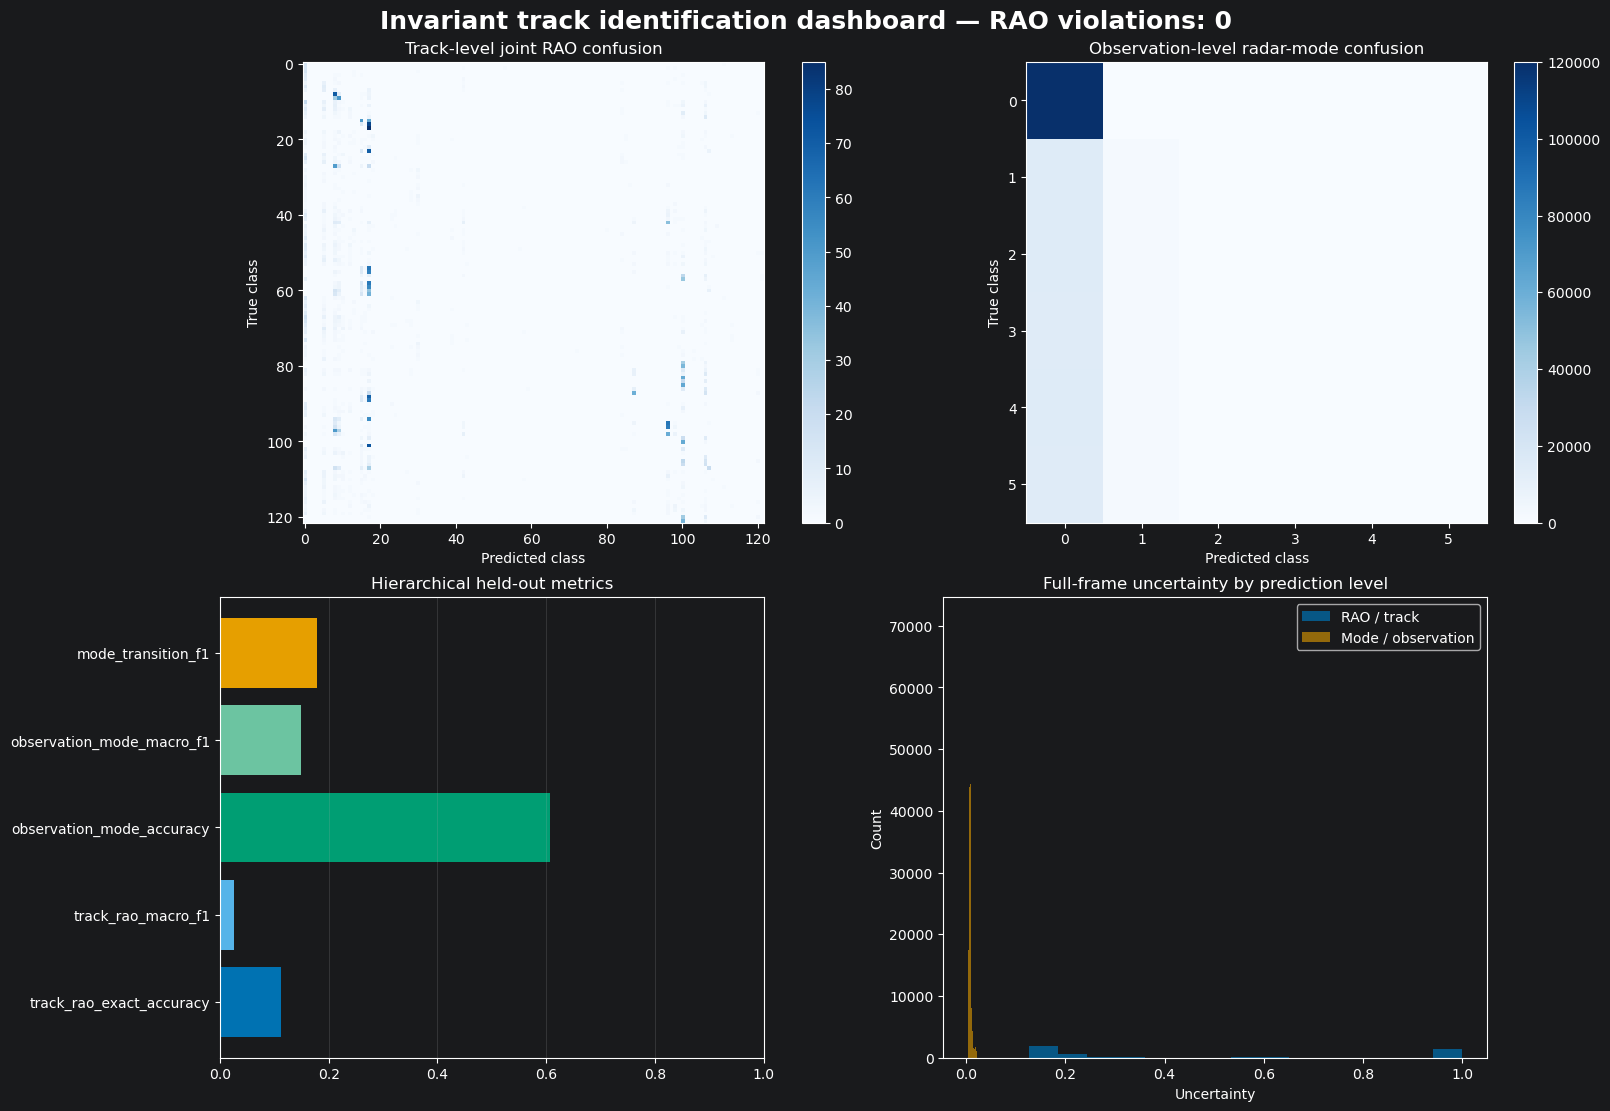

C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_identification_dashboard.png
[timing] Hierarchical evaluation dashboard - part 2 - completed; total time: 1.405 seconds


In [25]:
# Major step: Hierarchical evaluation dashboard - part 2
# Static dashboard: track RAO and observation-mode performance remain visibly separate.
rao_cm = confusion_matrix(rao_truth, rao_predicted, labels=np.unique(np.concatenate((rao_truth, rao_predicted))))
mode_cm = confusion_matrix(mode_truth, mode_predicted, labels=np.unique(np.concatenate((mode_truth, mode_predicted))))
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
for axis, matrix, title in ((axes[0, 0], rao_cm, "Track-level joint RAO confusion"), (axes[0, 1], mode_cm, "Observation-level radar-mode confusion")):
    image = axis.imshow(matrix, cmap="Blues")
    axis.set(title=title, xlabel="Predicted class", ylabel="True class")
    fig.colorbar(image, ax=axis, fraction=.046)
metric_names = ["track_rao_exact_accuracy", "track_rao_macro_f1", "observation_mode_accuracy", "observation_mode_macro_f1", "mode_transition_f1"]
axes[1, 0].barh(metric_names, [dashboard_metrics[name] for name in metric_names], color=["#0072B2", "#56B4E9", "#009E73", "#6CC4A1", "#E69F00"])
axes[1, 0].set(xlim=(0, 1), title="Hierarchical held-out metrics")
axes[1, 0].grid(axis="x", alpha=.25)
rao_uncertainty = final_outputs["evidential"]["track_rao"]["uncertainty"][test_track_indices].detach().cpu().numpy().ravel()
mode_uncertainty = final_outputs["evidential"]["radar_mode"]["uncertainty"][test_observation_positions].detach().cpu().numpy().ravel()
axes[1, 1].hist(rao_uncertainty, bins=15, alpha=.7, label="RAO / track", color="#0072B2")
axes[1, 1].hist(mode_uncertainty, bins=15, alpha=.6, label="Mode / observation", color="#E69F00")
axes[1, 1].set(title="Full-frame uncertainty by prediction level", xlabel="Uncertainty", ylabel="Count")
axes[1, 1].legend()
fig.suptitle(f"Invariant track identification dashboard — RAO violations: {RAO_VIOLATION_COUNT}", fontsize=18, fontweight="bold")
dashboard_path = ARTIFACT_DIR / "track_identification_dashboard.png"
fig.savefig(dashboard_path, dpi=200, bbox_inches="tight")
mlflow.log_artifact(dashboard_path, artifact_path="dashboards")
plt.show()
print(dashboard_path)


## Evidential uncertainty diagnostics

The following checks diagnose whether full-frame uncertainty is useful rather than merely large. They keep track-level joint RAO predictions separate from observation-level radar-mode predictions because the two heads have different classes and sampling units.

1. **Split behaviour:** compare uncertainty on train, validation, and test data. A large test-only increase suggests generalisation or distribution-shift problems; uniformly large values suggest weak evidence learning.
2. **Outcome behaviour:** compare correct and incorrect test predictions and report error-detection AUROC when both outcomes occur. Useful uncertainty should generally be larger for errors.
3. **Evidence and strength:** inspect total evidence, winning-class evidence, Dirichlet strength, uncertainty, and confidence. Since $u=K/S$, the uncertainty-strength relationship is deterministic; the other views show whether any samples or predicted classes accumulate meaningful evidence.

Each figure is saved under `ARTIFACT_DIR/uncertainty_diagnostics` and logged to MLflow.


In [26]:
# Major step: Evidential diagnostics data preparation
# Evidential diagnostics: assemble task- and split-aligned arrays once.
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_auc_score

uncertainty_diagnostic_dir = ARTIFACT_DIR / "uncertainty_diagnostics"
uncertainty_diagnostic_dir.mkdir(parents=True, exist_ok=True)

split_colours = {"train": "#009E73", "val": "#E69F00", "test": "#0072B2"}
outcome_colours = {"correct": "#009E73", "incorrect": "#D55E00"}


def _numpy_rows(tensor, indices):
    index = torch.as_tensor(indices, dtype=torch.long, device=tensor.device)
    return tensor.index_select(0, index).detach().float().cpu().numpy()


diagnostic_tasks = {
    "Track RAO": {
        "output": final_outputs["evidential"]["track_rao"],
        "targets": track_targets,
        "splits": track_splits,
        "vocabulary": rao_vocab,
    },
    "Observation mode": {
        "output": final_outputs["evidential"]["radar_mode"],
        "targets": mode_targets,
        "splits": observation_splits,
        "vocabulary": mode_vocab,
    },
}

for task in diagnostic_tasks.values():
    task["arrays"] = {}
    for split_name in ("train", "val", "test"):
        indices = task["splits"][split_name]
        probabilities = _numpy_rows(task["output"]["probabilities"], indices)
        targets = _numpy_rows(task["targets"], indices).astype(np.int64, copy=False)
        predicted = probabilities.argmax(axis=1)
        task["arrays"][split_name] = {
            "uncertainty": _numpy_rows(task["output"]["uncertainty"], indices).ravel(),
            "strength": _numpy_rows(task["output"]["strength"], indices).ravel(),
            "evidence": _numpy_rows(task["output"]["evidence"], indices),
            "probabilities": probabilities,
            "targets": targets,
            "predicted": predicted,
            "confidence": probabilities.max(axis=1),
            "correct": predicted == targets,
        }

print({name: {split: len(values["targets"]) for split, values in task["arrays"].items()}
       for name, task in diagnostic_tasks.items()})


{'Track RAO': {'train': 7176, 'val': 2866, 'test': 4297}, 'Observation mode': {'train': 333977, 'val': 132326, 'test': 200573}}
[timing] Evidential diagnostics data preparation - completed; total time: 0.191 seconds


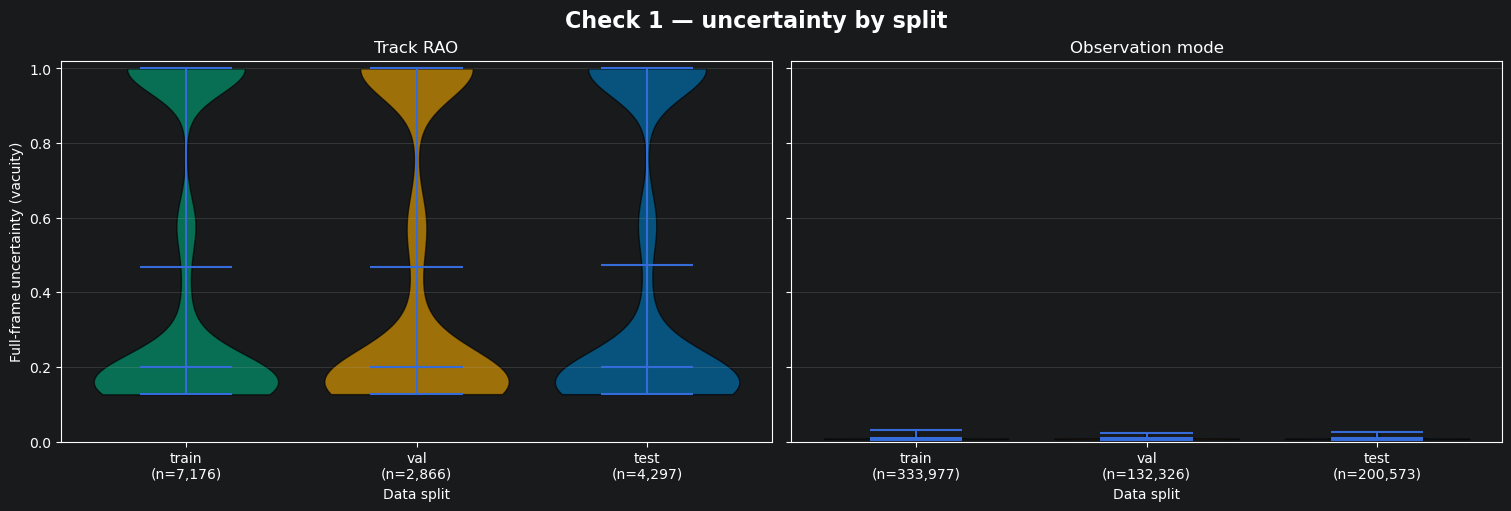

[
  {
    "task": "Track RAO",
    "split": "train",
    "count": 7176,
    "mean": 0.46862152218818665,
    "std": 0.38474756479263306,
    "min": 0.12647993862628937,
    "p05": 0.12965663895010948,
    "p25": 0.1310253068804741,
    "median": 0.20052004605531693,
    "p75": 1.0,
    "p95": 1.0,
    "max": 1.0
  },
  {
    "task": "Track RAO",
    "split": "val",
    "count": 2866,
    "mean": 0.46809279918670654,
    "std": 0.3844611644744873,
    "min": 0.127116858959198,
    "p05": 0.12968959286808968,
    "p25": 0.13102328404784203,
    "median": 0.20090053975582123,
    "p75": 1.0,
    "p95": 1.0,
    "max": 1.0
  },
  {
    "task": "Track RAO",
    "split": "test",
    "count": 4297,
    "mean": 0.47327303886413574,
    "std": 0.3877429664134979,
    "min": 0.12703539431095123,
    "p05": 0.1296590119600296,
    "p25": 0.13090452551841736,
    "median": 0.20002560317516327,
    "p75": 1.0,
    "p95": 1.0,
    "max": 1.0
  },
  {
    "task": "Observation mode",
    "split": "tra

2094

[timing] Evidential diagnostics check 1 - completed; total time: 1.774 seconds


In [27]:
# Major step: Evidential diagnostics check 1
# Check 1: train/validation/test full-frame uncertainty distributions.
split_summary_rows = []
fig, axes = plt.subplots(1, len(diagnostic_tasks), figsize=(15, 5), sharey=True, constrained_layout=True)
for axis, (task_name, task) in zip(np.atleast_1d(axes), diagnostic_tasks.items()):
    distributions, labels = [], []
    for split_name in ("train", "val", "test"):
        values = task["arrays"][split_name]["uncertainty"]
        distributions.append(values)
        labels.append(f"{split_name}\n(n={values.size:,})")
        if values.size:
            percentiles = np.percentile(values, [5, 25, 50, 75, 95])
            split_summary_rows.append({
                "task": task_name, "split": split_name, "count": int(values.size),
                "mean": float(values.mean()), "std": float(values.std()),
                "min": float(values.min()), "p05": float(percentiles[0]),
                "p25": float(percentiles[1]), "median": float(percentiles[2]),
                "p75": float(percentiles[3]), "p95": float(percentiles[4]),
                "max": float(values.max()),
            })
    violin = axis.violinplot(distributions, showmeans=True, showmedians=True, widths=.8)
    for body, split_name in zip(violin["bodies"], ("train", "val", "test")):
        body.set_facecolor(split_colours[split_name]); body.set_edgecolor("black"); body.set_alpha(.65)
    axis.set_xticks(np.arange(1, 4), labels)
    axis.set(title=task_name, xlabel="Data split", ylim=(0, 1.02))
    axis.grid(axis="y", alpha=.25)
axes[0].set_ylabel("Full-frame uncertainty (vacuity)")
fig.suptitle("Check 1 — uncertainty by split", fontsize=16, fontweight="bold")
split_uncertainty_path = uncertainty_diagnostic_dir / "uncertainty_by_split.png"
fig.savefig(split_uncertainty_path, dpi=200, bbox_inches="tight")
mlflow.log_artifact(split_uncertainty_path, artifact_path="uncertainty_diagnostics")
plt.show()

print(json.dumps(split_summary_rows, indent=2))
(uncertainty_diagnostic_dir / "uncertainty_by_split_summary.json").write_text(
    json.dumps(split_summary_rows, indent=2), encoding="utf-8")


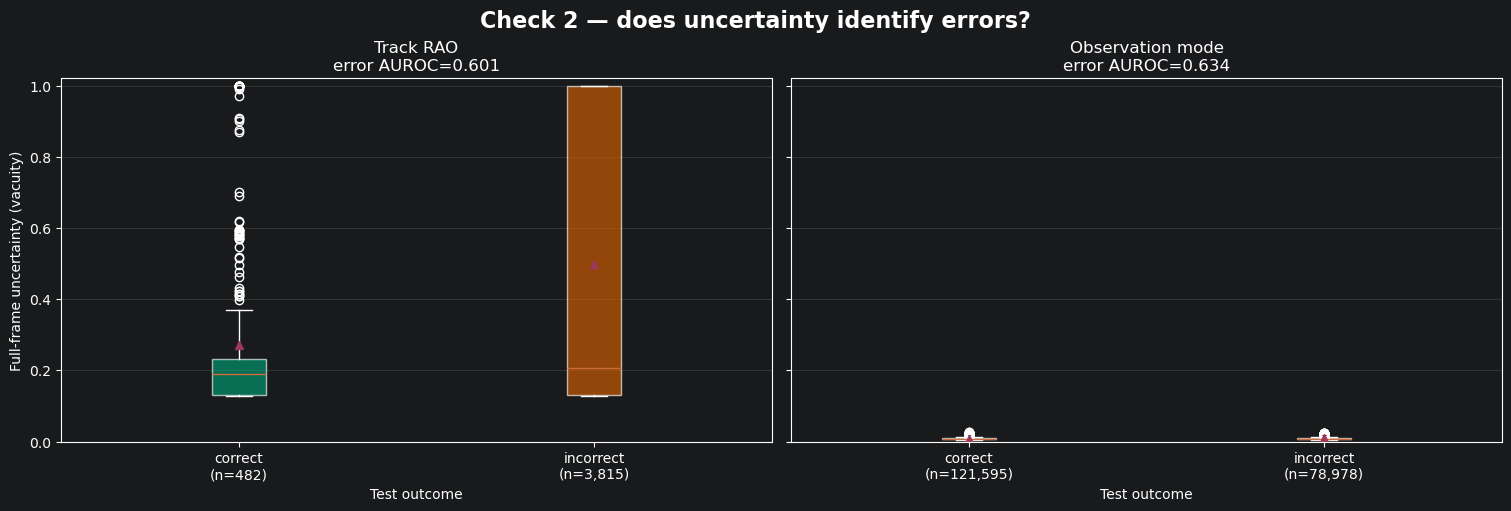

[
  {
    "task": "Track RAO",
    "outcome": "correct",
    "count": 482,
    "mean_uncertainty": 0.270538866519928,
    "median_uncertainty": 0.18910953402519226,
    "error_detection_auroc": 0.6007760369365303
  },
  {
    "task": "Track RAO",
    "outcome": "incorrect",
    "count": 3815,
    "mean_uncertainty": 0.49888715147972107,
    "median_uncertainty": 0.20660075545310974,
    "error_detection_auroc": 0.6007760369365303
  },
  {
    "task": "Observation mode",
    "outcome": "correct",
    "count": 121595,
    "mean_uncertainty": 0.007698996923863888,
    "median_uncertainty": 0.007118757348507643,
    "error_detection_auroc": 0.633893955903885
  },
  {
    "task": "Observation mode",
    "outcome": "incorrect",
    "count": 78978,
    "mean_uncertainty": 0.009152164682745934,
    "median_uncertainty": 0.00807808805257082,
    "error_detection_auroc": 0.633893955903885
  }
]


897

[timing] Evidential diagnostics check 2 - completed; total time: 0.445 seconds


In [28]:
# Major step: Evidential diagnostics check 2
# Check 2: test uncertainty for correct versus incorrect classifications.
outcome_summary_rows = []
fig, axes = plt.subplots(1, len(diagnostic_tasks), figsize=(15, 5), sharey=True, constrained_layout=True)
for axis, (task_name, task) in zip(np.atleast_1d(axes), diagnostic_tasks.items()):
    test = task["arrays"]["test"]
    outcomes = [("correct", test["uncertainty"][test["correct"]]),
                ("incorrect", test["uncertainty"][~test["correct"]])]
    nonempty = [(label, values) for label, values in outcomes if values.size]
    if nonempty:
        boxes = axis.boxplot([values for _, values in nonempty], patch_artist=True,
                             tick_labels=[f"{label}\n(n={values.size:,})" for label, values in nonempty],
                             showmeans=True)
        for patch, (label, _) in zip(boxes["boxes"], nonempty):
            patch.set_facecolor(outcome_colours[label]); patch.set_alpha(.65)
    errors = (~test["correct"]).astype(np.int8)
    error_auroc = float(roc_auc_score(errors, test["uncertainty"])) if np.unique(errors).size == 2 else float("nan")
    for label, values in outcomes:
        outcome_summary_rows.append({
            "task": task_name, "outcome": label, "count": int(values.size),
            "mean_uncertainty": float(values.mean()) if values.size else float("nan"),
            "median_uncertainty": float(np.median(values)) if values.size else float("nan"),
            "error_detection_auroc": error_auroc,
        })
    axis.set(title=f"{task_name}\nerror AUROC={error_auroc:.3f}" if np.isfinite(error_auroc)
             else f"{task_name}\nerror AUROC undefined", xlabel="Test outcome", ylim=(0, 1.02))
    axis.grid(axis="y", alpha=.25)
axes[0].set_ylabel("Full-frame uncertainty (vacuity)")
fig.suptitle("Check 2 — does uncertainty identify errors?", fontsize=16, fontweight="bold")
outcome_uncertainty_path = uncertainty_diagnostic_dir / "uncertainty_by_outcome.png"
fig.savefig(outcome_uncertainty_path, dpi=200, bbox_inches="tight")
mlflow.log_artifact(outcome_uncertainty_path, artifact_path="uncertainty_diagnostics")
plt.show()

print(json.dumps(outcome_summary_rows, indent=2))
(uncertainty_diagnostic_dir / "uncertainty_by_outcome_summary.json").write_text(
    json.dumps(outcome_summary_rows, indent=2), encoding="utf-8")


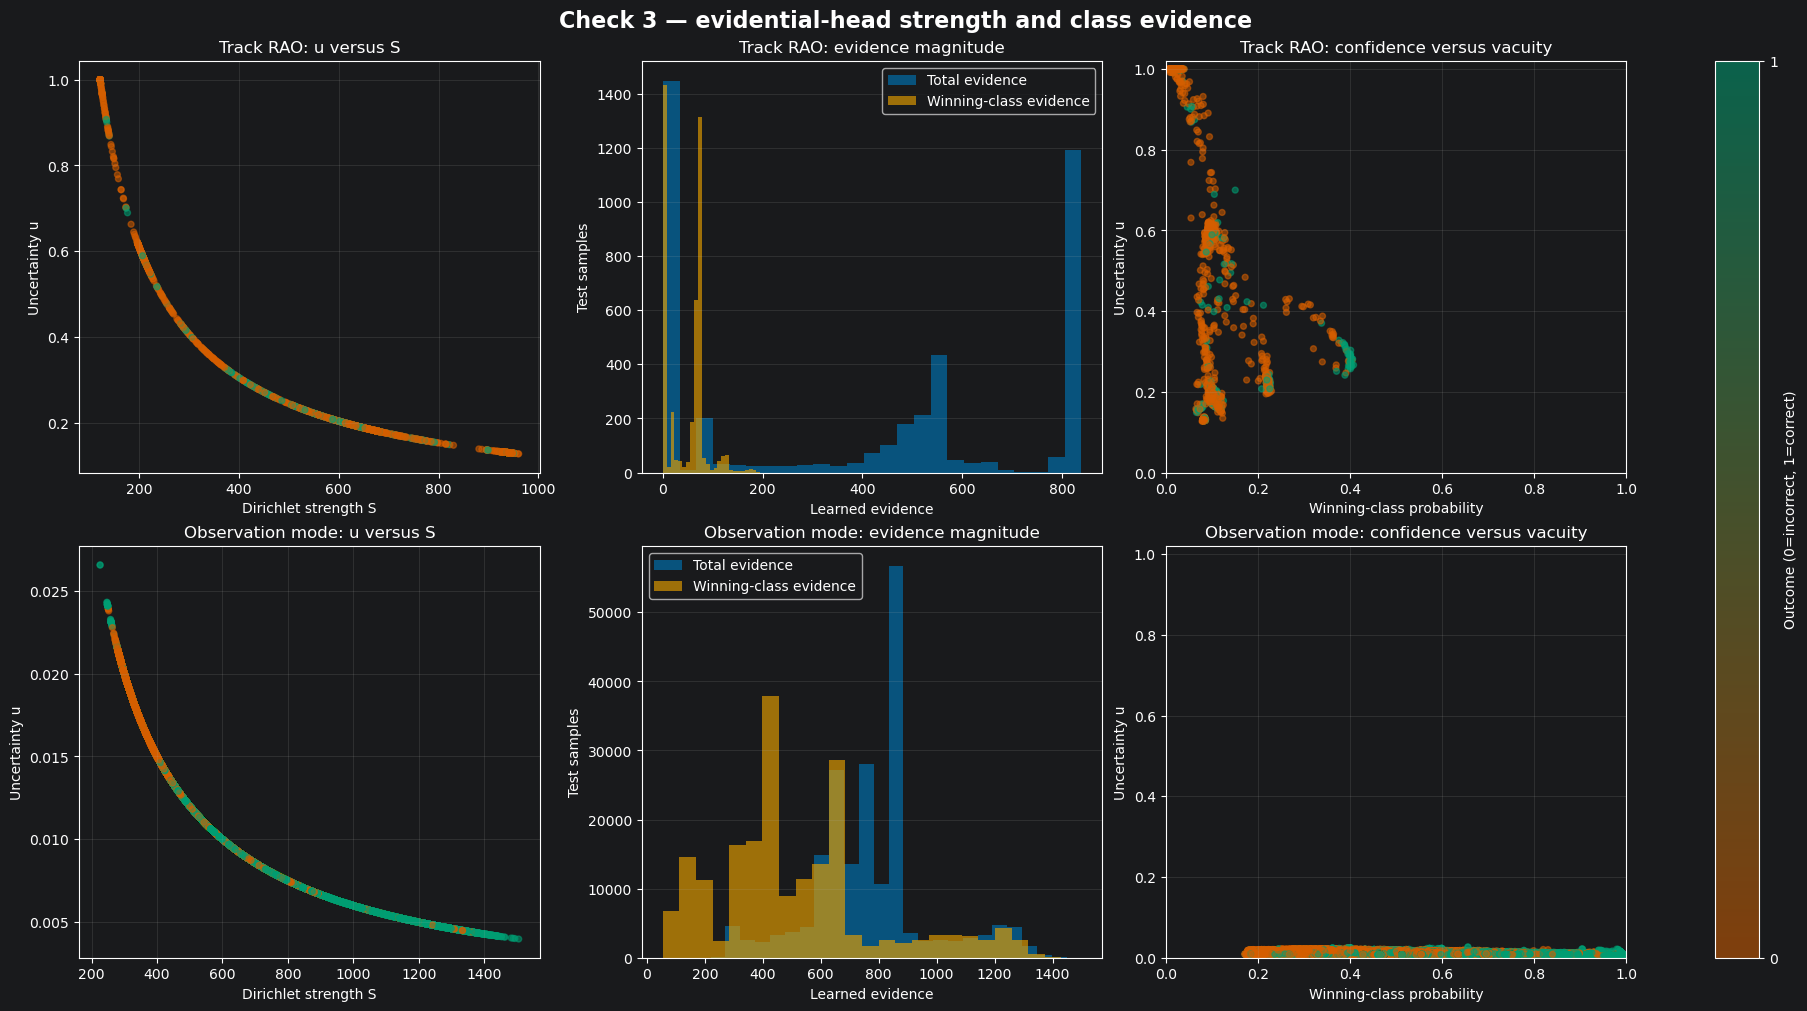

[
  {
    "task": "Observation mode",
    "predicted_class": "air_to_ground_mapping",
    "count": 8012,
    "mean_total_evidence": 655.639892578125,
    "mean_winning_evidence": 122.3410415649414,
    "mean_strength": 661.639892578125,
    "mean_uncertainty": 0.009224923327565193,
    "mean_confidence": 0.18623344600200653
  },
  {
    "task": "Observation mode",
    "predicted_class": "OFF",
    "count": 192561,
    "mean_total_evidence": 783.0877685546875,
    "mean_winning_evidence": 532.3971557617188,
    "mean_strength": 789.0877075195312,
    "mean_uncertainty": 0.008231516927480698,
    "mean_confidence": 0.6485429406166077
  },
  {
    "task": "Track RAO",
    "predicted_class": [
      "AH-64E Apache Guardian",
      "AN/APG-78",
      "Greece"
    ],
    "count": 584,
    "mean_total_evidence": 2.1080295482533984e-06,
    "mean_winning_evidence": 4.85615270218176e-10,
    "mean_strength": 122.0,
    "mean_uncertainty": 1.0,
    "mean_confidence": 0.015116576105356216
  },
  

In [29]:
# Major step: Evidential diagnostics check 3
# Check 3: inspect learned evidence, Dirichlet strength, uncertainty, and confidence.
evidence_summary_rows = []
fig, axes = plt.subplots(len(diagnostic_tasks), 3, figsize=(18, 10), constrained_layout=True)
for row, (task_name, task) in enumerate(diagnostic_tasks.items()):
    test = task["arrays"]["test"]
    evidence = test["evidence"]
    total_evidence = evidence.sum(axis=1)
    winning_evidence = evidence[np.arange(evidence.shape[0]), test["predicted"]]

    scatter = axes[row, 0].scatter(test["strength"], test["uncertainty"], c=test["correct"],
                                   cmap=LinearSegmentedColormap.from_list("outcomes", [outcome_colours["incorrect"], outcome_colours["correct"]]),
                                   vmin=0, vmax=1, alpha=.55, s=18)
    axes[row, 0].set(xlabel="Dirichlet strength S", ylabel="Uncertainty u", title=f"{task_name}: u versus S")
    axes[row, 0].grid(alpha=.2)

    axes[row, 1].hist(total_evidence, bins=25, alpha=.65, label="Total evidence", color="#0072B2")
    axes[row, 1].hist(winning_evidence, bins=25, alpha=.65, label="Winning-class evidence", color="#E69F00")
    axes[row, 1].set(xlabel="Learned evidence", ylabel="Test samples", title=f"{task_name}: evidence magnitude")
    axes[row, 1].legend(); axes[row, 1].grid(axis="y", alpha=.2)

    confidence_plot = axes[row, 2].scatter(test["confidence"], test["uncertainty"], c=test["correct"],
                                           cmap=scatter.cmap, vmin=0, vmax=1, alpha=.55, s=18)
    axes[row, 2].set(xlabel="Winning-class probability", ylabel="Uncertainty u", xlim=(0, 1), ylim=(0, 1.02),
                     title=f"{task_name}: confidence versus vacuity")
    axes[row, 2].grid(alpha=.2)

    for class_index in np.unique(test["predicted"]):
        selected = test["predicted"] == class_index
        evidence_summary_rows.append({
            "task": task_name, "predicted_class": task["vocabulary"][int(class_index)],
            "count": int(selected.sum()), "mean_total_evidence": float(total_evidence[selected].mean()),
            "mean_winning_evidence": float(winning_evidence[selected].mean()),
            "mean_strength": float(test["strength"][selected].mean()),
            "mean_uncertainty": float(test["uncertainty"][selected].mean()),
            "mean_confidence": float(test["confidence"][selected].mean()),
        })

fig.colorbar(confidence_plot, ax=axes[:, [0, 2]], ticks=[0, 1], label="Outcome (0=incorrect, 1=correct)")
fig.suptitle("Check 3 — evidential-head strength and class evidence", fontsize=16, fontweight="bold")
evidence_strength_path = uncertainty_diagnostic_dir / "evidence_and_strength.png"
fig.savefig(evidence_strength_path, dpi=200, bbox_inches="tight")
mlflow.log_artifact(evidence_strength_path, artifact_path="uncertainty_diagnostics")
plt.show()

evidence_summary_rows.sort(key=lambda row: (row["task"], -row["mean_uncertainty"]))
print(json.dumps(evidence_summary_rows, indent=2))
(uncertainty_diagnostic_dir / "evidence_and_strength_by_predicted_class.json").write_text(
    json.dumps(evidence_summary_rows, indent=2), encoding="utf-8")
print(f"Saved uncertainty diagnostics to {uncertainty_diagnostic_dir}")


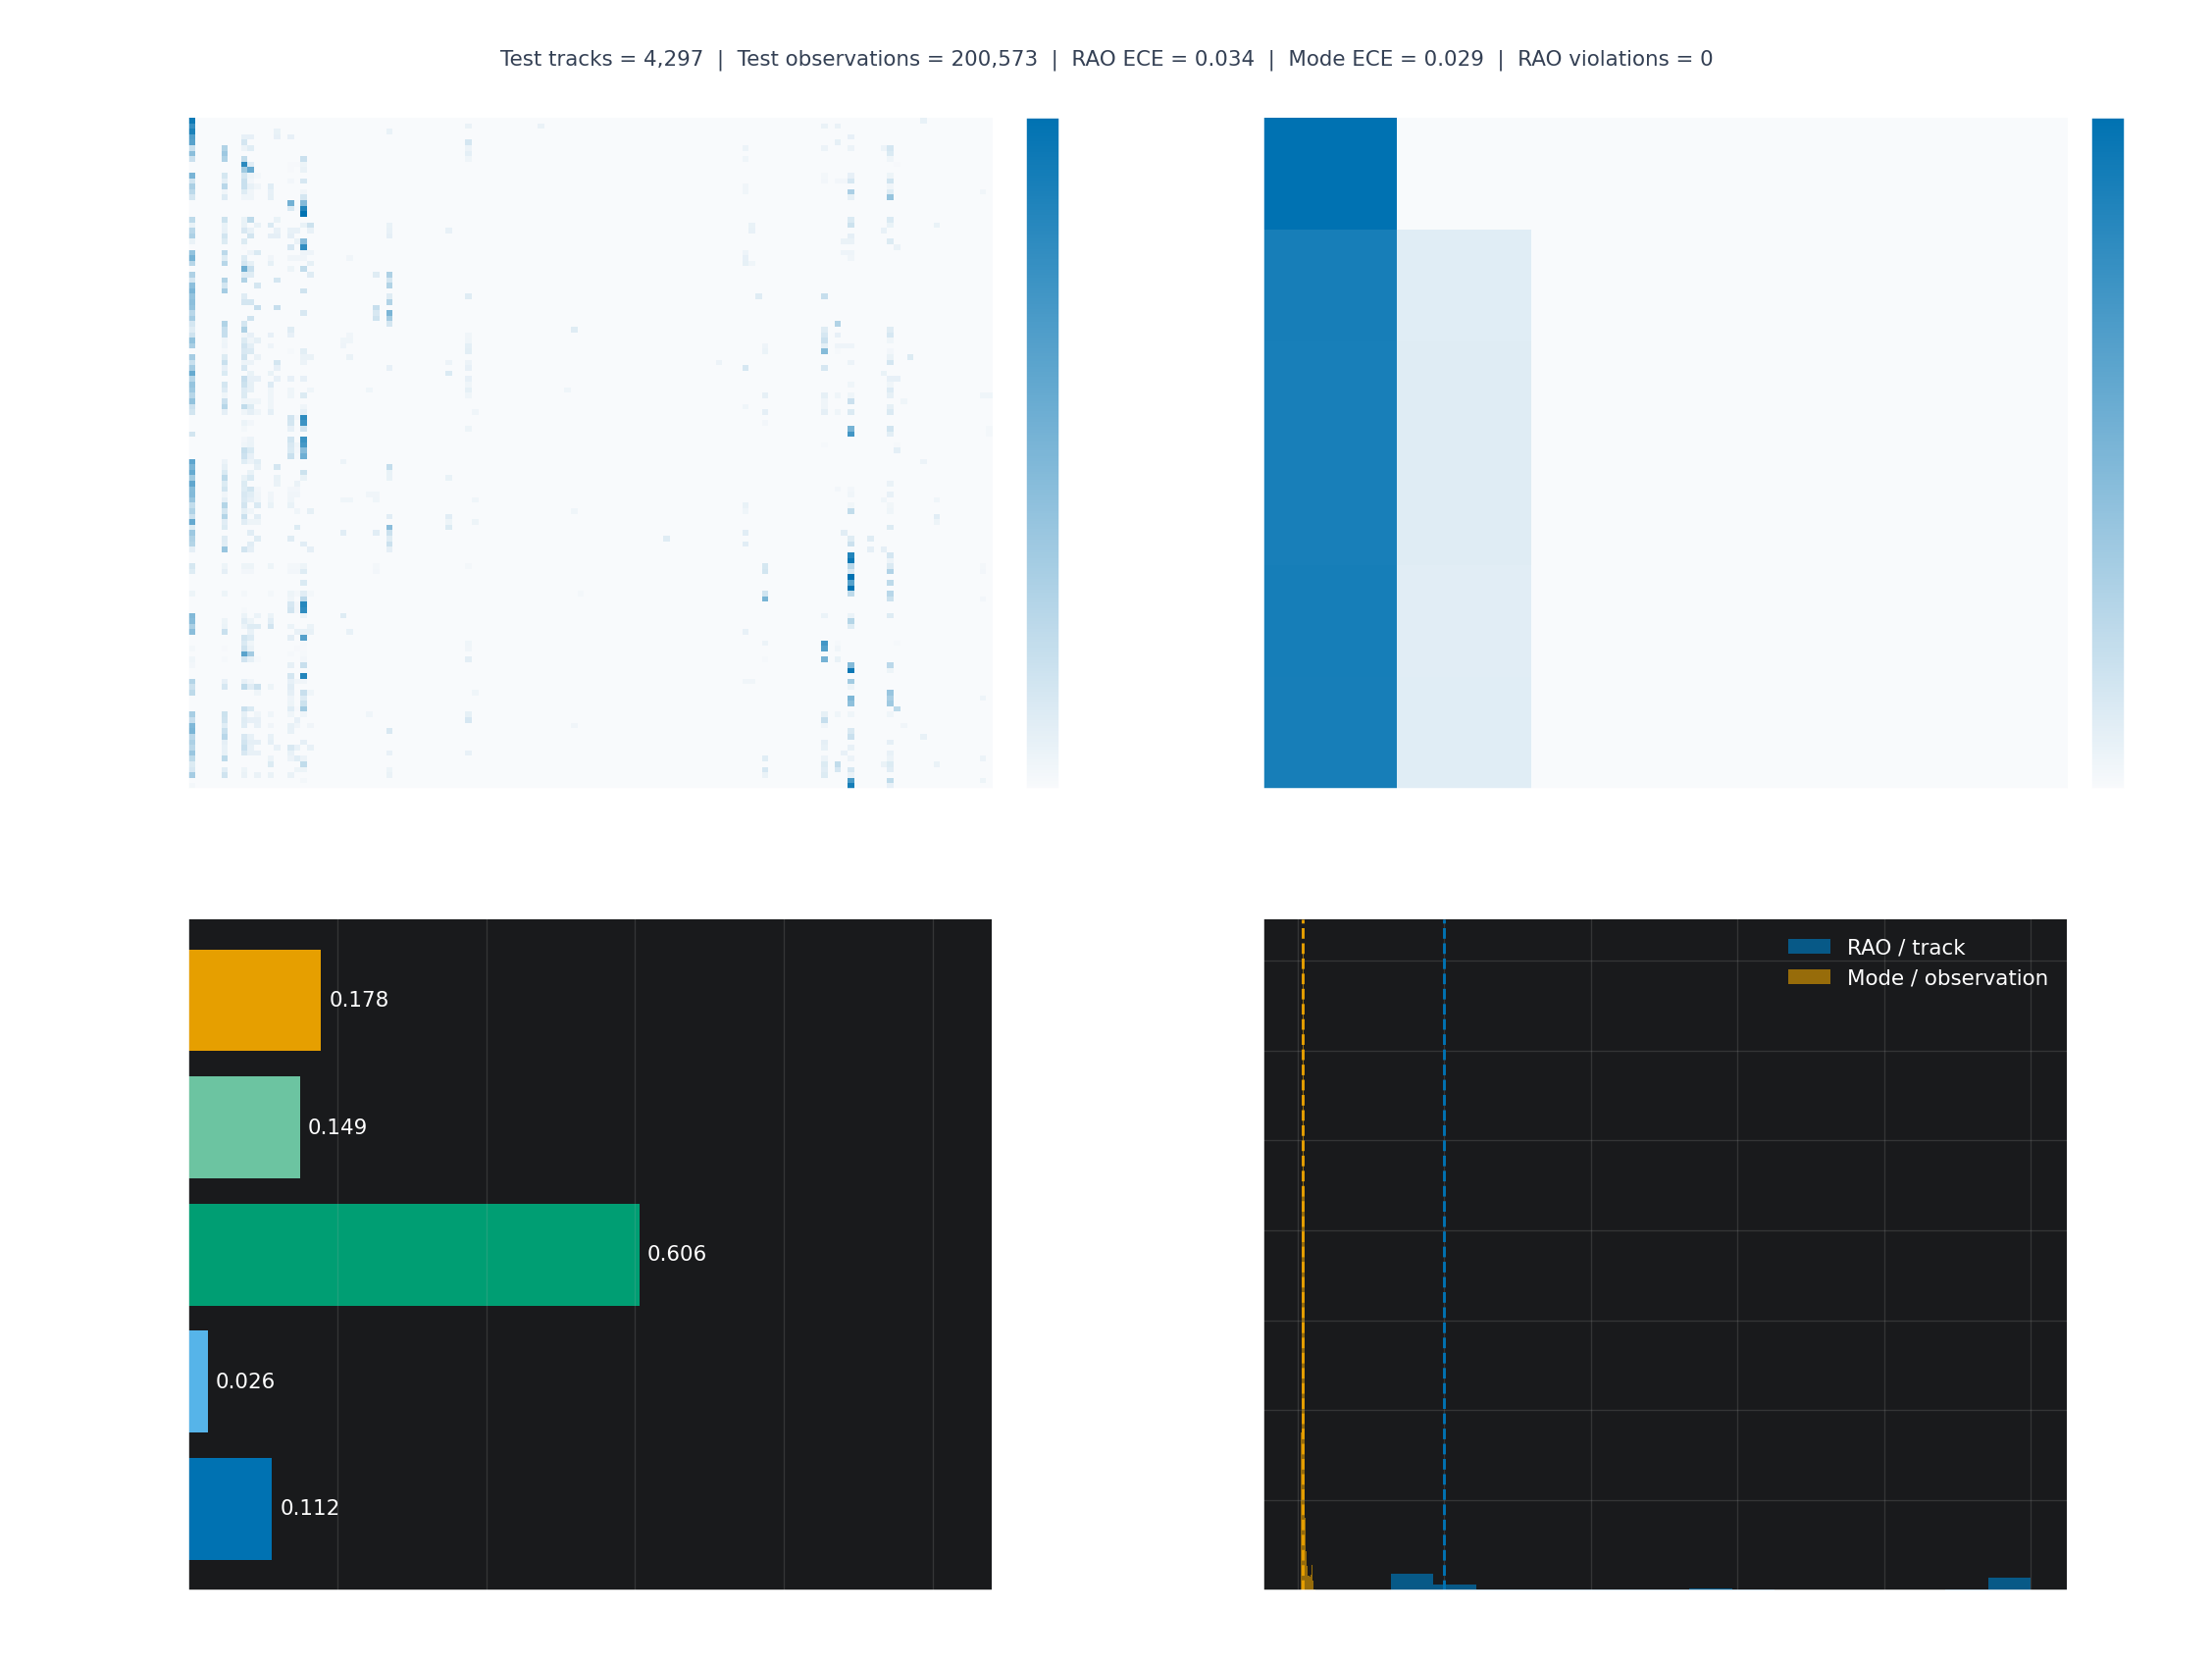

Publication dashboard exports:
  C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_identification_dashboard_publication.png
  C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_identification_dashboard_publication.pdf
  C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_identification_dashboard_publication.svg
[timing] Hierarchical evaluation dashboard - part 3 - completed; total time: 9.257 seconds


In [30]:
# Major step: Hierarchical evaluation dashboard - part 3
# Publication-grade rendering of the hierarchical dashboard computed above.
# Deterministic PNG/PDF/SVG exports mirror the publication workflow used by the
# advanced joint-world notebook while preserving the two prediction levels.
from matplotlib.colors import LinearSegmentedColormap

PUBLICATION_DPI = 300
PUBLICATION_FORMATS = ("png", "pdf", "svg")
PUBLICATION_PALETTE = {
    "blue": "#0072B2", "light_blue": "#56B4E9", "green": "#009E73",
    "light_green": "#6CC4A1", "orange": "#E69F00", "grey": "#667085",
}


def _row_normalise(matrix: np.ndarray) -> np.ndarray:
    totals = matrix.sum(axis=1, keepdims=True)
    return np.divide(matrix, totals, out=np.zeros_like(matrix, dtype=float), where=totals != 0)


publication_rc = {
    "figure.dpi": 140, "savefig.dpi": PUBLICATION_DPI,
    "font.family": "sans-serif", "font.size": 11,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "grid.alpha": 0.18, "grid.linewidth": 0.7,
    "legend.frameon": False, "svg.fonttype": "none", "pdf.fonttype": 42,
}
metric_names = (
    "track_rao_exact_accuracy", "track_rao_macro_f1",
    "observation_mode_accuracy", "observation_mode_macro_f1", "mode_transition_f1",
)
metric_labels = ("RAO accuracy", "RAO macro F1", "Mode accuracy", "Mode macro F1", "Transition F1")
metric_colours = (
    PUBLICATION_PALETTE["blue"], PUBLICATION_PALETTE["light_blue"],
    PUBLICATION_PALETTE["green"], PUBLICATION_PALETTE["light_green"], PUBLICATION_PALETTE["orange"],
)

with plt.rc_context(publication_rc):
    publication_figure, publication_axes = plt.subplots(2, 2, figsize=(16, 12), constrained_layout=True)
    publication_figure.patch.set_facecolor("white")
    blue_map = LinearSegmentedColormap.from_list("hierarchical_blue", ["#F8FAFC", PUBLICATION_PALETTE["blue"]])
    for axis, matrix, xlabel, ylabel in (
        (publication_axes[0, 0], rao_cm, "Predicted joint RAO class", "True joint RAO class"),
        (publication_axes[0, 1], mode_cm, "Predicted radar-mode class", "True radar-mode class"),
    ):
        rates = _row_normalise(matrix)
        image = axis.imshow(rates, cmap=blue_map, vmin=0, vmax=1, aspect="auto", interpolation="nearest")
        colour_bar = publication_figure.colorbar(image, ax=axis, fraction=0.046, pad=0.03)
        colour_bar.set_label("Row-normalised rate")
        axis.set(xlabel=xlabel, ylabel=ylabel)
        if matrix.shape[0] <= 20 and matrix.shape[1] <= 20:
            axis.set_xticks(np.arange(matrix.shape[1]))
            axis.set_yticks(np.arange(matrix.shape[0]))

    values = [dashboard_metrics[name] for name in metric_names]
    bars = publication_axes[1, 0].barh(metric_labels, values, color=metric_colours)
    publication_axes[1, 0].bar_label(bars, labels=[f"{value:.3f}" for value in values], padding=4)
    publication_axes[1, 0].set(xlabel="Score", xlim=(0, 1.08))
    publication_axes[1, 0].grid(True, axis="x")

    publication_axes[1, 1].hist(rao_uncertainty, bins=15, alpha=.72, label="RAO / track", color=PUBLICATION_PALETTE["blue"])
    publication_axes[1, 1].hist(mode_uncertainty, bins=15, alpha=.62, label="Mode / observation", color=PUBLICATION_PALETTE["orange"])
    publication_axes[1, 1].axvline(np.median(rao_uncertainty), color=PUBLICATION_PALETTE["blue"], linestyle="--", linewidth=1.5)
    publication_axes[1, 1].axvline(np.median(mode_uncertainty), color=PUBLICATION_PALETTE["orange"], linestyle="--", linewidth=1.5)
    publication_axes[1, 1].set(xlabel="Full-frame uncertainty", ylabel="Samples")
    publication_axes[1, 1].legend(loc="best")
    publication_axes[1, 1].grid(True)

    panel_titles = ("Track-level joint RAO confusion", "Observation-level radar-mode confusion", "Held-out performance", "Uncertainty by prediction level")
    for panel_index, (axis, title) in enumerate(zip(publication_axes.ravel(), panel_titles)):
        axis.set_title(title, loc="left", pad=12)
        axis.text(-0.10, 1.08, chr(65 + panel_index), transform=axis.transAxes, fontsize=16, fontweight="bold", va="top")

    subtitle = (
        f"Test tracks = {len(test_track_indices):,}  |  Test observations = {len(test_observation_positions):,}  |  "
        f"RAO ECE = {dashboard_metrics['track_rao_ece']:.3f}  |  "
        f"Mode ECE = {dashboard_metrics['observation_mode_ece']:.3f}  |  RAO violations = {RAO_VIOLATION_COUNT}"
    )
    publication_figure.suptitle("Invariant track-identification evaluation", fontsize=21, fontweight="bold")
    publication_figure.text(0.5, 0.975, subtitle, ha="center", va="top", fontsize=11, color="#344054")

    publication_paths = []
    for suffix in PUBLICATION_FORMATS:
        output_path = ARTIFACT_DIR / f"track_identification_dashboard_publication.{suffix}"
        save_options = {"bbox_inches": "tight", "facecolor": "white"}
        if suffix == "png":
            save_options["dpi"] = PUBLICATION_DPI
        publication_figure.savefig(output_path, **save_options)
        publication_paths.append(output_path)
    plt.show()

for output_path in publication_paths:
    mlflow.log_artifact(output_path, artifact_path="dashboards/publication")

print("Publication dashboard exports:")
for output_path in publication_paths:
    print(f"  {output_path}")


### How to read the interactive dashboard

This Plotly view repeats the two row-normalised confusion matrices and the five held-out metric bars above, then adds three diagnostics. Hovering supplies exact counts, rates, scores, or uncertainty summaries.

* **Reliability (D).** Each RAO point summarizes test tracks in one confidence bin; each mode point summarizes test observations. Its horizontal coordinate is mean predicted confidence and its vertical coordinate is observed accuracy. Points on the dashed diagonal are calibrated, points below it are overconfident, and points above it are underconfident. Marker size increases with the number of samples, so tiny bins should be interpreted cautiously.
* **Uncertainty by prediction level (E).** These are the same overlapping RAO-per-track and mode-per-observation full-frame uncertainty distributions as the static dashboard. A rightward shift indicates greater vacuity, not necessarily more class conflict.
* **Uncertainty by outcome (F).** The four box plots split full-frame uncertainty by correct/incorrect RAO tracks and correct/incorrect mode observations. The centre line is the median, the box is the interquartile range, whiskers show the default Plotly spread, and the displayed mean helps compare groups. Higher uncertainty for incorrect cases is desirable evidence that the model knows when it is less reliable, but overlap means uncertainty is not a perfect error detector.

RAO and mode traces have different sampling units, so apparent differences can reflect the number and composition of tracks/observations as well as model behaviour.


In [31]:
# Major step: Hierarchical evaluation dashboard - part 4
# Interactive Plotly companion to the publication-grade hierarchical dashboard.
# HTML is self-contained; optional static export requires Kaleido (`pip install kaleido`).
import plotly.graph_objects as go
from plotly.subplots import make_subplots

PLOTLY_STATIC_EXPORT = False
PLOTLY_PALETTE = {"rao": "#0072B2", "mode": "#009E73", "transition": "#E69F00", "neutral": "#667085"}


def _reliability_points(probabilities: np.ndarray, truth: np.ndarray, bins: int = 10):
    confidence = probabilities.max(1)
    predicted = probabilities.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    rows = []
    for lower, upper in zip(edges[:-1], edges[1:]):
        selected = (confidence > lower) & (confidence <= upper)
        if selected.any():
            rows.append((confidence[selected].mean(), (predicted[selected] == truth[selected]).mean(), selected.sum()))
    return tuple(np.asarray(items) for items in zip(*rows)) if rows else (np.array([]), np.array([]), np.array([]))


rao_reliability_x, rao_reliability_y, rao_reliability_count = _reliability_points(
    rao_probabilities[test_track_indices], rao_truth
)
mode_reliability_x, mode_reliability_y, mode_reliability_count = _reliability_points(
    mode_probabilities[test_observation_positions], mode_truth
)
interactive_figure = make_subplots(
    rows=2, cols=3,
    subplot_titles=(
        "<b>A</b> Track-level joint RAO confusion", "<b>B</b> Observation-level mode confusion", "<b>C</b> Held-out performance",
        "<b>D</b> Reliability", "<b>E</b> Uncertainty by prediction level", "<b>F</b> Uncertainty by outcome",
    ),
    horizontal_spacing=.09, vertical_spacing=.17,
)
for matrix, row_rates, position in ((rao_cm, _row_normalise(rao_cm), (1, 1)), (mode_cm, _row_normalise(mode_cm), (1, 2))):
    interactive_figure.add_trace(go.Heatmap(
        z=row_rates, customdata=matrix, colorscale=[[0, "#F8FAFC"], [1, PLOTLY_PALETTE["rao"]]], zmin=0, zmax=1,
        colorbar={"title": "Row rate", "len": .34},
        hovertemplate="True class %{y}<br>Predicted class %{x}<br>Count %{customdata}<br>Row rate %{z:.3f}<extra></extra>",
        showscale=position == (1, 2),
    ), row=position[0], col=position[1])

metric_values = [dashboard_metrics[name] for name in metric_names]
interactive_figure.add_trace(go.Bar(
    x=metric_values, y=metric_labels, orientation="h", text=[f"{value:.3f}" for value in metric_values], textposition="outside",
    marker_color=list(metric_colours), hovertemplate="%{y}<br>Score %{x:.3f}<extra></extra>", showlegend=False,
), row=1, col=3)

interactive_figure.add_trace(go.Scatter(
    x=[0, 1], y=[0, 1], mode="lines", name="Perfect calibration", line={"color": PLOTLY_PALETTE["neutral"], "dash": "dash"}, hoverinfo="skip",
), row=2, col=1)
for x_values, y_values, counts, name, colour in (
    (rao_reliability_x, rao_reliability_y, rao_reliability_count, "RAO / track", PLOTLY_PALETTE["rao"]),
    (mode_reliability_x, mode_reliability_y, mode_reliability_count, "Mode / observation", PLOTLY_PALETTE["mode"]),
):
    interactive_figure.add_trace(go.Scatter(
        x=x_values, y=y_values, mode="lines+markers", name=name, customdata=counts,
        marker={"size": 7 + 2 * np.sqrt(counts), "color": colour, "line": {"color": "white", "width": 1}}, line={"color": colour, "width": 3},
        hovertemplate="Confidence %{x:.3f}<br>Accuracy %{y:.3f}<br>Samples %{customdata}<extra></extra>",
    ), row=2, col=1)

interactive_figure.add_trace(go.Histogram(x=rao_uncertainty, nbinsx=15, name="RAO / track", marker_color=PLOTLY_PALETTE["rao"], opacity=.72), row=2, col=2)
interactive_figure.add_trace(go.Histogram(x=mode_uncertainty, nbinsx=15, name="Mode / observation", marker_color=PLOTLY_PALETTE["transition"], opacity=.62), row=2, col=2)
rao_correct = rao_predicted == rao_truth
mode_correct = mode_predicted == mode_truth
for values, label, colour in (
    (rao_uncertainty[rao_correct], "RAO correct", PLOTLY_PALETTE["rao"]),
    (rao_uncertainty[~rao_correct], "RAO incorrect", PLOTLY_PALETTE["transition"]),
    (mode_uncertainty[mode_correct], "Mode correct", PLOTLY_PALETTE["mode"]),
    (mode_uncertainty[~mode_correct], "Mode incorrect", "#CC79A7"),
):
    if values.size:
        interactive_figure.add_trace(go.Box(y=values, name=label, boxmean=True, marker_color=colour, showlegend=False), row=2, col=3)

interactive_figure.update_xaxes(title_text="Predicted class", row=1, col=1)
interactive_figure.update_yaxes(title_text="True class", autorange="reversed", row=1, col=1)
interactive_figure.update_xaxes(title_text="Predicted class", row=1, col=2)
interactive_figure.update_yaxes(title_text="True class", autorange="reversed", row=1, col=2)
interactive_figure.update_xaxes(title_text="Score", range=[0, 1.08], row=1, col=3)
interactive_figure.update_xaxes(title_text="Mean confidence", range=[0, 1], row=2, col=1)
interactive_figure.update_yaxes(title_text="Observed accuracy", range=[0, 1], row=2, col=1)
interactive_figure.update_xaxes(title_text="Full-frame uncertainty", row=2, col=2)
interactive_figure.update_yaxes(title_text="Samples", row=2, col=2)
interactive_figure.update_yaxes(title_text="Full-frame uncertainty", row=2, col=3)
interactive_figure.update_layout(
    template="plotly_white", height=1050, width=1700, barmode="overlay",
    title={"text": "<b>Interactive invariant track-identification evaluation</b>", "x": .5, "xanchor": "center", "font": {"size": 25}},
    margin={"l": 80, "r": 80, "t": 125, "b": 70}, hovermode="closest",
    legend={"orientation": "h", "yanchor": "bottom", "y": 1.03, "xanchor": "right", "x": 1},
)
interactive_figure.update_xaxes(showgrid=True, gridcolor="rgba(102,112,133,.15)", zeroline=False)
interactive_figure.update_yaxes(showgrid=True, gridcolor="rgba(102,112,133,.15)", zeroline=False)
interactive_path = ARTIFACT_DIR / "track_identification_dashboard_interactive.html"
interactive_figure.write_html(interactive_path, include_plotlyjs=True, full_html=True)
mlflow.log_artifact(interactive_path, artifact_path="dashboards")
if PLOTLY_STATIC_EXPORT:
    interactive_figure.write_image(ARTIFACT_DIR / "track_identification_dashboard_plotly.svg")
    interactive_figure.write_image(ARTIFACT_DIR / "track_identification_dashboard_plotly.png", width=1700, height=1050, scale=2)
interactive_figure.show(config={"displaylogo": False, "responsive": True, "toImageButtonOptions": {"format": "svg"}})
print(f"Interactive dashboard: {interactive_path}")


Interactive dashboard: C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_identification_dashboard_interactive.html
[timing] Hierarchical evaluation dashboard - part 4 - completed; total time: 3.991 seconds


### How to read the outcome-specific uncertainty plot

The two publication panels isolate the box-plot comparison from interactive panel F. Panel A uses one full-frame uncertainty value per held-out track for the joint RAO decision; panel B uses one value per held-out observation for radar mode. Each group label reports its sample size. The median line and interquartile box describe the typical value and spread; outlier markers are deliberately suppressed, so the absence of points beyond the whiskers does not imply that no extreme values exist.

A higher incorrect-group distribution than correct-group distribution suggests uncertainty is useful for triage or abstention. It does **not** by itself establish a decision threshold or calibration, and comparisons between panels must account for their different units and sample counts.


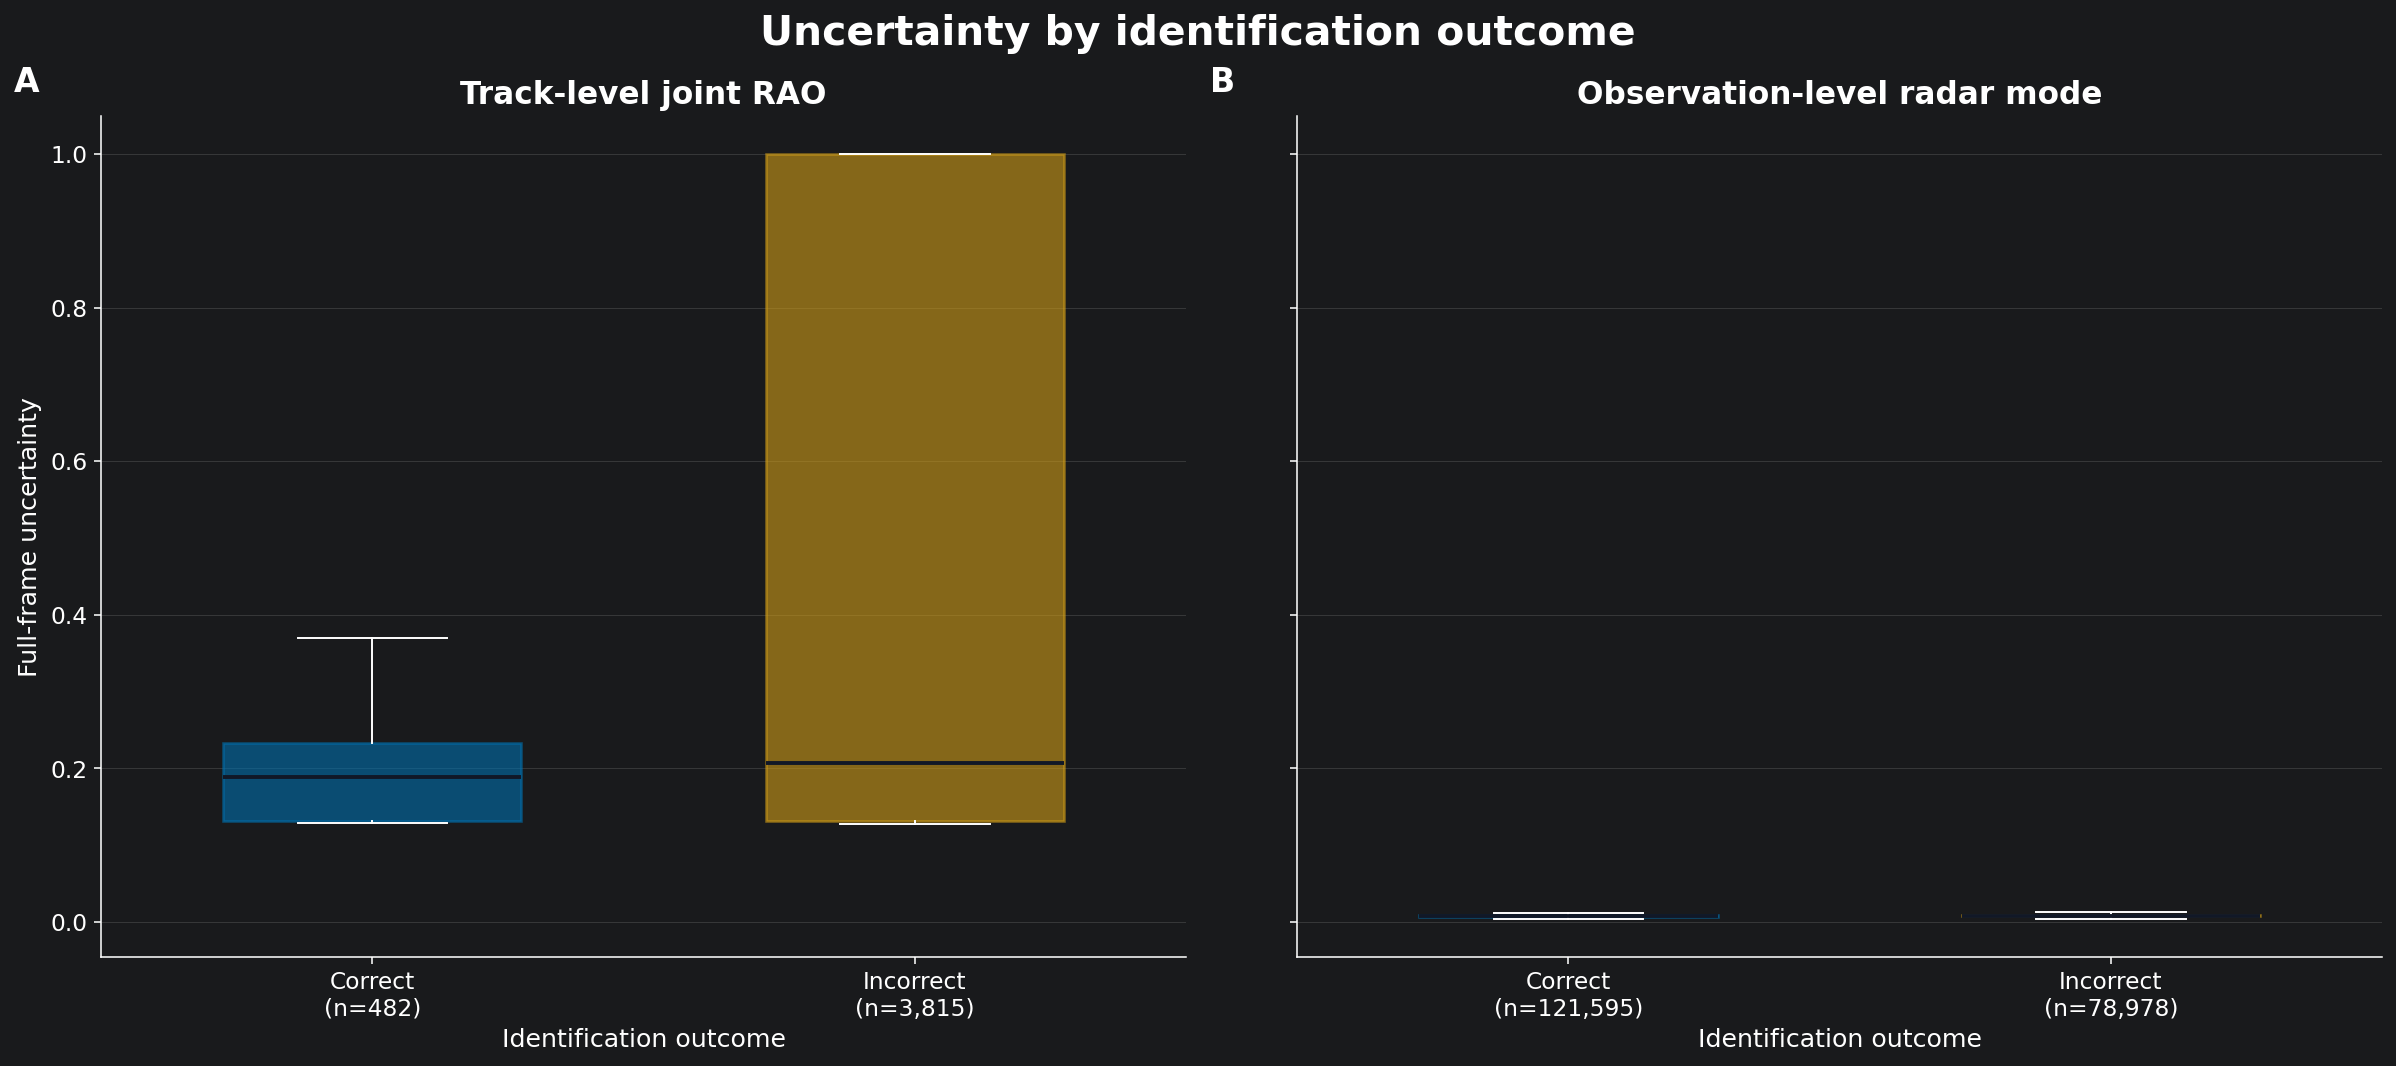

Outcome-specific uncertainty exports:
  C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_identification_uncertainty_by_outcome.png
  C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_identification_uncertainty_by_outcome.pdf
  C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_identification_uncertainty_by_outcome.svg
[timing] Hierarchical evaluation dashboard - part 5 - completed; total time: 2.132 seconds


In [32]:
# Major step: Hierarchical evaluation dashboard - part 5
# Publication-ready uncertainty views for correct and incorrect predictions at each hierarchy level.
OUTCOME_COLOURS = {"correct": "#0072B2", "incorrect": "#D4A017"}
OUTCOME_DPI = 300
outcome_groups = (
    (rao_uncertainty[rao_correct], rao_uncertainty[~rao_correct], "Track-level joint RAO"),
    (mode_uncertainty[mode_correct], mode_uncertainty[~mode_correct], "Observation-level radar mode"),
)
outcome_rc = {
    "figure.dpi": 140, "savefig.dpi": OUTCOME_DPI, "font.family": "sans-serif", "font.size": 12,
    "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 13,
    "axes.spines.top": False, "axes.spines.right": False, "grid.alpha": .20,
    "svg.fonttype": "none", "pdf.fonttype": 42,
}
with plt.rc_context(outcome_rc):
    outcome_figure, outcome_axes = plt.subplots(1, 2, figsize=(17, 7.5), sharey=True, constrained_layout=True)
    for panel_index, (axis, (correct_values, incorrect_values, title)) in enumerate(zip(outcome_axes, outcome_groups)):
        populated = [(correct_values, "Correct", OUTCOME_COLOURS["correct"]), (incorrect_values, "Incorrect", OUTCOME_COLOURS["incorrect"])]
        populated = [item for item in populated if item[0].size]
        if populated:
            boxes = axis.boxplot(
                [item[0] for item in populated], tick_labels=[f"{item[1]}\n(n={item[0].size:,})" for item in populated],
                patch_artist=True, showfliers=False, widths=.55,
                medianprops={"color": "#111827", "linewidth": 2},
            )
            for patch, (_, _, colour) in zip(boxes["boxes"], populated):
                patch.set(facecolor=colour, edgecolor=colour, alpha=.58, linewidth=1.3)
        else:
            axis.text(.5, .5, "No held-out samples", ha="center", va="center", transform=axis.transAxes)
        axis.set(title=title, xlabel="Identification outcome")
        axis.grid(True, axis="y")
        axis.text(-.08, 1.06, chr(65 + panel_index), transform=axis.transAxes, fontsize=17, fontweight="bold", va="top")
    outcome_axes[0].set_ylabel("Full-frame uncertainty")
    outcome_figure.suptitle("Uncertainty by identification outcome", fontsize=21, fontweight="bold")
    outcome_paths = []
    for suffix in ("png", "pdf", "svg"):
        output_path = ARTIFACT_DIR / f"track_identification_uncertainty_by_outcome.{suffix}"
        save_options = {"bbox_inches": "tight", "facecolor": "white"}
        if suffix == "png":
            save_options["dpi"] = OUTCOME_DPI
        outcome_figure.savefig(output_path, **save_options)
        outcome_paths.append(output_path)
    plt.show()
for output_path in outcome_paths:
    mlflow.log_artifact(output_path, artifact_path="dashboards/uncertainty")

print("Outcome-specific uncertainty exports:")
for output_path in outcome_paths:
    print(f"  {output_path}")


### How to read the RAO vacuity–dissonance plots

Each dot is one held-out track's joint RAO opinion. Panel A contains correctly identified tracks and panel B incorrectly identified tracks; both panels share axis limits so their point clouds can be compared directly.

* **Vacuity (horizontal axis)** is the Dirichlet full-frame uncertainty mass. Moving right means less evidence is committed to any specific RAO class.
* **Dissonance (vertical axis)** measures conflict among the belief masses that *are* committed to singleton RAO classes. Moving up means those committed beliefs support competing classes more evenly.

The axes answer different questions: a point can be high-vacuity with little committed belief to conflict, or low-vacuity but high-dissonance because substantial evidence is split among alternatives. Clustering of errors toward the upper or right portions would indicate ambiguity or lack of evidence accompanies mistakes; overlap with correct tracks cautions against treating either quantity as an automatic error label.


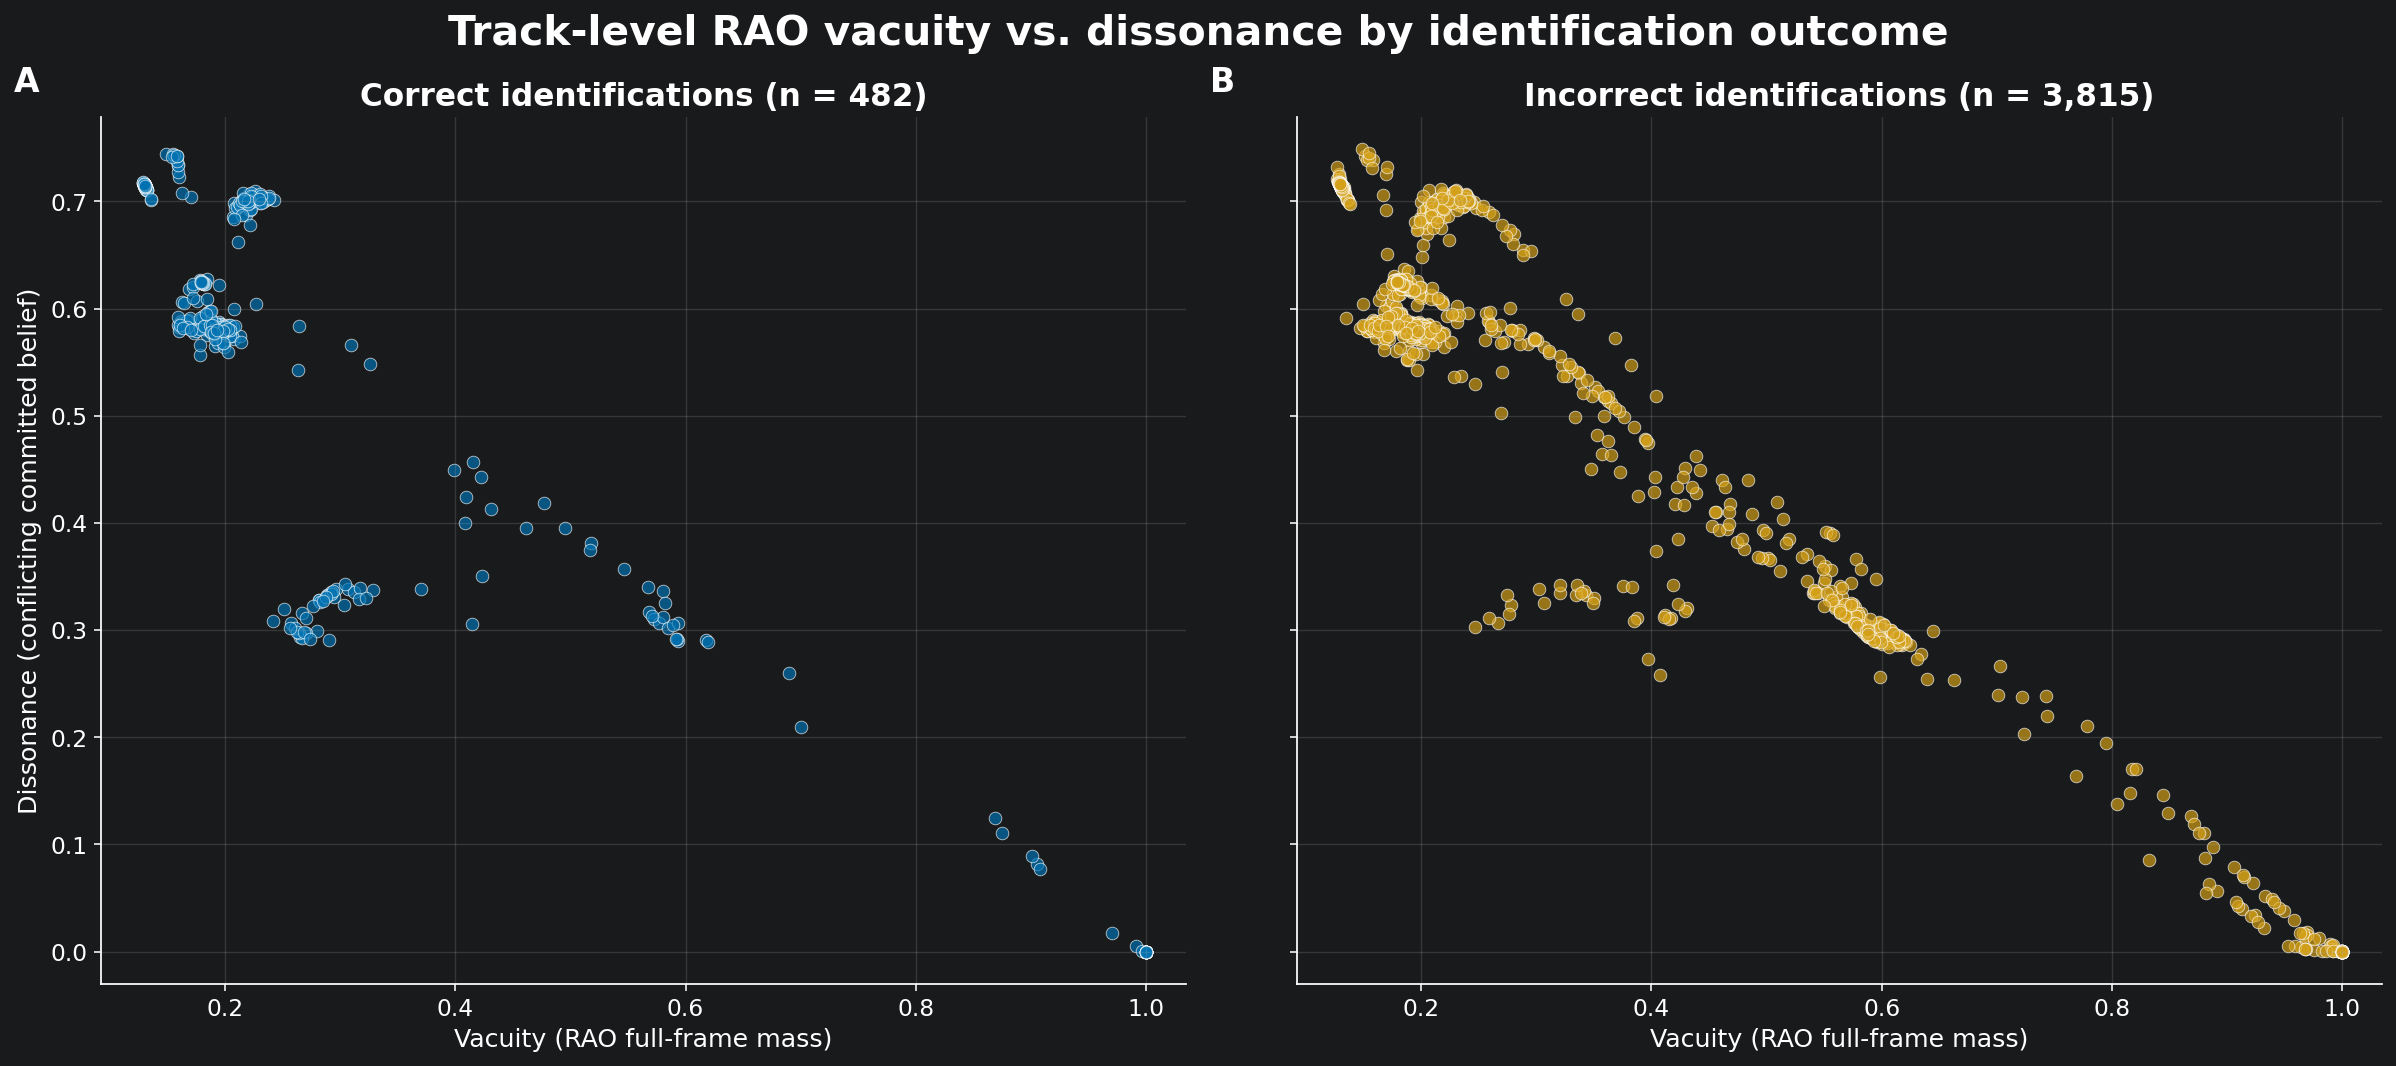

Track-level RAO vacuity–dissonance exports:
  C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_rao_vacuity_vs_dissonance_by_outcome.png
  C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_rao_vacuity_vs_dissonance_by_outcome.pdf
  C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_rao_vacuity_vs_dissonance_by_outcome.svg
[timing] Hierarchical evaluation dashboard - part 6 - completed; total time: 8.790 seconds


In [33]:
# Major step: Hierarchical evaluation dashboard - part 6
# Publication-ready pair: track-level RAO vacuity–dissonance views for correct and incorrect identifications.
# For the Dirichlet opinion, uncertainty is the full-frame mass (vacuity), while
# dissonance measures conflict among the singleton belief masses.
VACUITY_DISSONANCE_COLOURS = {"correct": "#0072B2", "incorrect": "#D4A017"}
VACUITY_DISSONANCE_DPI = 300


def _singleton_dissonance(belief: np.ndarray) -> np.ndarray:
    """Calculate Subjective-Logic dissonance for rows of singleton beliefs."""
    belief = np.asarray(belief, dtype=np.float64)
    if belief.ndim != 2:
        raise ValueError("belief must have shape (samples, classes)")
    dissonance = np.zeros(belief.shape[0], dtype=np.float64)
    for class_index in range(belief.shape[1]):
        focal_belief = belief[:, class_index]
        others = np.delete(belief, class_index, axis=1)
        other_total = others.sum(axis=1)
        balance = np.divide(
            2.0 * np.minimum(focal_belief[:, None], others),
            focal_belief[:, None] + others,
            out=np.zeros_like(others),
            where=(focal_belief[:, None] + others) > 0.0,
        )
        conflict = np.divide(
            (others * balance).sum(axis=1),
            other_total,
            out=np.zeros_like(other_total),
            where=other_total > 0.0,
        )
        dissonance += focal_belief * conflict
    return dissonance


def _padded_limits(values: np.ndarray, minimum_span: float = 0.05) -> tuple[float, float]:
    """Return shared plot limits with enough padding to avoid clipped points."""
    lower, upper = float(np.min(values)), float(np.max(values))
    span = max(upper - lower, minimum_span)
    return lower - 0.04 * span, upper + 0.04 * span


rao_correct = rao_predicted == rao_truth
rao_vacuity = (
    final_outputs["evidential"]["track_rao"]["uncertainty"][test_track_indices]
    .detach().float().cpu().numpy().ravel()
)
rao_belief = (
    final_outputs["evidential"]["track_rao"]["belief"][test_track_indices]
    .detach().float().cpu().numpy()
)
rao_dissonance = _singleton_dissonance(rao_belief)

vacuity_limits = _padded_limits(rao_vacuity)
dissonance_limits = _padded_limits(rao_dissonance)
identification_groups = (
    (rao_correct, "Correct identifications", VACUITY_DISSONANCE_COLOURS["correct"]),
    (~rao_correct, "Incorrect identifications", VACUITY_DISSONANCE_COLOURS["incorrect"]),
)
pair_rc = {
    "figure.dpi": 140, "savefig.dpi": VACUITY_DISSONANCE_DPI,
    "font.family": "sans-serif", "font.size": 12,
    "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.9, "grid.alpha": 0.20, "grid.linewidth": 0.7,
    "svg.fonttype": "none", "pdf.fonttype": 42,
}

with plt.rc_context(pair_rc):
    vacuity_dissonance_figure, vacuity_dissonance_axes = plt.subplots(
        1, 2, figsize=(17, 7.5), sharex=True, sharey=True, constrained_layout=True
    )
    for panel_index, (axis, (selected, title, colour)) in enumerate(
        zip(vacuity_dissonance_axes, identification_groups)
    ):
        group_size = int(np.count_nonzero(selected))
        if group_size:
            axis.scatter(
                rao_vacuity[selected], rao_dissonance[selected],
                s=42, c=colour, alpha=0.68, edgecolors="white",
                linewidths=0.45, rasterized=True,
            )
        else:
            axis.text(
                0.5, 0.5, "No held-out tracks in this group", ha="center", va="center",
                transform=axis.transAxes, color="#667085", fontsize=13,
            )
        axis.set(
            title=f"{title} (n = {group_size:,})",
            xlabel="Vacuity (RAO full-frame mass)",
            xlim=vacuity_limits, ylim=dissonance_limits,
        )
        axis.grid(True)
        axis.text(
            -0.08, 1.06, chr(65 + panel_index), transform=axis.transAxes,
            fontsize=17, fontweight="bold", va="top",
        )
    vacuity_dissonance_axes[0].set_ylabel("Dissonance (conflicting committed belief)")
    vacuity_dissonance_figure.suptitle(
        "Track-level RAO vacuity vs. dissonance by identification outcome",
        fontsize=21, fontweight="bold",
    )

    vacuity_dissonance_paths = []
    for suffix in ("png", "pdf", "svg"):
        output_path = ARTIFACT_DIR / f"track_rao_vacuity_vs_dissonance_by_outcome.{suffix}"
        save_options = {"bbox_inches": "tight", "facecolor": "white"}
        if suffix == "png":
            save_options["dpi"] = VACUITY_DISSONANCE_DPI
        vacuity_dissonance_figure.savefig(output_path, **save_options)
        vacuity_dissonance_paths.append(output_path)
    plt.show()

for output_path in vacuity_dissonance_paths:
    mlflow.log_artifact(output_path, artifact_path="dashboards/uncertainty")

print("Track-level RAO vacuity–dissonance exports:")
for output_path in vacuity_dissonance_paths:
    print(f"  {output_path}")


### How to read the selected-track mode timeline

This interactive plot follows one held-out track in observation order. The title gives the track's single predicted joint RAO tuple; that identity is invariant for the whole timeline. The two lines compare the true and predicted radar-mode class at each observation. Matching markers indicate a correct mode classification, while separated markers show an error; rises or falls indicate true or predicted mode transitions rather than changes in aircraft, radar, or operator.

Predicted-marker size encodes maximum class probability (larger means higher evidential probability), and hover text gives its exact value. Confidence is not the same as evidential full-frame uncertainty and should be interpreted alongside the calibration and uncertainty panels. Numeric mode values are vocabulary indices (`mode_vocab[index]`), and `DASHBOARD_TRACK_INDEX` can select another test track.


In [34]:
# Major step: Hierarchical evaluation dashboard - part 7
# Interactive mode timeline for a selected held-out track.
import plotly.graph_objects as go
DASHBOARD_TRACK_INDEX = int(os.environ.get("DASHBOARD_TRACK_INDEX", str(int(test_track_indices[0]))))
if DASHBOARD_TRACK_INDEX not in set(test_track_indices.tolist()):
    raise ValueError("DASHBOARD_TRACK_INDEX must identify a held-out test track")
positions = np.flatnonzero(observation_track_index.detach().cpu().numpy() == DASHBOARD_TRACK_INDEX)
positions = positions[np.argsort([node_meta[observation_node_indices[p]]["sequence_index"] for p in positions])]
true_modes = mode_targets.detach().cpu().numpy()[positions]
predicted_modes = mode_probabilities.argmax(1)[positions]
confidence = mode_probabilities[positions].max(1)
timeline = go.Figure()
timeline.add_trace(go.Scatter(x=np.arange(len(positions)), y=true_modes, mode="lines+markers", name="True radar mode"))
timeline.add_trace(go.Scatter(x=np.arange(len(positions)), y=predicted_modes, mode="lines+markers", name="Predicted radar mode",
                              marker={"size": 7 + 7 * confidence}, customdata=confidence,
                              hovertemplate="Observation %{x}<br>Mode class %{y}<br>Confidence %{customdata:.3f}<extra></extra>"))
predicted_rao = rao_vocab[int(rao_probabilities[DASHBOARD_TRACK_INDEX].argmax())]
timeline.update_layout(title=f"Track {series_ids[DASHBOARD_TRACK_INDEX]} — invariant RAO: {predicted_rao}",
                       xaxis_title="Ordered observation", yaxis_title="Radar-mode class", template="plotly_white")
timeline_path = ARTIFACT_DIR / "track_mode_timeline.html"
timeline.write_html(timeline_path, include_plotlyjs=True)
mlflow.log_artifact(timeline_path, artifact_path="dashboards")
timeline.show()
print(timeline_path)


C:\Users\theon\r-GCN_fusion\artifacts\track_hgt\track_mode_timeline.html
[timing] Hierarchical evaluation dashboard - part 7 - completed; total time: 0.086 seconds


In [35]:
# Major step: Hierarchical evaluation dashboard - part 8
# Display the track-shaped operational output used by downstream systems.
selected_track_output = track_predictions[DASHBOARD_TRACK_INDEX]
print(json.dumps({"series_id": selected_track_output["series_id"], "rao": selected_track_output["rao"],
                  "rao_invariant": selected_track_output["rao_invariant"],
                  "mode_sequence": [{"sequence_index": item["sequence_index"], "radar_mode": item["radar_mode"]}
                                    for item in selected_track_output["mode_sequence"]]}, indent=2))


{
  "series_id": "esm_series_00001",
  "rao": {
    "aircraft_variant": "F-15EX Eagle II",
    "radar_type": "AN/APG-82(V)1",
    "operator_country": "United States"
  },
  "rao_invariant": true,
  "mode_sequence": [
    {
      "sequence_index": 0,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 1,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 2,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 3,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 4,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 5,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 6,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 7,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 8,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 9,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 10,
      "radar_mode": "OFF"
    },
    {
      "sequence_index": 11,
      "radar_mode": "O

In [36]:
# Major step: Hierarchical evaluation dashboard - RAO_VIOLATION_COUNT
RAO_VIOLATION_COUNT


0

[timing] Hierarchical evaluation dashboard - RAO_VIOLATION_COUNT - completed; total time: 0.002 seconds


In [37]:
# Major step: Hierarchical evaluation dashboard - summary
summary


{'checkpoint_selection': {'metric': 'test_loss',
  'epoch': 12,
  'value': 7.800729883419017,
  'path': 'C:\\Users\\theon\\r-GCN_fusion\\artifacts\\track_hgt\\best_track_model.pt'},
 'model_config': {'architecture': 'track_minibatched_rgcn_pyg_hgt',
  'hgt_node_type': 'node',
  'hgt_conv': 'torch_geometric.nn.HGTConv',
  'maximum_hidden_dim': 150,
  'minimum_hidden_dim': 100,
  'num_message_passing_edges': 15,
  'num_rgcn_bases': 6,
  'num_hgt_layers': 3,
  'num_attention_heads': 4,
  'dropout': 0.35,
  'task_head_hidden_dim': 100,
  'rao_classes': 122,
  'radar_mode_classes': 6,
  'tracks_per_batch': 4,
  'claim_candidate_min_abs_contribution': 0.15,
  'reciprocal_claim_candidate_edges': False,
  'rao_invariance': 'one pooled output per series_id',
  'mode_conditioning': 'local observation + pooled track + evidential-mean KG compatibility',
  'prediction_heads': 'evidential_only',
  'rao_base_rate_multiplier': 10.0,
  'rao_prior_weight': 122,
  'mode_base_rate': 'uniform'},
 'metrics'

[timing] Hierarchical evaluation dashboard - summary - completed; total time: 0.004 seconds


## Evidence-grounded LLM explanation of the partial track identification

Choose a track with `LLM_TRACK_INDEX` (default `0`). The prompt receives the shared credible-world projection and must state only supported, non-null assertions at their declared resolution. It may explain alternatives but cannot promote a type to a variant or treat the compatibility argmax tuple as an operational assertion. Held-out truth is attached only after generation.


In [38]:
# Major step: Evidence-grounded LLM explanation of the track-level RAO assessment
EXTREME_UNCERTAINTY = 0.60
HIGH_UNCERTAINTY = 0.35
OLLAMA_BASE_URL = os.environ.get("OLLAMA_BASE_URL", "http://localhost:11434").rstrip("/")
OLLAMA_MODEL = os.environ.get("OLLAMA_MODEL", "qwen3.5:9b")
OLLAMA_TIMEOUT_SECONDS = float(os.environ.get("OLLAMA_TIMEOUT_SECONDS", "120"))
OLLAMA_NUM_PREDICT = int(os.environ.get("OLLAMA_NUM_PREDICT", "384"))
LLM_TRACK_INDEX = int(os.environ.get("LLM_TRACK_INDEX", "0"))
if not -len(track_predictions) <= LLM_TRACK_INDEX < len(track_predictions):
    raise IndexError("LLM_TRACK_INDEX is outside the available track results")

def build_track_explanation_evidence(track_position):
    record = track_predictions[track_position]
    rao_uncertainty = float(record["rao_evidence"]["full_frame_uncertainty"])
    return {
        "series_id": record["series_id"],
        "partial_identification": record["identification"],
        "decision_tuple_for_dashboard_compatibility_only": record["rao"],
        "rao_evidence": record["rao_evidence"],
        "model_constraint": "Every published attribute is projected from one shared set of KG-valid track worlds; null means unresolved, not absent.",
        "evidence_assessment": {"rao_uncertainty": rao_uncertainty,
            "band": "extreme" if rao_uncertainty >= EXTREME_UNCERTAINTY else "limited" if rao_uncertainty >= HIGH_UNCERTAINTY else "supported",
            "active_collection_required": rao_uncertainty >= EXTREME_UNCERTAINTY},
    }

def explanation_prompt(packet):
    return f"""You are an electronic-support analyst. Explain only the supplied track-level aircraft/radar/operator (RAO) evidence.
State only the non-null assertions in partial_identification. Use their declared resolution level: never promote an aircraft type to a variant, and never use the dashboard compatibility tuple as an asserted identity. Explain unresolved fields and their supplied alternatives without choosing among them. Never imply that aircraft, radar, or operator changes between observations.
Do not explain, justify, summarize, or infer any observation-level radar-mode assignment or mode transition; radar mode is outside the scope of this explanation.
For the RAO assessment, belief is committed singleton mass, plausibility includes full-frame ignorance, and base-rate-weighted projected probability is a decision probability rather than new evidence.
Do not invent facts. If the RAO evidence band is extreme, state that the identification is not decision-grade and recommend additional time-linked ESM and corroborating intelligence, including active radar collection when operationally appropriate.
Return a concise paragraph followed by Supported assertions, Unresolved attributes, Evidence uncertainty, and Recommended action bullets.

TRACK EVIDENCE JSON:
{json.dumps(packet, indent=2)}"""

def ollama_generate(prompt):
    parsed = urllib.parse.urlsplit(OLLAMA_BASE_URL)
    if parsed.scheme not in {"http", "https"} or parsed.hostname not in {"localhost", "127.0.0.1", "::1"}:
        raise ValueError("OLLAMA_BASE_URL must target a loopback-only Ollama instance")
    payload = json.dumps({"model": OLLAMA_MODEL, "prompt": prompt, "think": False, "stream": False,
                          "keep_alive": "10m", "options": {"temperature": 0.1, "num_predict": OLLAMA_NUM_PREDICT}}).encode()
    request = urllib.request.Request(f"{OLLAMA_BASE_URL}/api/generate", data=payload,
                                     headers={"Content-Type": "application/json"}, method="POST")
    try:
        with urllib.request.urlopen(request, timeout=OLLAMA_TIMEOUT_SECONDS) as response:
            result = json.loads(response.read().decode())
    except urllib.error.URLError as error:
        raise RuntimeError(f"Unable to call local Ollama at {OLLAMA_BASE_URL}; start Ollama and pull {OLLAMA_MODEL!r}") from error
    explanation = result.get("response")
    if not isinstance(explanation, str) or not explanation.strip():
        raise RuntimeError(f"Ollama returned no explanation: {result}")
    return explanation.strip()

def explain_track(track_position):
    packet = build_track_explanation_evidence(track_position)
    prompt = explanation_prompt(packet)
    explanation = ollama_generate(prompt)
    if packet["evidence_assessment"]["active_collection_required"]:
        required = "Identification is not decision-grade; obtain additional time-linked ESM and corroborating intelligence, including active radar collection when operationally appropriate."
        if required not in explanation: explanation += f"\n\nRecommended action: {required}"
    return {"series_id": packet["series_id"], "correct_track_identification": track_targets_by_series_id[packet["series_id"]],
            "ollama_model": OLLAMA_MODEL, "evidence": packet, "prompt": prompt, "explanation": explanation}

track_explanation = explain_track(LLM_TRACK_INDEX)
explanation_path = ARTIFACT_DIR / f"llm_track_explanation_{LLM_TRACK_INDEX}.json"
explanation_path.write_text(json.dumps(track_explanation, indent=2), encoding="utf-8")
print(track_explanation["explanation"])
print("\nCorrect held-out track identification (not supplied to the LLM):")
print(json.dumps(track_explanation["correct_track_identification"], indent=2))
print(explanation_path)


The supplied track-level evidence indicates an extreme uncertainty band with a full-frame unknown mass of approximately 0.99999994, rendering the identification non-decision-grade. The partial identification asserts null values for aircraft variant, type, radar type, and operator country due to a credible set that is too large, preventing resolution at any specific level. Leading hypotheses distribute probability across combinations including an F-16C/D Block 50 with an AN/APG-68 radar operated by Poland or Greece, alongside an F-15EX Eagle II with an AN/APG-82(V)1 radar operated by the United States; however, these remain probabilistic projections rather than confirmed identities. The dashboard compatibility tuple (F-15EX Eagle II, AN/APG-82(V)1, United States) is strictly for compatibility and must not be treated as an asserted identity. Given the extreme uncertainty and insufficient coverage, active collection is required to reduce the credible set size before a definitive assessmen

WindowsPath('C:/Users/theon/r-GCN_fusion/artifacts/track_hgt/hierarchical_training_metrics.png')

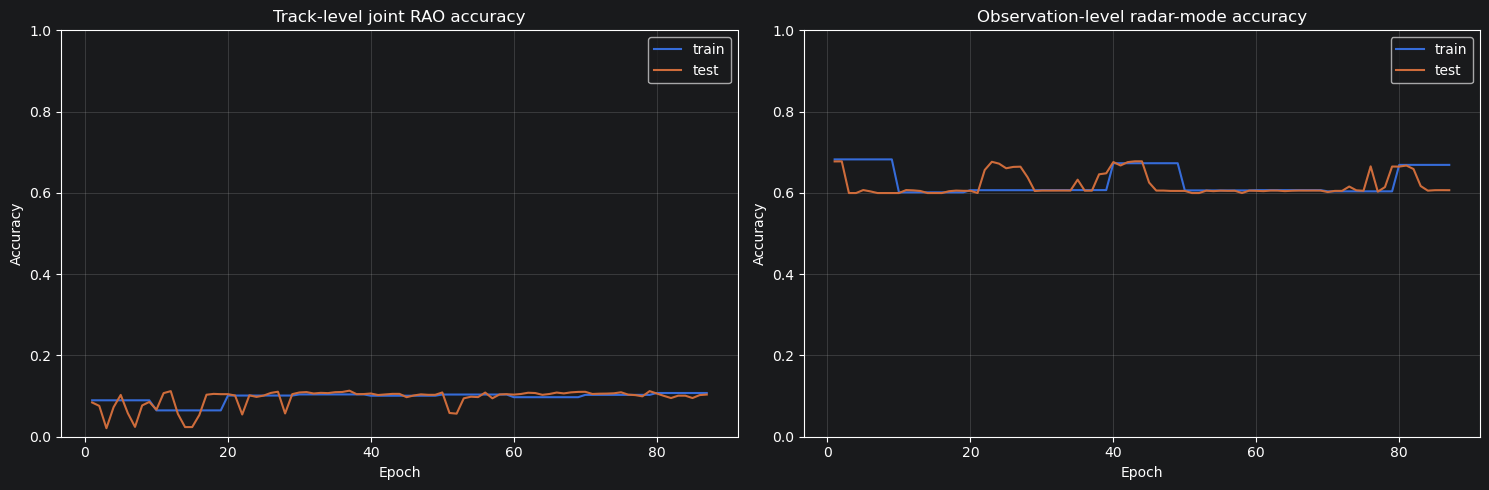

[timing] Evidence-grounded LLM explanation of the track-level RAO assessment - part 2 - completed; total time: 0.376 seconds


In [39]:
# Major step: Evidence-grounded LLM explanation of the track-level RAO assessment - part 2
# Training curves for the two prediction levels.
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for split in ("train", "test"):
    axes[0].plot(epochs, [row[f"{split}_track_rao_acc"] for row in history], label=split)
    axes[1].plot(epochs, [row[f"{split}_radar_mode_acc"] for row in history], label=split)
axes[0].set(title="Track-level joint RAO accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
axes[1].set(title="Observation-level radar-mode accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
for axis in axes: axis.legend(); axis.grid(True, alpha=.3)
fig.tight_layout()
training_plot_path = ARTIFACT_DIR / "hierarchical_training_metrics.png"
fig.savefig(training_plot_path, dpi=150)
mlflow.log_artifact(training_plot_path, artifact_path="training")
mlflow.end_run(status="FINISHED")
training_plot_path


[timing] Unnamed notebook step - completed; total time: 0.000 seconds


[timing] Unnamed notebook step - completed; total time: 0.000 seconds


[timing] Unnamed notebook step - completed; total time: 0.000 seconds
